# **Proyecto Big Data · Amazon Books Reviews · Metodología CRISP-DM**


### **Juan Sebastián Kure Bermeo, María José Martínez Villabona y Sara Juliana Solano Boada**


### **a. Identifique el conjunto de datos y defina el objetivo de análisis y la unidad de análisis**

| | |
|---|---|
| **Fuente** | Kaggle – *Amazon Books Reviews* (mohamedbakhet), derivado de los datos de reseñas de Amazon (McAuley, UCSD) |
| **Archivos** | `Books_rating.csv` (reseñas) y `books_data.csv` (metadatos de libros de Google Books) |
| **Objetivo de análisis** | Identificar qué características del libro y de la reseña se asocian con la **insatisfacción del lector**, para orientar decisiones de catálogo y promoción |
| **Unidad de análisis** | La **reseña** individual (un usuario califica un libro en un momento dado) |
| **Variable objetivo** | `is_negative` = 1 si `review/score` ≤ 2 |


Los datos, de acuerdo con la página en la que están alojados (https://www.kaggle.com/datasets/mohamedbakhet/amazon-books-reviews), tienen la siguiente estructura:

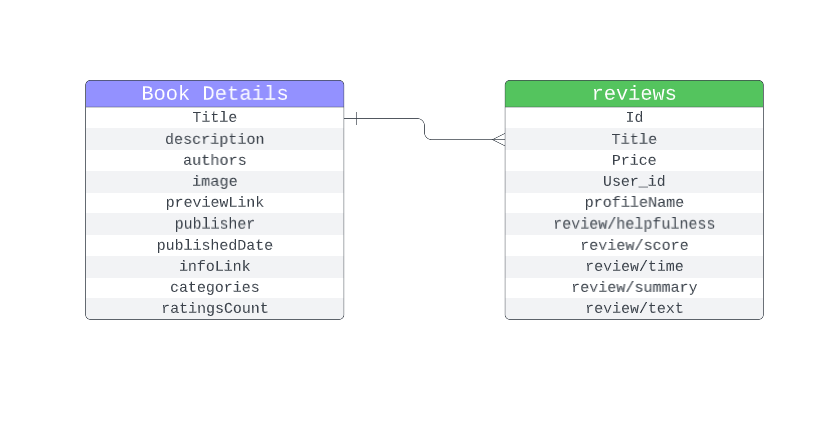

Se usó el conjunto Amazon Books Reviews, publicado en Kaggle, que reúne reseñas de libros escritas por usuarios de Amazon entre 1995 y 2013, puesto que es una base de datos interesante, de un sitio web que puede que muchos de nosotros usemos, y que su analisis resulta atractivo en la actualidad. Si bien, no contiene datos precisamente de Colombia, su análisis puede tener una utilidad alta en el mundo de los libros y las plataformas que lo distribuyen, y que, de un modo u otro pueden estar muy cercanos a nosotros.

 Viene en dos archivos que se conectan por el título del libro:

- **Books_rating.csv (2,86 GB):** 3.000.000 de reseñas con 10 columnas. Cada fila es una reseña: el libro (identificador y título), el usuario que la escribió (identificador y nombre), la calificación de 1 a 5 estrellas, la fecha, un resumen corto, el texto completo, el precio del libro y los votos de utilidad que recibió de otros lectores (por ejemplo, "7/10": 7 de 10 personas la consideraron útil).
- **books_data.csv (0,18 GB):** información de 212.404 libros, tomada de Google Books, con 10 columnas: título, descripción, autores, editorial, fecha de publicación, categorías, número de calificaciones y enlaces a la imagen y a la ficha del libro.

Es una base grande y con varios problemas de calidad: el 30,9 % de las reseñas aparece repetido (Amazon registra la misma reseña para cada edición de un libro), el precio falta en el 84 % de las filas y muchos libros no tienen categoría, autor o editorial. Después de la limpieza quedaron 2.072.049 reseñas únicas de cerca de 199.000 libros, que son la base de todo el análisis.

### **b. Comprensión de los datos (EDA) con Dask**

In [2]:
import dask.dataframe as dd
from pathlib import Path

# Rutas relativas a la carpeta del proyecto (los CSV originales van en data/raw/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS_RAW = RAIZ / "data" / "raw"
DATOS_SILVER = RAIZ / "data" / "silver"

ruta = (DATOS_RAW / "Books_rating.csv").as_posix()
ruta2 = (DATOS_RAW / "books_data.csv").as_posix()
rev = dd.read_csv(ruta, blocksize="64MB", dtype={"Id": "str"})
books = dd.read_csv(ruta2, blocksize="64MB")

#### - Preliminar:
En primer lugar, hacemos una lectura rapida de los datos que tenemos, sus campos, lonigtudes, primeras filas, etc.

In [3]:
print(rev.npartitions)  
print(rev.columns)       
print(rev.dtypes)     
rev.head()
       

44
Index(['Id', 'Title', 'Price', 'User_id', 'profileName', 'review/helpfulness',
       'review/score', 'review/time', 'review/summary', 'review/text'],
      dtype='str')
Id                     string
Title                  string
Price                 float64
User_id                string
profileName            string
review/helpfulness     string
review/score          float64
review/time             int64
review/summary         string
review/text            string
dtype: object


,Id,Title,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text
0,1882931173,Its Only Art If Its Well Hung!,NaN,AVCGYZL8FQQTD,"Jim of Oz ""jim-of-oz""",7/7,4.0,940636800,Nice collection of Julie Strain images,This is only for Julie Strain fans. It's a col...
1,0826414346,Dr. Seuss: American Icon,NaN,A30TK6U7DNS82R,Kevin Killian,10/10,5.0,1095724800,Really Enjoyed It,I don't care much for Dr. Seuss but after read...
2,0826414346,Dr. Seuss: American Icon,NaN,A3UH4UZ4RSVO82,John Granger,10/11,5.0,1078790400,Essential for every personal and Public Library,"If people become the books they read and if ""t..."
3,0826414346,Dr. Seuss: American Icon,NaN,A2MVUWT453QH61,"Roy E. Perry ""amateur philosopher""",7/7,4.0,1090713600,Phlip Nel gives silly Seuss a serious treatment,"Theodore Seuss Geisel (1904-1991), aka &quot;D..."
4,0826414346,Dr. Seuss: American Icon,NaN,A22X4XUPKF66MR,"D. H. Richards ""ninthwavestore""",3/3,4.0,1107993600,Good academic overview,Philip Nel - Dr. Seuss: American IconThis is b...


In [4]:
print(books.npartitions)   
print(books.columns)       
print(books.dtypes)   
books.head()

2
Index(['Title', 'description', 'authors', 'image', 'previewLink', 'publisher',
       'publishedDate', 'infoLink', 'categories', 'ratingsCount'],
      dtype='str')
Title             string
description       string
authors           string
image             string
previewLink       string
publisher         string
publishedDate     string
infoLink          string
categories        string
ratingsCount     float64
dtype: object


,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount
0,Its Only Art If Its Well Hung!,<NA>,['Julie Strain'],http://books.google.com/books/content?id=DykPA...,http://books.google.nl/books?id=DykPAAAACAAJ&d...,<NA>,1996,http://books.google.nl/books?id=DykPAAAACAAJ&d...,['Comics & Graphic Novels'],NaN
1,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN
2,Wonderful Worship in Smaller Churches,This resource includes twelve principles in un...,['David R. Ray'],http://books.google.com/books/content?id=2tsDA...,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,<NA>,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,['Religion'],NaN
3,Whispers of the Wicked Saints,Julia Thomas finds her life spinning out of co...,['Veronica Haddon'],http://books.google.com/books/content?id=aRSIg...,http://books.google.nl/books?id=aRSIgJlq6JwC&d...,iUniverse,2005-02,http://books.google.nl/books?id=aRSIgJlq6JwC&d...,['Fiction'],NaN
4,"Nation Dance: Religion, Identity and Cultural ...",<NA>,['Edward Long'],<NA>,http://books.google.nl/books?id=399SPgAACAAJ&d...,<NA>,2003-03-01,http://books.google.nl/books?id=399SPgAACAAJ&d...,<NA>,NaN


Como se puede observar, los datos realmente pesan mas de 1.5GB:

In [5]:
from pathlib import Path
import pandas as pd

tam_gb = Path(ruta).stat().st_size / 1e9
tam2_gb = Path(ruta2).stat().st_size / 1e9
print(f"Books_data.csv pesa {tam2_gb:.2f} GB")
print(f"Books_rating.csv pesa {tam_gb:.2f} GB")

Books_data.csv pesa 0.18 GB
Books_rating.csv pesa 2.86 GB


Finalmente, se normalizan las columnas de ambas tablas, dejando sus nombres en minusculas, y quitandole carácteres especiales (por ej: /). El proceso se muestra a continuación:

In [6]:
rev = rev.rename(columns={
    "Id": "rev_id",
    "Title": "title",
    "Price": "price",
    "User_id": "user_id",
    "profileName": "profile_name",
    "review/helpfulness": "helpfulness",
    "review/score": "score",
    "review/time": "review_time",
    "review/summary": "summary",
    "review/text": "text",
})
rev.columns

Index(['rev_id', 'title', 'price', 'user_id', 'profile_name', 'helpfulness',
       'score', 'review_time', 'summary', 'text'],
      dtype='str')

In [7]:
books = books.rename(columns={
    "Title": "title",
    "previewLink": "preview_link",
    "publishedDate": "published_date",
    "infoLink": "info_link",
    "ratingsCount": "ratings_count",
})
books.columns

Index(['title', 'description', 'authors', 'image', 'preview_link', 'publisher',
       'published_date', 'info_link', 'categories', 'ratings_count'],
      dtype='str')

#### - Tipos de datos:

In [8]:
tipos = pd.DataFrame({"dtype": rev.dtypes.astype(str)})
tipos["tipo_analitico"] = [
    "identificador",                  # Id (ISBN)
    "texto/categórica",               # Title
    "numérica continua",              # Price
    "identificador",                  # User_id
    "texto",                          # profileName
    "texto 'x/y' (requiere parseo)",  # review/helpfulness
    "numérica ordinal (1-5)",         # review/score
    "fecha (Unix)",                   # review/time
    "texto corto",                    # review/summary
    "texto largo",                    # review/text
]
tipos

,dtype,tipo_analitico
rev_id,string,identificador
title,string,texto/categórica
price,float64,numérica continua
user_id,string,identificador
profile_name,string,texto
helpfulness,string,texto 'x/y' (requiere parseo)
score,float64,numérica ordinal (1-5)
review_time,int64,fecha (Unix)
summary,string,texto corto
text,string,texto largo


In [9]:
tipos_data = pd.DataFrame({"dtype": books.dtypes.astype(str)})
tipos_data["tipo_analitico"] = [
    "texto/categórica",                
    "texto",               
    "texto",             
    "identificador",               
    "texto",                          
    "texto",  
    "fecha (string)",         
    "texto",                  
    "texto / categórica",                    
    "numérica",                   
]
tipos_data

,dtype,tipo_analitico
title,string,texto/categórica
description,string,texto
authors,string,texto
image,string,identificador
preview_link,string,texto
publisher,string,texto
published_date,string,fecha (string)
info_link,string,texto
categories,string,texto / categórica
ratings_count,float64,numérica


Como se observa, ambas tablas tienen diferentes columnas, de distintos tupos. Ambas están conectadas por medio de la columna "title", 

### - Valores Faltantes

In [10]:
n_filas = len(rev)   # si ya lo calculaste antes, no lo repitas

nulos_n = rev.isna().sum().compute()
nulos = pd.DataFrame({
    "nulos": nulos_n,
    "% nulos": nulos_n / n_filas * 100,
}).sort_values("% nulos", ascending=False)
nulos

,nulos,% nulos
price,2518829,83.960967
profile_name,561905,18.730167
user_id,561787,18.726233
summary,407,0.013567
title,208,0.006933
text,8,0.000267
rev_id,0,0.000000
helpfulness,0,0.000000
review_time,0,0.000000
score,0,0.000000


In [11]:
books_filas = len(books) 

nulos_books = books.isna().sum().compute()
nulosb = pd.DataFrame({
    "nulos": nulos_books,
    "% nulos": nulos_books / books_filas * 100,
}).sort_values("% nulos", ascending=False)
nulosb

,nulos,% nulos
ratings_count,162652,76.576712
publisher,75886,35.727199
description,68442,32.222557
image,52075,24.516958
categories,41199,19.396527
authors,31413,14.789270
published_date,25305,11.913617
preview_link,23836,11.222011
info_link,23836,11.222011
title,1,0.000471


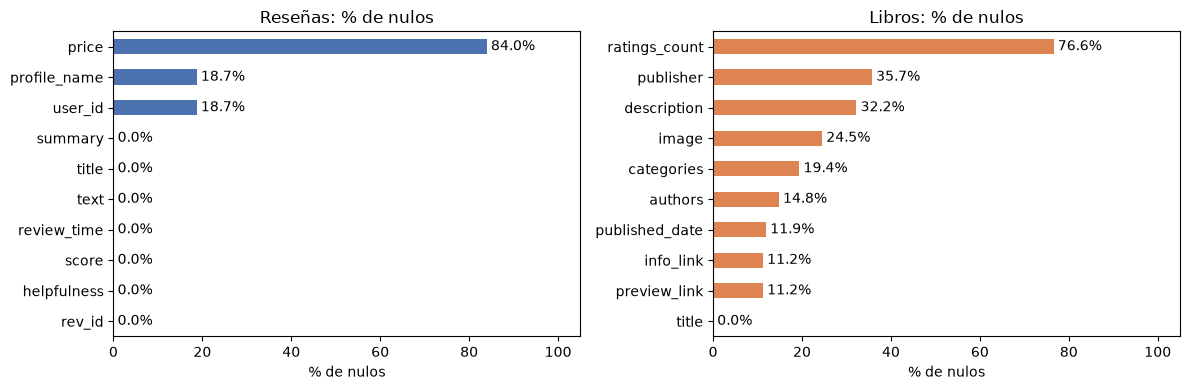

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

nulos["% nulos"].sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Reseñas: % de nulos")
ax[0].set_xlabel("% de nulos")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%", padding=3)
ax[0].set_xlim(0, 105)

nulosb["% nulos"].sort_values().plot.barh(ax=ax[1], color="#DD8452")
ax[1].set_title("Libros: % de nulos")
ax[1].set_xlabel("% de nulos")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", padding=3)
ax[1].set_xlim(0, 105)

plt.tight_layout()
plt.show()

La tabla de reviews presenta un gran porcentaje de nulos en la columna "price" (83.96%), seguida de profile_name" y "user_id" (18.73%). Este fenómeno puede darse debido a reseñas realizadas de manera anónima, o de personas que no tengan un usuario o cuenta registrada en Amazon.


Por otro lado, la tabla de Books tiene la mayoría de sus campos con algún porcentaje de nulos. Entre los principales se encuentra: 
- "ratings_count" (76.57%)
- "publisher" (35.72%)
- "description" (32.22%)

Lo anterior puede deberse a la publicación del libro, donde muchas veces no se agrega una descripción, autor o diferente información del libro. Y, sobre "ratingsCount", este campo hace referncia a la calificación promedio del libro, por lo que es habitual que existan libros que no tengan calificaciones (no son muy conocidos o son muy nuevos)

### - Limpieza

**Books**

Con lo anterior claro, es necesario hacer la limpieza de la base de datos. Para esto, examinamos las variables que podrían determinar el comportamiento de un score bajo en la tabla Books:

In [13]:
libros_pd = books.compute()
libros_pd[["title", "authors", "categories", "published_date", "publisher"]].head(10)

,title,authors,categories,published_date,publisher
0,Its Only Art If Its Well Hung!,['Julie Strain'],['Comics & Graphic Novels'],1996,<NA>
1,Dr. Seuss: American Icon,['Philip Nel'],['Biography & Autobiography'],2005-01-01,A&C Black
2,Wonderful Worship in Smaller Churches,['David R. Ray'],['Religion'],2000,<NA>
3,Whispers of the Wicked Saints,['Veronica Haddon'],['Fiction'],2005-02,iUniverse
4,"Nation Dance: Religion, Identity and Cultural ...",['Edward Long'],<NA>,2003-03-01,<NA>
5,The Church of Christ: A Biblical Ecclesiology ...,['Everett Ferguson'],['Religion'],1996,Wm. B. Eerdmans Publishing
6,The Overbury affair (Avon),['Miriam Allen De Ford'],<NA>,1960,<NA>
7,A Walk in the Woods: a Play in Two Acts,['Lee Blessing'],<NA>,1988,<NA>
8,Saint Hyacinth of Poland,['Mary Fabyan Windeatt'],['Biography & Autobiography'],2009-01-01,Tan Books & Pub
9,Rising Sons and Daughters: Life Among Japan's ...,['Steven Wardell'],['Social Science'],1995,Plympton PressIntl


In [14]:
for col in ["authors", "categories", "publisher"]:
    print(col, "->", libros_pd[col].nunique(), "valores distintos")

authors -> 127278 valores distintos
categories -> 10883 valores distintos
publisher -> 16016 valores distintos


Viendo la estructura de los registros, para una mejor comprensión y visualización, normalizamos algunas columnas:

**Categories**

Quitamos los caracteres [''], dejando como columna limpia a **main_category**

In [15]:
patron = r"\[['\"](.+?)['\"][,\]]"

libros_pd["main_category"] = libros_pd["categories"].str.extract(patron)[0]
libros_pd["main_author"] = libros_pd["authors"].str.extract(patron)[0]

libros_pd[["categories", "main_category", "authors", "main_author"]].head(10)

,categories,main_category,authors,main_author
0,['Comics & Graphic Novels'],Comics & Graphic Novels,['Julie Strain'],Julie Strain
1,['Biography & Autobiography'],Biography & Autobiography,['Philip Nel'],Philip Nel
2,['Religion'],Religion,['David R. Ray'],David R. Ray
3,['Fiction'],Fiction,['Veronica Haddon'],Veronica Haddon
4,<NA>,<NA>,['Edward Long'],Edward Long
5,['Religion'],Religion,['Everett Ferguson'],Everett Ferguson
6,<NA>,<NA>,['Miriam Allen De Ford'],Miriam Allen De Ford
7,<NA>,<NA>,['Lee Blessing'],Lee Blessing
8,['Biography & Autobiography'],Biography & Autobiography,['Mary Fabyan Windeatt'],Mary Fabyan Windeatt
9,['Social Science'],Social Science,['Steven Wardell'],Steven Wardell


In [16]:
print(libros_pd["categories"].isna().sum(), libros_pd["main_category"].isna().sum())
#Vemos que no se perdieron datos al normalizar

41199 41199


**Publisher y title**

Normalizamos con minusculas

In [17]:
libros_pd["publisher_clean"] = libros_pd["publisher"].str.strip().str.lower()
libros_pd["title_norm"] = libros_pd["title"].str.lower().str.strip()

**Published_date**

Se extrae el año de publicación (los primeros 4 caracteres de la fecha):

In [18]:
libros_pd["published_year"] = pd.to_numeric(
    libros_pd["published_date"].str[:4], errors="coerce"
)

Al revisar el rango de `published_year` aparece un valor imposible: el año **1016**. Se identifica a qué libro corresponde:

In [19]:
libros_pd.loc[libros_pd["published_year"] < 1500, ["title", "main_author", "published_date", "published_year"]]

,title,main_author,published_date,published_year
61054,MANSIONS OF DARKNESS,Archie Roy,1016-10-11,1016


Se detecta que el título correspondiente al año 1016 es "Mansions of Darkness" de Archie Roy. Se valida si este año es correcto en la web:

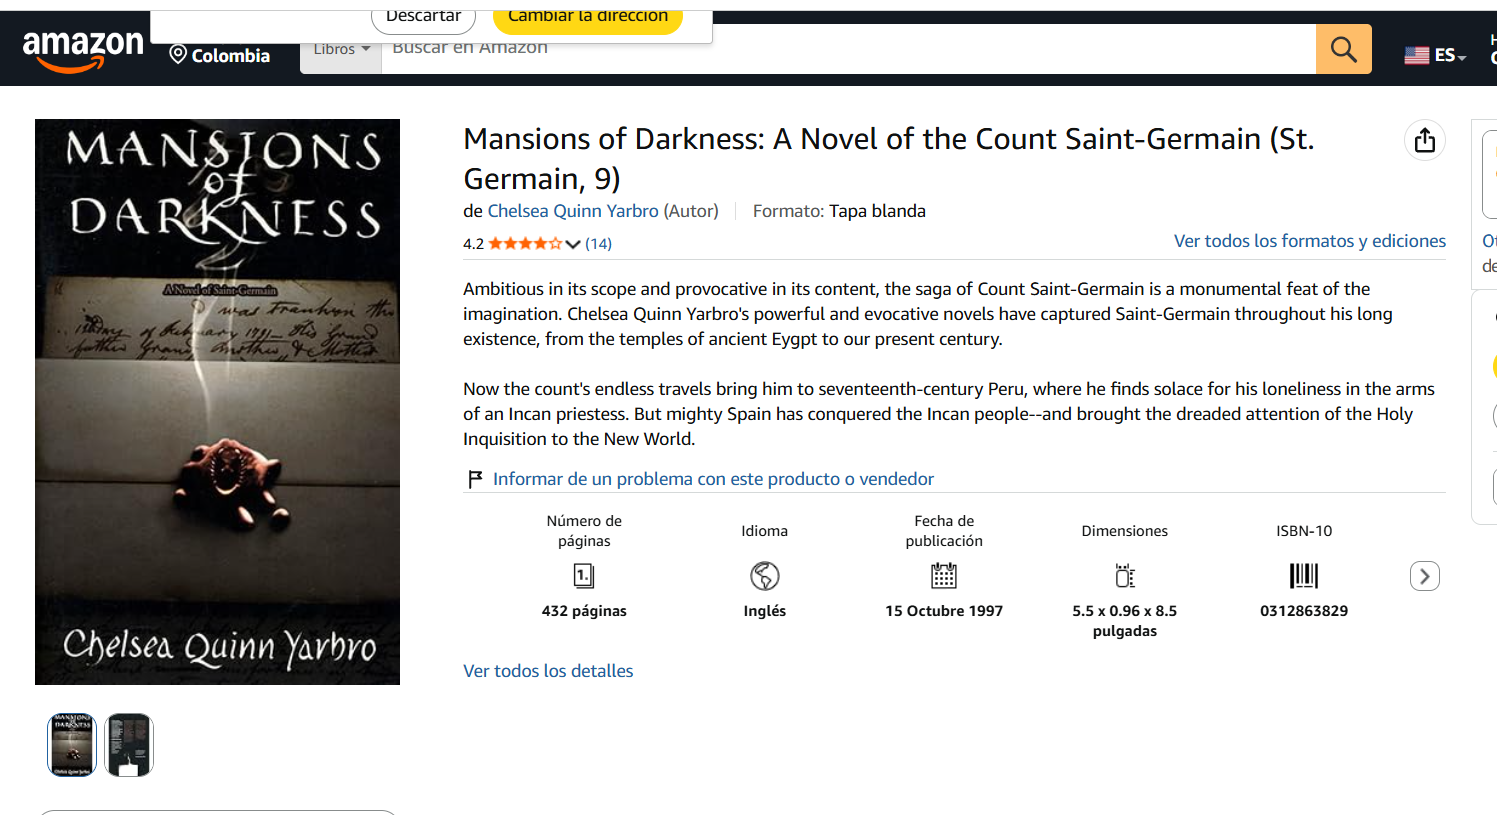

Como se observa, el dato del año es erróneo, así que se corrige en esta etapa de limpieza (pasa de 1016 a 1996):

In [20]:
libros_pd.loc[libros_pd["published_year"] == 1016, "published_year"] = 1996
print("Año mínimo de publicación tras la corrección:", libros_pd["published_year"].min())

Año mínimo de publicación tras la corrección: 1526


**Limpieza**

Finalmente, rellenamos los datos nulos de categoria, autor y editorial con "Desconocido" y agrupamos las categorias menos repetidas en “Otros”

In [21]:
for col in ["main_category", "main_author", "publisher_clean"]:
    libros_pd[col] = libros_pd[col].fillna("Desconocido")

top_cat = libros_pd["main_category"].value_counts().head(30).index
libros_pd["category_group"] = libros_pd["main_category"].where(
    libros_pd["main_category"].isin(top_cat), "Otros"
)

libros_pd["category_group"].value_counts(normalize=True) * 100

category_group
Otros                          27.569631
Desconocido                    19.396527
Fiction                        11.025687
Religion                        4.453306
History                         4.392573
Juvenile Fiction                3.127531
Biography & Autobiography       2.977345
Business & Economics            2.648255
Computers                       2.030094
Social Science                  1.805051
Juvenile Nonfiction              1.62238
Science                         1.234911
Education                       1.229261
Cooking                         1.151108
Sports & Recreation             1.067306
Family & Relationships          1.025404
Literary Criticism               1.01081
Music                           0.991507
Medical                         0.978795
Art                             0.967025
Body, Mind & Spirit             0.964671
Language Arts & Disciplines     0.958551
Health & Fitness                0.955726
Political Science               0.920416
P

In [22]:
libros_pd.head(10)

,title,description,authors,image,preview_link,publisher,published_date,info_link,categories,ratings_count,main_category,main_author,publisher_clean,title_norm,published_year,category_group
0,Its Only Art If Its Well Hung!,<NA>,['Julie Strain'],http://books.google.com/books/content?id=DykPA...,http://books.google.nl/books?id=DykPAAAACAAJ&d...,<NA>,1996,http://books.google.nl/books?id=DykPAAAACAAJ&d...,['Comics & Graphic Novels'],NaN,Comics & Graphic Novels,Julie Strain,Desconocido,its only art if its well hung!,1996,Otros
1,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN,Biography & Autobiography,Philip Nel,a&c black,dr. seuss: american icon,2005,Biography & Autobiography
2,Wonderful Worship in Smaller Churches,This resource includes twelve principles in un...,['David R. Ray'],http://books.google.com/books/content?id=2tsDA...,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,<NA>,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,['Religion'],NaN,Religion,David R. Ray,Desconocido,wonderful worship in smaller churches,2000,Religion
3,Whispers of the Wicked Saints,Julia Thomas finds her life spinning out of co...,['Veronica Haddon'],http://books.google.com/books/content?id=aRSIg...,http://books.google.nl/books?id=aRSIgJlq6JwC&d...,iUniverse,2005-02,http://books.google.nl/books?id=aRSIgJlq6JwC&d...,['Fiction'],NaN,Fiction,Veronica Haddon,iuniverse,whispers of the wicked saints,2005,Fiction
4,"Nation Dance: Religion, Identity and Cultural ...",<NA>,['Edward Long'],<NA>,http://books.google.nl/books?id=399SPgAACAAJ&d...,<NA>,2003-03-01,http://books.google.nl/books?id=399SPgAACAAJ&d...,<NA>,NaN,Desconocido,Edward Long,Desconocido,"nation dance: religion, identity and cultural ...",2003,Desconocido
5,The Church of Christ: A Biblical Ecclesiology ...,In The Church of Christ: A Biblical Ecclesiolo...,['Everett Ferguson'],http://books.google.com/books/content?id=kVqRa...,http://books.google.nl/books?id=kVqRaiPlx88C&p...,Wm. B. Eerdmans Publishing,1996,http://books.google.nl/books?id=kVqRaiPlx88C&d...,['Religion'],5.0,Religion,Everett Ferguson,wm. b. eerdmans publishing,the church of christ: a biblical ecclesiology ...,1996,Religion
6,The Overbury affair (Avon),<NA>,['Miriam Allen De Ford'],<NA>,http://books.google.nl/books?id=mHLTngEACAAJ&d...,<NA>,1960,http://books.google.nl/books?id=mHLTngEACAAJ&d...,<NA>,NaN,Desconocido,Miriam Allen De Ford,Desconocido,the overbury affair (avon),1960,Desconocido
7,A Walk in the Woods: a Play in Two Acts,<NA>,['Lee Blessing'],<NA>,http://books.google.nl/books?id=6HDOwAEACAAJ&d...,<NA>,1988,http://books.google.nl/books?id=6HDOwAEACAAJ&d...,<NA>,3.0,Desconocido,Lee Blessing,Desconocido,a walk in the woods: a play in two acts,1988,Desconocido
8,Saint Hyacinth of Poland,The story for children 10 and up of St. Hyacin...,['Mary Fabyan Windeatt'],http://books.google.com/books/content?id=lmLqA...,http://books.google.nl/books?id=lmLqAAAACAAJ&d...,Tan Books & Pub,2009-01-01,http://books.google.nl/books?id=lmLqAAAACAAJ&d...,['Biography & Autobiography'],NaN,Biography & Autobiography,Mary Fabyan Windeatt,tan books & pub,saint hyacinth of poland,2009,Biography & Autobiography
9,Rising Sons and Daughters: Life Among Japan's ...,Wardell recalls his experience as a foreign st...,['Steven Wardell'],<NA>,http://books.google.nl/books?id=rbLZugEACAAJ&d...,Plympton PressIntl,1995,http://books.google.nl/books?id=rbLZugEACAAJ&d...,['Social Science'],NaN,Social Science,Steven Wardell,plympton pressintl,rising sons and daughters: life among japan's ...,1995,Social Science


**Reviews**

A continuación, hacemos la limpieza de la tabla reviews. 

**Price**

Como se observó previamente, este campo tiene una gran cantidad de valores nulos (84%). Si estos registros se eliminan, perderiamos mucha información, e imputarlos puede ser complejo al tener tantos datos faltantes, es por esto, qe se opta por dejarlos sí, y no incluir esta variable en el análisis.

**Profile_name y user_id**

Muy similar al caso anterior, estos datos puede que no nos brinden mucha información para explicar un score bajo, pues se tarta de datos de nombre y id de la persona que realiza la reseña. Sin embargo, para que estos datos no salgan como nulos, se opta por reemplazar profile_name de los nulos por "anonymous", mientras que user_id se deja nulo, pues si se reemplaza por un único valor, parece que una sola persona hubiese realizado todas esa reseñas, cuando no es así.

In [23]:
rev["profile_name"] = rev["profile_name"].fillna("anonymous")

**Review_time**

Estos se convierten a fecha y se tratan los inválidos como faltantes

In [24]:
rev["review_time"] = rev["review_time"].where(rev["review_time"] > 0)
rev["review_date"] = dd.to_datetime(rev["review_time"], unit="s")
rev["review_year"] = rev["review_date"].dt.year

**helpfulness**

Esta variable viene como texto "7/10", entonces, se opta por separar en votos útiles y votos totales

In [25]:
partes = rev["helpfulness"].str.split("/", n=1, expand=True)
rev["votes_helpful"] = dd.to_numeric(partes[0], errors="coerce")
rev["votes_total"] = dd.to_numeric(partes[1], errors="coerce")
rev["helpful_ratio"] = rev["votes_helpful"] / rev["votes_total"].where(rev["votes_total"] > 0)

Por definición, la proporción de utilidad debe estar entre 0 y 1 (los votos útiles no pueden superar los votos totales). Se valida si hay registros inconsistentes:

In [26]:
inconsistentes = rev.loc[rev["votes_helpful"] > rev["votes_total"],
                         ["helpfulness", "votes_helpful", "votes_total", "helpful_ratio"]].compute()
inconsistentes

,helpfulness,votes_helpful,votes_total,helpful_ratio
3733,2/1,2,1,2.0
51788,2/1,2,1,2.0
56764,2/1,2,1,2.0
34705,3/1,3,1,3.0
67019,2/1,2,1,2.0
10506,3/1,3,1,3.0
6437,2/1,2,1,2.0


Como se observa, estos registros tienen un ratio > 1 porque su calificación de helpfulness original era 3/1 o 2/1, un error probablemente de escritura. Como no podemos determinar de dónde sale ese error, ni si el usuario se refería a una buena o mala calificación, se opta por pasar su `helpful_ratio` a nulo (los votos se conservan):

In [27]:
rev["helpful_ratio"] = rev["helpful_ratio"].where(rev["votes_helpful"] <= rev["votes_total"])

In [28]:
rev.head()

,rev_id,title,price,user_id,profile_name,helpfulness,score,review_time,summary,text,review_date,review_year,votes_helpful,votes_total,helpful_ratio
0,1882931173,Its Only Art If Its Well Hung!,NaN,AVCGYZL8FQQTD,"Jim of Oz ""jim-of-oz""",7/7,4.0,940636800,Nice collection of Julie Strain images,This is only for Julie Strain fans. It's a col...,1999-10-23,1999,7,7,1.0
1,0826414346,Dr. Seuss: American Icon,NaN,A30TK6U7DNS82R,Kevin Killian,10/10,5.0,1095724800,Really Enjoyed It,I don't care much for Dr. Seuss but after read...,2004-09-21,2004,10,10,1.0
2,0826414346,Dr. Seuss: American Icon,NaN,A3UH4UZ4RSVO82,John Granger,10/11,5.0,1078790400,Essential for every personal and Public Library,"If people become the books they read and if ""t...",2004-03-09,2004,10,11,0.909091
3,0826414346,Dr. Seuss: American Icon,NaN,A2MVUWT453QH61,"Roy E. Perry ""amateur philosopher""",7/7,4.0,1090713600,Phlip Nel gives silly Seuss a serious treatment,"Theodore Seuss Geisel (1904-1991), aka &quot;D...",2004-07-25,2004,7,7,1.0
4,0826414346,Dr. Seuss: American Icon,NaN,A22X4XUPKF66MR,"D. H. Richards ""ninthwavestore""",3/3,4.0,1107993600,Good academic overview,Philip Nel - Dr. Seuss: American IconThis is b...,2005-02-10,2005,3,3,1.0


Finalmente, creamos la variable objetivo, normalizamos el titulo dle libro para conectar ambas tablas, y calculamos la longitud de "texto" (duplicados)

In [29]:
rev["is_negative"] = (rev["score"] <= 2).astype("int8")
rev["es_anonimo"] = rev["user_id"].isna()
rev["title_norm"] = rev["title"].str.lower().str.strip()
rev["text_len"] = rev["text"].str.len()

In [30]:
rev.head()

,rev_id,title,price,user_id,profile_name,helpfulness,score,review_time,summary,text,review_date,review_year,votes_helpful,votes_total,helpful_ratio,is_negative,es_anonimo,title_norm,text_len
0,1882931173,Its Only Art If Its Well Hung!,NaN,AVCGYZL8FQQTD,"Jim of Oz ""jim-of-oz""",7/7,4.0,940636800,Nice collection of Julie Strain images,This is only for Julie Strain fans. It's a col...,1999-10-23,1999,7,7,1.0,0,False,its only art if its well hung!,457
1,0826414346,Dr. Seuss: American Icon,NaN,A30TK6U7DNS82R,Kevin Killian,10/10,5.0,1095724800,Really Enjoyed It,I don't care much for Dr. Seuss but after read...,2004-09-21,2004,10,10,1.0,0,False,dr. seuss: american icon,1423
2,0826414346,Dr. Seuss: American Icon,NaN,A3UH4UZ4RSVO82,John Granger,10/11,5.0,1078790400,Essential for every personal and Public Library,"If people become the books they read and if ""t...",2004-03-09,2004,10,11,0.909091,0,False,dr. seuss: american icon,1752
3,0826414346,Dr. Seuss: American Icon,NaN,A2MVUWT453QH61,"Roy E. Perry ""amateur philosopher""",7/7,4.0,1090713600,Phlip Nel gives silly Seuss a serious treatment,"Theodore Seuss Geisel (1904-1991), aka &quot;D...",2004-07-25,2004,7,7,1.0,0,False,dr. seuss: american icon,3662
4,0826414346,Dr. Seuss: American Icon,NaN,A22X4XUPKF66MR,"D. H. Richards ""ninthwavestore""",3/3,4.0,1107993600,Good academic overview,Philip Nel - Dr. Seuss: American IconThis is b...,2005-02-10,2005,3,3,1.0,0,False,dr. seuss: american icon,1542


### - Duplicados

Eliminamos los registros duplicados de cada tabla

In [31]:
clave = ["user_id", "review_time", "score", "summary", "text_len"]
df_limpio = rev.drop_duplicates(subset=clave)
print(f"Registros: {len(rev):,} -> {len(df_limpio):,}")

Registros: 3,000,000 -> 2,072,049


In [32]:
df_limpio.to_parquet((DATOS_SILVER / "reviews").as_posix(), write_index=False)

limpio = dd.read_parquet((DATOS_SILVER / "reviews").as_posix())
n_antes, n_despues = len(rev), len(limpio)
print(f"Antes: {n_antes:,} | Después: {n_despues:,}")
print(f"Duplicados eliminados: {(n_antes - n_despues) / n_antes * 100:.1f} %")

Antes: 3,000,000 | Después: 2,072,049
Duplicados eliminados: 30.9 %


In [33]:
libros_unico = libros_pd.drop_duplicates(subset="title_norm", keep="first")
print(f"Libros: {len(libros_pd):,} -> {len(libros_unico):,}")

Libros: 212,404 -> 209,457


### - Unión de tablas

Una vez tenemos limpias las tablas, y eliminados los registros duplicados (pues Amazon registra varias veces la misma reseña para diferentes versiones de un mismo libro), es momento de unir las tablas:

In [34]:
cols_libro = ["title_norm", "category_group", "main_author",
              "publisher_clean", "published_year"]

libros_dd = dd.from_pandas(libros_unico[cols_libro], npartitions=1)

union = limpio.merge(libros_dd, on="title_norm", how="left")

In [35]:
n_limpio = len(limpio)
n_union = len(union)
print(f"Reseñas limpias: {n_limpio:,} | Después del cruce: {n_union:,}")

Reseñas limpias: 2,072,049 | Después del cruce: 2,072,049


In [36]:
union.to_parquet((DATOS_SILVER / "reviews_libros").as_posix(), write_index=False)

Como se observa, el cruce solo se realiza con las columnas de books que se utilizarám.

### - Medidas de tendencia central (**PUNTO E**)

Dado la gran cantidad de regsistros, se aprovecha esta parte del analisis para realizar el **punto e** ( Usar la libreria de Dask en alguna parte del proceso de transformación o análisis de la información evidenciando al menos dos configuraciones de workers y memoria por worker.)

In [37]:
num_cols = ["score", "price", "text_len", "votes_total", "helpful_ratio", "review_year", "published_year"]
cat_cols = ["category_group", "publisher_clean", "main_author", "text", "summary","es_anonimo"]

muestra = union[num_cols + cat_cols + ["is_negative"]].sample(frac=0.1, random_state=1).compute()

Primer cluster:

In [38]:
from dask.distributed import Client, LocalCluster
from dask.distributed import Client, LocalCluster
import time

cluster1 = LocalCluster(
    n_workers=2,
    threads_per_worker=1,
    memory_limit="1GB"
)

client1 = Client(cluster1)

num = union[num_cols].astype("float64")

inicio = time.perf_counter()

# Estadísticas descriptivas
desc1 = num.describe().compute().T

# Medidas adicionales
desc1["mediana"] = num.median_approximate().compute()
desc1["varianza"] = num.var().compute()
desc1["rango"] = desc1["max"] - desc1["min"]
desc1["iqr"] = desc1["75%"] - desc1["25%"]
desc1["cv"] = desc1["std"] / desc1["mean"]
desc1["asimetria"] = num.skew().compute()
desc1["curtosis"] = num.kurtosis().compute()

fin = time.perf_counter()
tiempo1 = fin - inicio

print(f"Tiempo Cluster 1: {tiempo1:.2f} segundos")

display(desc1)
info1 = client1.scheduler_info()["workers"]

for worker, datos in info1.items():
    print(worker, datos["memory_limit"] / (1024**3), "GB")

client1.close()
cluster1.close()

c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 62365 instead
  warnings.warn(
c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 54.23 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 54.22 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://d

Tiempo Cluster 1: 19.58 segundos


,count,mean,std,min,25%,50%,75%,max,mediana,varianza,rango,iqr,cv,asimetria,curtosis
score,2072049.0,4.193086,1.222201,1.0,4.00,5.000000,5.00,5.0,5.000000,1.493776,4.0,1.00,0.291480,-1.477081,1.039676
price,429131.0,20.278202,25.118359,1.0,10.32,14.030000,22.38,995.0,14.030000,630.931955,994.0,12.06,1.238688,0.000000,-3.000000
text_len,2072047.0,808.350524,941.772265,1.0,271.00,517.000000,991.00,32576.0,517.000000,886934.999639,32575.0,720.00,1.165054,0.000000,-3.000000
votes_total,2072049.0,7.288739,21.820613,0.0,0.00,2.000000,7.00,11262.0,2.000000,476.139131,11262.0,7.00,2.993743,93.175409,36749.049096
helpful_ratio,1507236.0,0.715841,0.334693,0.0,0.50,0.857143,1.00,1.0,0.857143,0.112020,1.0,0.50,0.467552,0.000000,-3.000000
review_year,2072028.0,2005.242819,4.575601,1995.0,2001.00,2005.000000,2009.00,2013.0,2005.000000,20.936122,18.0,8.00,0.002282,0.000000,-3.000000
published_year,1852526.0,2002.061005,20.572084,1526.0,1999.00,2006.000000,2012.00,2030.0,2006.000000,423.210659,504.0,13.00,0.010275,0.000000,-3.000000


tcp://127.0.0.1:62378 0.9313225746154785 GB
tcp://127.0.0.1:62379 0.9313225746154785 GB


Segundo cluster:

In [39]:
cluster2 = LocalCluster(
    n_workers=4,
    threads_per_worker=1,
    memory_limit="512MB"
)

client2 = Client(cluster2)

inicio = time.perf_counter()

desc2 = num.describe().compute().T

desc2["mediana"] = num.median_approximate().compute()
desc2["varianza"] = num.var().compute()
desc2["rango"] = desc2["max"] - desc2["min"]
desc2["iqr"] = desc2["75%"] - desc2["25%"]
desc2["cv"] = desc2["std"] / desc2["mean"]
desc2["asimetria"] = num.skew().compute()
desc2["curtosis"] = num.kurtosis().compute()

fin = time.perf_counter()
tiempo2 = fin - inicio

print(f"Tiempo Cluster 2: {tiempo2:.2f} segundos")

display(desc2)

info2 = client2.scheduler_info()["workers"]

for worker, datos in info2.items():
    print(worker, datos["memory_limit"] / (1024**3), "GB")

client2.close()
cluster2.close()

c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 61149 instead
  warnings.warn(
c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 54.24 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 54.22 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://d

Tiempo Cluster 2: 16.07 segundos


,count,mean,std,min,25%,50%,75%,max,mediana,varianza,rango,iqr,cv,asimetria,curtosis
score,2072049.0,4.193086,1.222201,1.0,4.00,5.000000,5.00,5.0,5.000000,1.493776,4.0,1.00,0.291480,-1.477081,1.039676
price,429131.0,20.278202,25.118359,1.0,10.32,14.030000,22.38,995.0,14.030000,630.931955,994.0,12.06,1.238688,0.000000,-3.000000
text_len,2072047.0,808.350524,941.772265,1.0,271.00,517.000000,991.00,32576.0,517.000000,886934.999639,32575.0,720.00,1.165054,0.000000,-3.000000
votes_total,2072049.0,7.288739,21.820613,0.0,0.00,2.000000,7.00,11262.0,2.000000,476.139131,11262.0,7.00,2.993743,93.175409,36749.049096
helpful_ratio,1507236.0,0.715841,0.334693,0.0,0.50,0.857143,1.00,1.0,0.857143,0.112020,1.0,0.50,0.467552,0.000000,-3.000000
review_year,2072028.0,2005.242819,4.575601,1995.0,2001.00,2005.000000,2009.00,2013.0,2005.000000,20.936122,18.0,8.00,0.002282,0.000000,-3.000000
published_year,1852526.0,2002.061005,20.572084,1526.0,1999.00,2006.000000,2012.00,2030.0,2006.000000,423.210659,504.0,13.00,0.010275,0.000000,-3.000000


tcp://127.0.0.1:61174 0.476837158203125 GB
tcp://127.0.0.1:61175 0.476837158203125 GB
tcp://127.0.0.1:61176 0.476837158203125 GB
tcp://127.0.0.1:61177 0.476837158203125 GB


In [40]:
comparacion = pd.DataFrame({
    "Configuración": ["Cluster 1", "Cluster 2"],
    "Workers": [2, 4],
    "Memoria por worker (GB)": [1, 0.5],
    "Tiempo (segundos)": [tiempo1, tiempo2]
})

display(comparacion)

,Configuración,Workers,Memoria por worker (GB),Tiempo (segundos)
0,Cluster 1,2,1.0,19.577406
1,Cluster 2,4,0.5,16.065641


Para evaluar el rendimiento de Dask, se realizaron dos pruebas utilizando diferentes configuraciones de workers y memoria por worker, manteniendo constante el conjunto de datos y la operación estadística ejecutada.

En la primera configuración se utilizaron 2 workers, cada uno con 1 GB de memoria, mientras que en la segunda se utilizaron 4 workers, cada uno con 0,5 GB. De esta manera, ambas configuraciones contaron con una asignación total de memoria de 2 GB.

Al comparar los tiempos de ejecución, se encontró que la primera configuración tardó 20.848 segundos, mientras que la segunda tardó 16.256 segundos. Esto representa una reducción aproximada del 22,02 % en el tiempo de procesamiento.

Los resultados sugieren que, para esta operación y conjunto de datos, distribuir la memoria entre un mayor número de workers permitió obtener un mejor tiempo de ejecución. Esto puede estar relacionado con el procesamiento paralelo de las tareas.

En conclusión, la segunda configuración presentó un mejor rendimiento temporal en esta prueba. Sin embargo, es importante considerar que una mayor cantidad de workers no garantiza siempre una mejora, ya que el rendimiento también depende de la complejidad de las operaciones, la distribución de los datos y los recursos disponibles.

### Conclusiones del análisis estadístico descriptivo

A partir del análisis estadístico de las siete variables numéricas, se identifican diferentes comportamientos en los aproximadamente 2,07 millones de registros del conjunto de datos.

En primer lugar, las calificaciones (*score*) presentan una tendencia hacia valores altos, con un promedio de 4,19 y una mediana de 5, lo que evidencia una percepción generalmente positiva por parte de los usuarios. Por otro lado, los precios (*price*) muestran una distribución asimétrica, en la que algunos productos con valores elevados incrementan el promedio general.

En cuanto a las reseñas, la longitud de los textos (*text_len*) presenta una variabilidad considerable, lo que refleja diferencias en el nivel de detalle con el que los usuarios expresan sus opiniones. De manera similar, el total de votos (*votes_total*) presenta una distribución bastante desigual, debido a que la mayoría de las reseñas recibe pocos votos, mientras que un grupo reducido concentra cantidades mucho mayores.

Respecto a la proporción de utilidad (*helpful_ratio*), se observa un promedio de 71,6 %, lo que sugiere que, en general, las reseñas reciben una valoración favorable en términos de utilidad para otros usuarios.

Finalmente, las variables temporales muestran que las reseñas se concentran alrededor del año 2005. Sin embargo, la variable *published_year* presenta valores extremos que podrían corresponder a inconsistencias en los registros y que deben revisarse antes de realizar análisis posteriores.

En general, el análisis permite identificar diferencias importantes en la distribución y dispersión de las variables, así como la presencia de valores extremos y posibles inconsistencias. Estos hallazgos son relevantes para orientar el proceso de limpieza y preparación de los datos antes de desarrollar análisis más avanzados.

### - Consultas con DuckDB

A partir de aquí se usa DuckDB para consultar directamente los archivos Parquet de la capa *silver*. Esto hace las consultas mucho más rápidas y aprovecha los archivos creados previamente.

In [41]:
import seaborn as sns
import duckdb

ruta = (DATOS_SILVER / "reviews_libros").as_posix() + "/*.parquet"

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE VIEW reviews AS SELECT * FROM read_parquet('{ruta}')")

con.sql("DESCRIBE reviews").df()

,column_name,column_type,null,key,default,extra
0,rev_id,VARCHAR,YES,None,None,None
1,title,VARCHAR,YES,None,None,None
2,price,DOUBLE,YES,None,None,None
3,user_id,VARCHAR,YES,None,None,None
4,profile_name,VARCHAR,YES,None,None,None
5,helpfulness,VARCHAR,YES,None,None,None
6,score,DOUBLE,YES,None,None,None
7,review_time,DOUBLE,YES,None,None,None
8,summary,VARCHAR,YES,None,None,None
9,text,VARCHAR,YES,None,None,None


### - Identificación de atípicos

In [42]:
def atipicos(col):
    return con.sql(f"""
        WITH q AS (
            SELECT quantile_cont({col}, 0.25) AS q1,
                   quantile_cont({col}, 0.75) AS q3
            FROM reviews WHERE {col} IS NOT NULL
        )
        SELECT COUNT(*) AS n,
               SUM(({col} > q3 + 1.5*(q3-q1) OR {col} < q1 - 1.5*(q3-q1))::INT) AS n_atipicos,
               AVG(({col} > q3 + 1.5*(q3-q1) OR {col} < q1 - 1.5*(q3-q1))::INT) * 100 AS pct
        FROM reviews, q WHERE {col} IS NOT NULL
    """).df()

for c in ["text_len", "helpful_ratio"]:
    print(c); display(atipicos(c))

text_len


,n,n_atipicos,pct
0,2072047,155836.0,7.520872


helpful_ratio


,n,n_atipicos,pct
0,1507236,0.0,0.0


In [43]:
con.sql("""
    SELECT MIN(helpful_ratio) AS min_ratio, MAX(helpful_ratio) AS max_ratio,
           SUM((helpful_ratio > 1)::INT) AS ratio_mayor_a_1,
           MIN(review_year) AS min_rev, MAX(review_year) AS max_rev,
           MIN(published_year) AS min_pub, MAX(published_year) AS max_pub,
           SUM((text_len = 0)::INT) AS texto_vacio,
           SUM((votes_helpful > votes_total)::INT) AS votos_incoherentes
    FROM reviews
""").df()

,min_ratio,max_ratio,ratio_mayor_a_1,min_rev,max_rev,min_pub,max_pub,texto_vacio,votos_incoherentes
0,0.0,1.0,0.0,1995,2013,1526,2030,0.0,5.0


En cuanto a los atípicos, se analizan solo las numéricas con sentido de magnitud. Las categóricas y las binarias no tienen atípicos.

- **text_len:** aproximadamente un 7,5 % de atípicos. Se opta por mantenerlos, ya que los textos muy largos son reales y posibles, solo que extremos.
- **helpful_ratio:** ya no presenta valores por encima de 1, porque los registros inconsistentes se corrigieron en la limpieza. La siguiente consulta lo confirma.
- **published_year:** el año 1016 también se corrigió en la limpieza. Los años antiguos que quedan (desde 1526) corresponden a clásicos que conservan su fecha original de publicación. Los años posteriores a 2013 (hasta 2030) corresponden a reediciones publicadas después de la reseña. Por eso esta variable no se usa directamente: en el bivariado se transforma en la antigüedad del libro.

In [44]:
con.sql("""
    SELECT COUNT(*) FILTER (WHERE published_year > 2013) AS publicado_despues_2013,
           COUNT(*) FILTER (WHERE published_year > 2013) * 100.0 / COUNT(*) AS pct,
           COUNT(*) FILTER (WHERE published_year < 1800) AS publicado_antes_1800
    FROM reviews
""").df()

,publicado_despues_2013,pct,publicado_antes_1800
0,332413,16.042719,1807


In [45]:
con.sql("""
    SELECT 
        MIN(helpful_ratio) AS minimo,
        MAX(helpful_ratio) AS maximo,
        COUNT(*) - COUNT(helpful_ratio) AS n_nulos,
        COUNT(*) AS n_total
    FROM reviews
""").df()

,minimo,maximo,n_nulos,n_total
0,0.0,1.0,564813,2072049


### - Análisis Univariado

**Score**

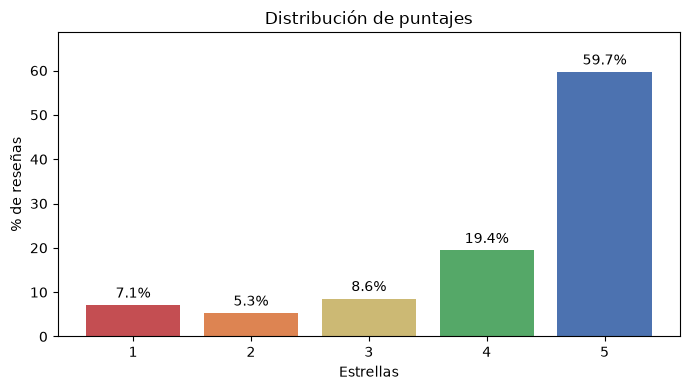

In [46]:
dist = con.sql("""
    SELECT score, COUNT(*) AS resenas,
           COUNT(*) * 100.0 / SUM(COUNT(*)) OVER () AS pct
    FROM reviews GROUP BY score ORDER BY score
""").df()
dist

dist["score"] = dist["score"].astype(int)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(dist["score"], dist["pct"],
       color=["#C44E52", "#DD8452", "#CCB974", "#55A868", "#4C72B0"])
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.set_title("Distribución de puntajes")
ax.set_xlabel("Estrellas")
ax.set_ylabel("% de reseñas")
ax.set_xticks(dist["score"])
ax.set_ylim(0, dist["pct"].max() * 1.15)

plt.tight_layout()
plt.show()


**Category_group**

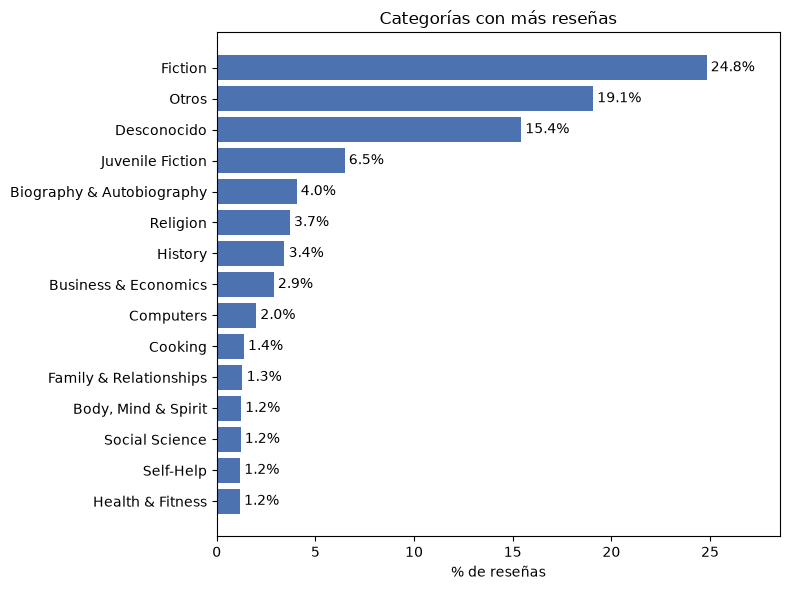

In [47]:
top_cat = con.sql("""
    SELECT COALESCE(category_group, 'Sin metadatos') AS categoria,
           COUNT(*) AS resenas,
           COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reviews) AS pct
    FROM reviews
    GROUP BY categoria
    ORDER BY resenas DESC
    LIMIT 15
""").df()

datos = top_cat.sort_values("resenas")   

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(datos["categoria"], datos["pct"], color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.set_title("Categorías con más reseñas")
ax.set_xlabel("% de reseñas")
ax.set_xlim(0, datos["pct"].max() * 1.15)

plt.tight_layout()
plt.show()

**publisher_clean**

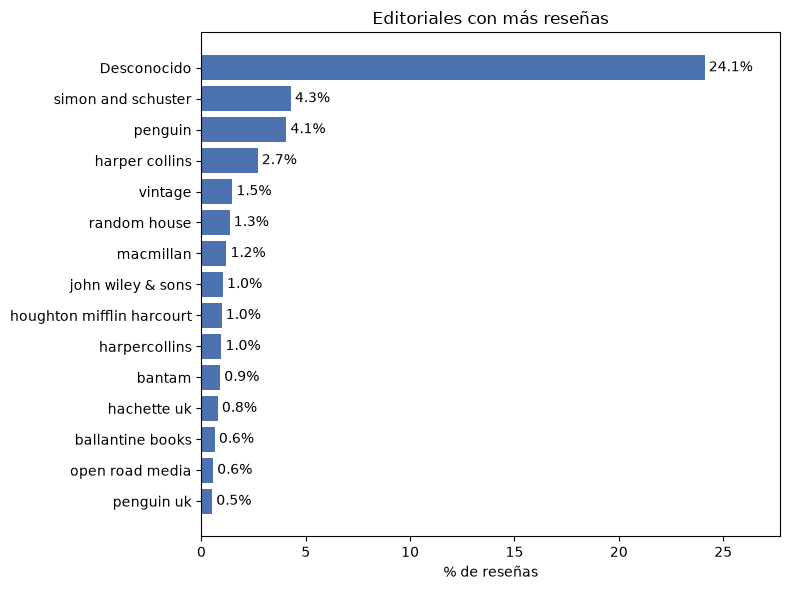

In [48]:
top_pub = con.sql("""
    SELECT COALESCE(publisher_clean, 'Sin metadatos') AS editorial,
           COUNT(*) AS resenas,
           COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reviews) AS pct
    FROM reviews
    GROUP BY editorial
    ORDER BY resenas DESC
    LIMIT 15
""").df()

datos = top_pub.sort_values("resenas")   

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(datos["editorial"], datos["pct"], color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.set_title("Editoriales con más reseñas")
ax.set_xlabel("% de reseñas")
ax.set_xlim(0, datos["pct"].max() * 1.15)

plt.tight_layout()
plt.show()

**main_author**

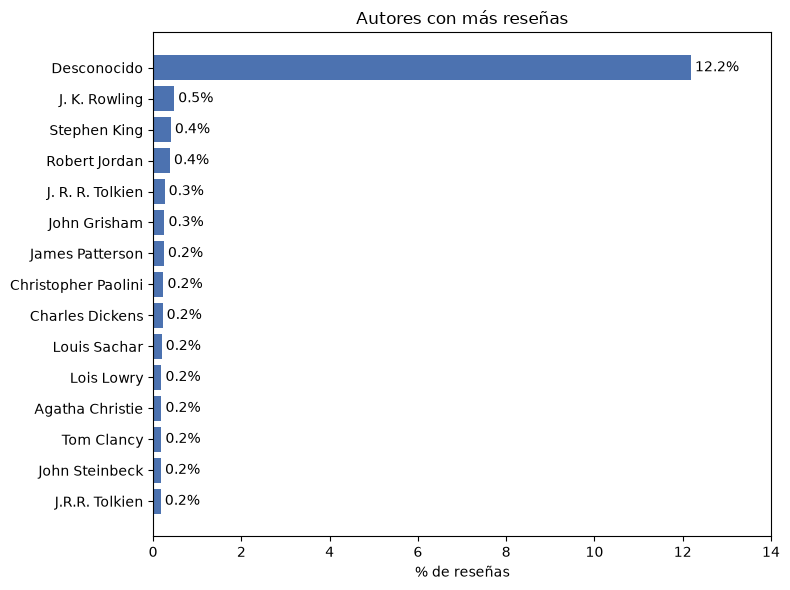

In [49]:
top_aut = con.sql("""
    SELECT main_author AS autor,
           COUNT(*) AS resenas,
           COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reviews) AS pct
    FROM reviews
    GROUP BY autor
    ORDER BY resenas DESC
    LIMIT 15
""").df()

datos = top_aut.sort_values("resenas")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(datos["autor"], datos["pct"], color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.set_title("Autores con más reseñas")
ax.set_xlabel("% de reseñas")
ax.set_xlim(0, datos["pct"].max() * 1.15)

plt.tight_layout()
plt.show()

**Variables categóricas binarias**

- is_negative

In [50]:
negativo =con.sql("""
    SELECT is_negative, COUNT(*) AS neg,
           COUNT(*) * 100.0 / SUM(COUNT(*)) OVER () AS pct
    FROM reviews GROUP BY is_negative
""").df()
negativo

,is_negative,neg,pct
0,0,1815983,87.641895
1,1,256066,12.358105


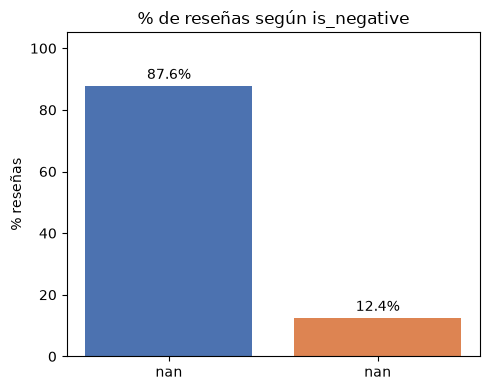

In [51]:
negativo["grupo"] = negativo["is_negative"].map({True: "negativo", False: "Puntaje positivo"})

fig, ax = plt.subplots(figsize=(5, 4))

x = range(len(negativo))
ax.bar(x, negativo["pct"], color=["#4C72B0", "#DD8452"])
ax.set_xticks(list(x))
ax.set_xticklabels(negativo["grupo"])

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("% de reseñas según is_negative")
ax.set_ylabel("% reseñas")
ax.set_ylim(0, negativo["pct"].max() * 1.2)
plt.tight_layout()
plt.show()

- es_anonimo

In [52]:
anonimo = con.sql("""
    SELECT es_anonimo, COUNT(*) AS n,
           COUNT(*) * 100.0 / SUM(COUNT(*)) OVER () AS pct
    FROM reviews GROUP BY es_anonimo
""").df()
anonimo

,es_anonimo,n,pct
0,False,1693304,81.721233
1,True,378745,18.278767


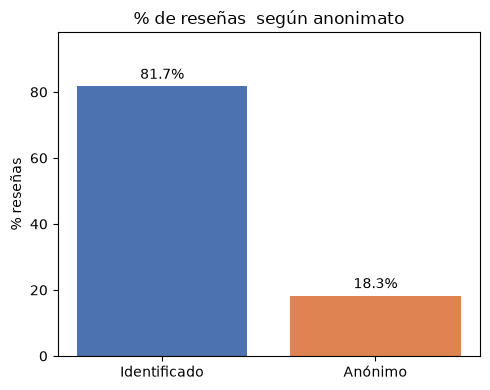

In [53]:
anonimo["grupo"] = anonimo["es_anonimo"].map({True: "Anónimo", False: "Identificado"})

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(anonimo["grupo"], anonimo["pct"], color=["#4C72B0", "#DD8452"])
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("% de reseñas  según anonimato")
ax.set_ylabel("% reseñas")
ax.set_ylim(0, anonimo["pct"].max() * 1.2)
plt.tight_layout()
plt.show()

**Otras variables numéricas**

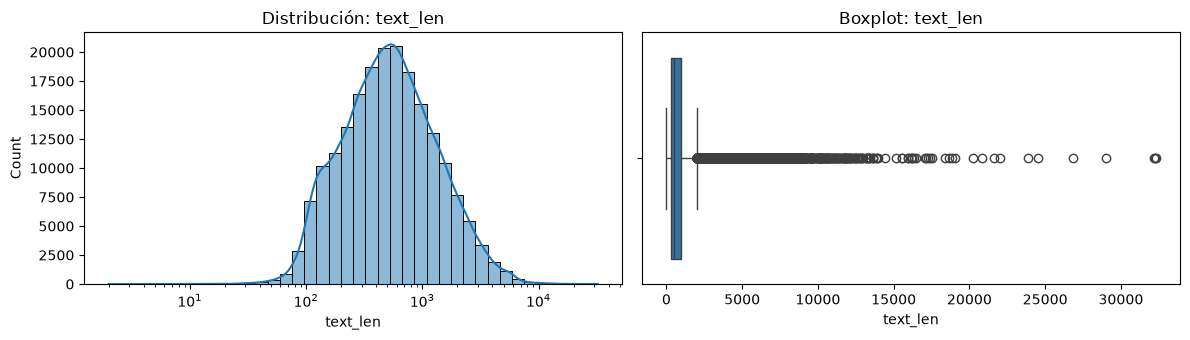

,n,media,std,min,q1,mediana,q3,max
0,2072047,808.350524,941.772265,1,269.0,514.0,985.0,32576


In [54]:
def analisis_numerica(col, bins=40, log=False):
    resumen = con.sql(f"""
        SELECT COUNT({col}) AS n, AVG({col}) AS media, STDDEV({col}) AS std,
               MIN({col}) AS min, quantile_cont({col}, 0.25) AS q1,
               quantile_cont({col}, 0.50) AS mediana,
               quantile_cont({col}, 0.75) AS q3, MAX({col}) AS max
        FROM reviews""").df()

    filtro = f"{col} IS NOT NULL" + (f" AND {col} > 0" if log else "")
    s = con.sql(f"""
        SELECT {col} FROM (SELECT {col} FROM reviews WHERE {filtro})
        USING SAMPLE reservoir(200000 ROWS) REPEATABLE (42)
    """).df()[col]

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.histplot(s, bins=bins, kde=True, log_scale=log, ax=axes[0])
    axes[0].set_title(f"Distribución: {col}")
    sns.boxplot(x=s, ax=axes[1])
    axes[1].set_title(f"Boxplot: {col}")
    plt.tight_layout(); plt.show()
    return resumen

analisis_numerica("text_len", log=True)

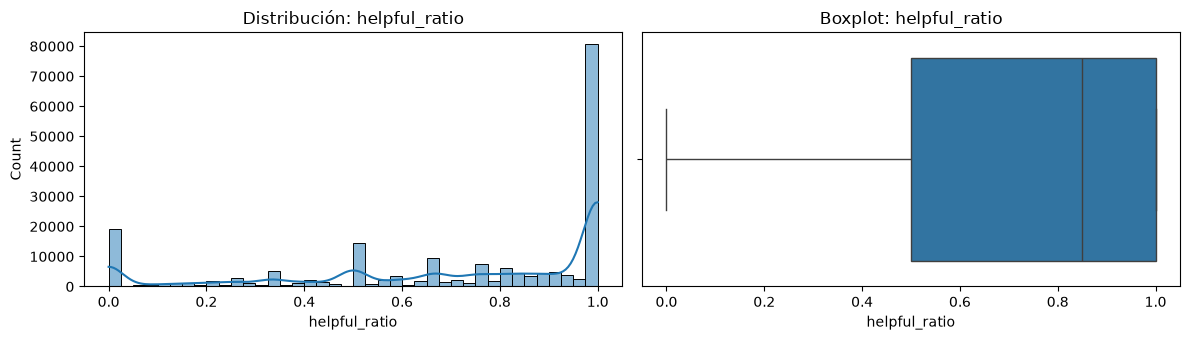

,n,media,std,min,q1,mediana,q3,max
0,1507236,0.715841,0.334693,0.0,0.5,0.857143,1.0,1.0


In [55]:
analisis_numerica("helpful_ratio")

- votes_total

Esta variable es muy asimétrica (la mayoría de las reseñas recibe pocos votos), por lo que se grafica en escala logarítmica. Las reseñas sin votos se cuentan aparte:

,sin_votos,pct_sin_votos
0,564808,27.258429


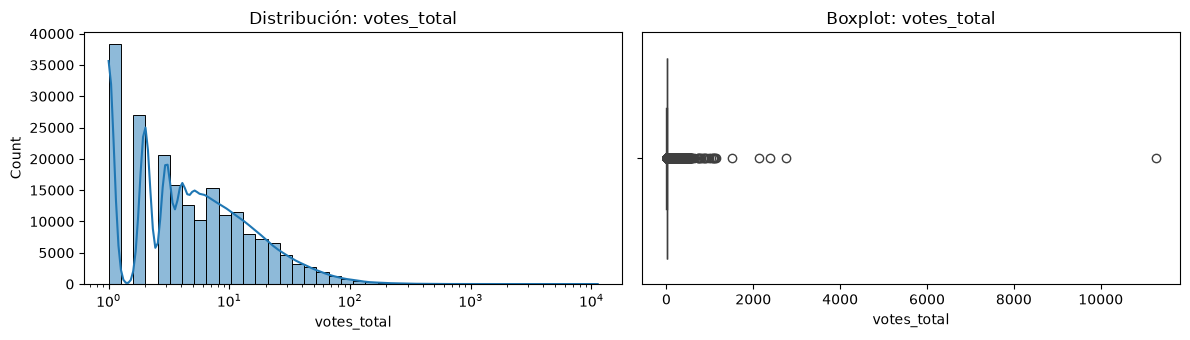

,n,media,std,min,q1,mediana,q3,max
0,2072049,7.288739,21.820613,0,0.0,2.0,7.0,11262


In [56]:
sin_votos = con.sql("""
    SELECT COUNT(*) FILTER (WHERE votes_total = 0) AS sin_votos,
           COUNT(*) FILTER (WHERE votes_total = 0) * 100.0 / COUNT(*) AS pct_sin_votos
    FROM reviews
""").df()
display(sin_votos)

analisis_numerica("votes_total", log=True)

**Años**

- Review_year

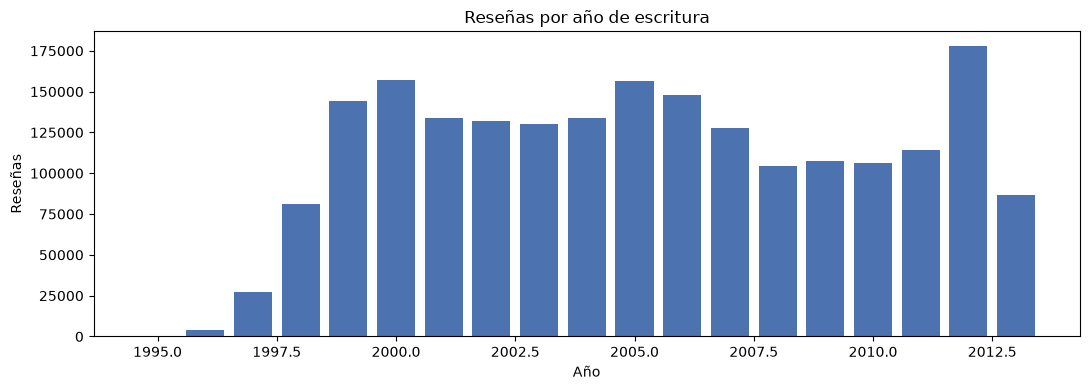

In [57]:
anual = con.sql("""
    SELECT review_year AS anio, COUNT(*) AS n
    FROM reviews
    WHERE review_year IS NOT NULL
    GROUP BY anio ORDER BY anio
""").df()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(anual["anio"], anual["n"], color="#4C72B0")
ax.set_title("Reseñas por año de escritura")
ax.set_xlabel("Año"); ax.set_ylabel("Reseñas")
plt.tight_layout(); plt.show()


- Published_year

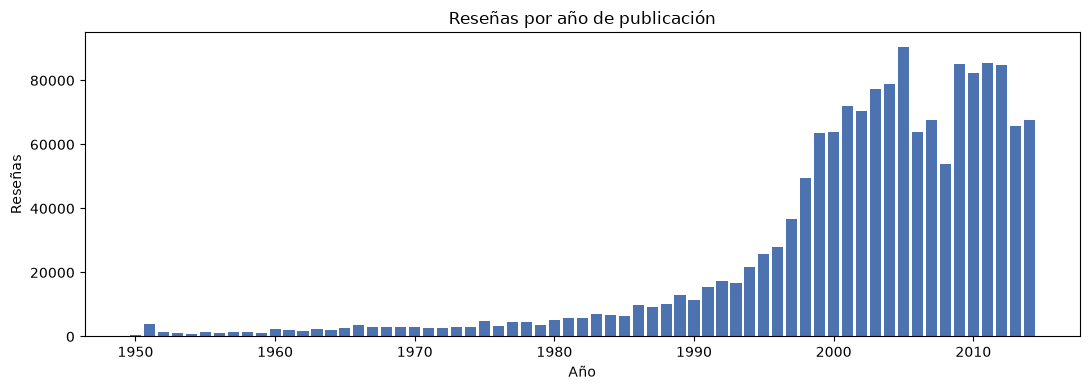

In [58]:
pub = con.sql("""
    SELECT published_year AS anio, COUNT(*) AS n
    FROM reviews
    WHERE published_year BETWEEN 1950 AND 2014
    GROUP BY anio ORDER BY anio
""").df()
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(pub["anio"], pub["n"], color="#4C72B0")
ax.set_title("Reseñas por año de publicación")
ax.set_xlabel("Año"); ax.set_ylabel("Reseñas")
plt.tight_layout(); plt.show()


### Conclusiones del análisis univariado

1. **Variable objetivo desbalanceada.** El 59,7 % de las reseñas tiene 5 estrellas y el 19,4 % tiene 4. Solo el **12,36 %** es negativo (1 o 2 estrellas). Este desbalance (aproximadamente 1 negativa por cada 7 positivas) obliga a evaluar cualquier modelo con métricas como ROC-AUC o precisión/recall, y no con la exactitud.
2. **Catálogo muy concentrado en ficción y con muchos datos faltantes.** *Fiction* reúne el 24,8 % de las reseñas, seguida de "Otros" (19,1 %) y "Desconocido" (15,4 %). En editorial, el 24,1 % es "Desconocido"; en autor, el 12,2 %. Hay 117.193 autores y 15.624 editoriales distintos: son variables de cardinalidad muy alta, por eso más adelante se analizan sus grupos principales.
3. **Ningún autor domina el volumen.** El autor con más reseñas, J. K. Rowling, apenas llega al 0,47 %. Aparecen nombres escritos de dos formas ("J.R.R. Tolkien" / "J. R. R. Tolkien", "harper collins" / "harpercollins"), un punto pendiente de unificar.
4. **El 18,3 % de las reseñas es anónimo** (no tiene `user_id`).
5. **La longitud del texto es muy asimétrica.** La mediana es de 514 caracteres, pero la media sube a 808 por las reseñas muy largas (hasta 32.576 caracteres). El 7,5 % son atípicos según el rango intercuartílico y se conservan porque son textos reales.
6. **Los votos se concentran en pocas reseñas.** El 27,3 % no recibe ningún voto y la mediana es de 2, mientras que el 2 % supera los 50 votos (máximo 11.262). Cuando hay votos, la proporción de utilidad es alta (mediana de 0,86): la mayoría de las reseñas se considera útil.
7. **Las reseñas abarcan 1995-2013.** El volumen crece rápido hasta 1999 y se mantiene entre 100 mil y 160 mil reseñas por año, con un pico en 2012 (178 mil).
8. **El año de publicación no es confiable por sí solo.** El 16 % de las reseñas corresponde a libros con año de publicación posterior a 2013 (reediciones) y hay clásicos con fechas desde 1526. Por eso no se usa directamente y se transforma en la antigüedad del libro al momento de la reseña.

### - Ajuste de las variables a distribuciones teóricas

Se busca qué distribución de probabilidad describe mejor cada variable numérica. Se trabaja sobre una muestra aleatoria de 100.000 reseñas por variable, porque con millones de datos cualquier prueba rechaza todas las distribuciones aunque el ajuste sea bueno.

Para comparar los candidatos se usan tres criterios:

- **AIC** (criterio de información de Akaike): penaliza la falta de ajuste y el número de parámetros. Gana el menor.
- **Estadístico KS** (Kolmogorov-Smirnov): la máxima distancia entre la distribución acumulada observada y la teórica. Cuanto menor, mejor. Con muestras grandes el p-valor sale casi siempre cercano a 0, por eso se usa la distancia y no el p-valor.
- **Gráfico Q-Q**: si los puntos caen sobre la diagonal, la distribución describe bien los datos, incluida la cola.

| Variable | Tipo | Candidatos |
|---|---|---|
| `text_len` | continua, positiva, asimétrica a la derecha | lognormal, gamma, Weibull, exponencial |
| `votes_total` | discreta (conteo) | Poisson, binomial negativa |
| `helpful_ratio` | proporción entre 0 y 1 | beta (con masa extra en 0 y en 1) |
| `antiguedad_libro` | conteo de años, positiva | exponencial, gamma, lognormal, Weibull |
| `score` | ordinal, 5 valores | multinomial (categórica) |
| `is_negative`, `es_anonimo` | binarias | Bernoulli |

`review_year` describe cuándo se escribió la reseña y no tiene una distribución teórica de interés.

In [59]:
from scipy import stats
import numpy as np
import seaborn as sns

con.execute("""
    CREATE OR REPLACE VIEW reviews_ajuste AS
    SELECT *,
           CASE WHEN published_year BETWEEN 1800 AND 2013 AND review_year >= published_year
                THEN review_year - published_year END AS antiguedad_libro
    FROM reviews
""")

def muestra_ajuste(col, condicion="TRUE", n=100_000):
    return con.sql(f"""
        SELECT {col} AS v FROM (SELECT {col} FROM reviews_ajuste
                                WHERE {col} IS NOT NULL AND {condicion})
        USING SAMPLE reservoir({n} ROWS) REPEATABLE (42)
    """).df()["v"].astype(float).values


def ajustar_continuas(x, candidatos):
    """Ajusta cada distribución por máxima verosimilitud y la compara con AIC y KS."""
    filas, params = [], {}
    for nombre, dist in candidatos.items():
        p = dist.fit(x, floc=0)
        loglik = np.sum(dist.logpdf(x, *p))
        k = len(p) - 1                       # loc fijo en 0: no cuenta como parámetro
        ks = stats.kstest(x, dist.cdf, args=p).statistic
        filas.append({"distribucion": nombre, "AIC": 2 * k - 2 * loglik, "KS": ks,
                      "parametros": ", ".join(f"{v:.4g}" for v in p)})
        params[nombre] = p
    tabla = pd.DataFrame(filas).sort_values("AIC").reset_index(drop=True)
    tabla["delta_AIC"] = tabla["AIC"] - tabla["AIC"].min()
    return tabla, params


def graficar_ajuste(x, tabla, params, candidatos, titulo, log_x=False, recorte=0.99):
    mejor = tabla.loc[0, "distribucion"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    lim = np.quantile(x, recorte)
    xs = np.linspace(max(x.min(), 1e-6), lim, 400)
    if log_x:
        bins = np.logspace(np.log10(max(x.min(), 1)), np.log10(lim), 60)
        axes[0].set_xscale("log")
    else:
        bins = 60
    axes[0].hist(x[x <= lim], bins=bins, density=True, color="#B0C4DE", label="Observado")
    for nombre in tabla["distribucion"]:
        estilo = "-" if nombre == mejor else "--"
        axes[0].plot(xs, candidatos[nombre].pdf(xs, *params[nombre]), estilo, lw=2 if nombre == mejor else 1.2,
                     label=nombre + (" (mejor)" if nombre == mejor else ""))
    axes[0].set_title(f"{titulo}: histograma y densidades ajustadas")
    axes[0].legend(fontsize=8)

    # Q-Q de la mejor distribución
    q = np.linspace(0.005, 0.995, 199)
    teoricos = candidatos[mejor].ppf(q, *params[mejor])
    observados = np.quantile(x, q)
    axes[1].scatter(teoricos, observados, s=10, color="#4C72B0")
    tope = max(teoricos.max(), observados.max())
    axes[1].plot([0, tope], [0, tope], color="#C44E52", lw=1)
    axes[1].set_title(f"Q-Q: {titulo} vs {mejor}")
    axes[1].set_xlabel("Cuantiles teóricos"); axes[1].set_ylabel("Cuantiles observados")
    plt.tight_layout(); plt.show()

**text_len (longitud del texto)**

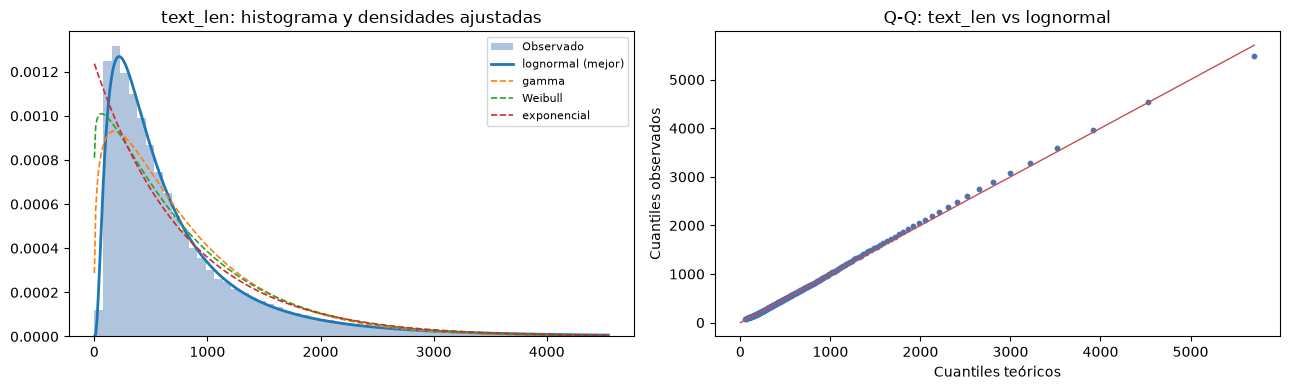

,distribucion,AIC,KS,parametros,delta_AIC
0,lognormal,1.520289e+06,0.014883,"0.9294, 0, 521",0.000000
1,gamma,1.535313e+06,0.071857,"1.281, 0, 630.6",15024.097022
2,Weibull,1.538030e+06,0.074053,"1.068, 0, 832.3",17741.608312
3,exponencial,1.538858e+06,0.091631,"0, 807.8",18569.623994


In [60]:
x_len = muestra_ajuste("text_len", "text_len > 0")
cand_len = {"lognormal": stats.lognorm, "gamma": stats.gamma,
            "Weibull": stats.weibull_min, "exponencial": stats.expon}
tabla_len, par_len = ajustar_continuas(x_len, cand_len)
graficar_ajuste(x_len, tabla_len, par_len, cand_len, "text_len")
tabla_len

log(text_len) ~ Normal(media = 6.256, desviación = 0.929)
Mediana teórica = 521 caracteres | mediana observada = 517


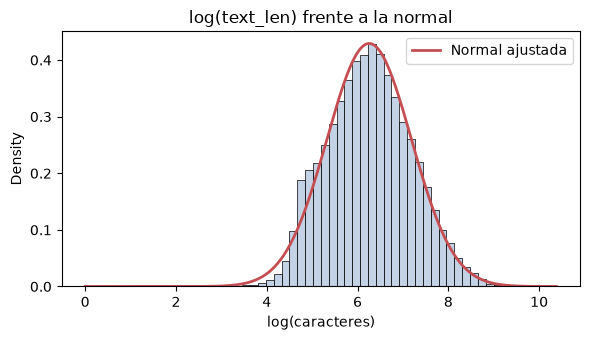

In [61]:
# Interpretación de la lognormal: log(text_len) sigue una normal
forma, _, escala = par_len["lognormal"]
print(f"log(text_len) ~ Normal(media = {np.log(escala):.3f}, desviación = {forma:.3f})")
print(f"Mediana teórica = {escala:,.0f} caracteres | mediana observada = {np.median(x_len):,.0f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(np.log(x_len), bins=60, stat="density", color="#B0C4DE", ax=ax)
xs = np.linspace(np.log(x_len).min(), np.log(x_len).max(), 300)
ax.plot(xs, stats.norm.pdf(xs, np.log(escala), forma), color="#C44E52", lw=2, label="Normal ajustada")
ax.set_title("log(text_len) frente a la normal"); ax.set_xlabel("log(caracteres)"); ax.legend()
plt.tight_layout(); plt.show()

**votes_total (votos totales)**

Es un conteo, así que se comparan distribuciones discretas. Si la varianza es mucho mayor que la media (**sobredispersión**), la Poisson no sirve y la binomial negativa es la candidata natural. Los parámetros de la binomial negativa se estiman por máxima verosimilitud, partiendo de la estimación por el método de momentos.

In [62]:
x_vot = muestra_ajuste("votes_total").astype(int)
media, var = x_vot.mean(), x_vot.var()
print(f"Media = {media:.2f} | varianza = {var:.2f} | varianza/media = {var / media:.1f}  (Poisson exige 1)")

from scipy.optimize import minimize

# Poisson: lambda = media (estimador de máxima verosimilitud)
lam = media
# Binomial negativa: punto de partida por momentos y luego máxima verosimilitud
p_ini, r_ini = media / var, media ** 2 / (var - media)
def nll_nbinom(t):
    r, p = np.exp(t[0]), 1 / (1 + np.exp(-t[1]))
    return -stats.nbinom.logpmf(x_vot, r, p).sum()
res = minimize(nll_nbinom, [np.log(r_ini), np.log(p_ini / (1 - p_ini))], method="Nelder-Mead")
r_nb, p_nb = np.exp(res.x[0]), 1 / (1 + np.exp(-res.x[1]))

ll_poi = stats.poisson.logpmf(x_vot, lam).sum()
ll_nb = -res.fun
tabla_vot = pd.DataFrame({
    "distribucion": ["binomial negativa", "Poisson"],
    "parametros": [f"r = {r_nb:.3f}, p = {p_nb:.4f}", f"lambda = {lam:.3f}"],
    "P(0 votos) teórica": [stats.nbinom.pmf(0, r_nb, p_nb), stats.poisson.pmf(0, lam)],
    "AIC": [2 * 2 - 2 * ll_nb, 2 * 1 - 2 * ll_poi],
}).sort_values("AIC").reset_index(drop=True)
tabla_vot["delta_AIC"] = tabla_vot["AIC"] - tabla_vot["AIC"].min()
print(f"P(0 votos) observada: {(x_vot == 0).mean():.3f}")
tabla_vot

Media = 7.20 | varianza = 363.00 | varianza/media = 50.4  (Poisson exige 1)
P(0 votos) observada: 0.273


,distribucion,parametros,P(0 votos) teórica,AIC,delta_AIC
0,binomial negativa,"r = 0.408, p = 0.0536",0.303317,5.702429e+05,0.000000e+00
1,Poisson,lambda = 7.200,0.000747,1.889804e+06,1.319561e+06


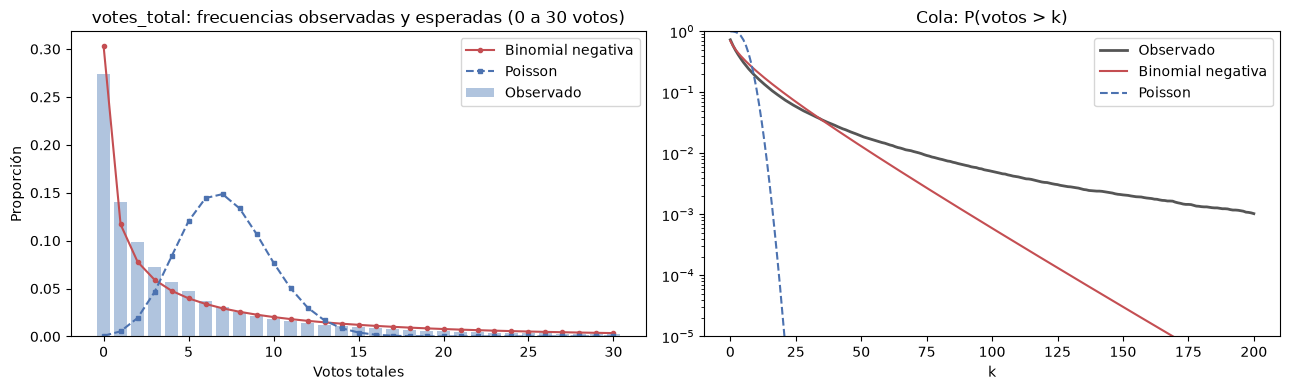

In [63]:
k = np.arange(0, 31)
obs = np.array([(x_vot == i).mean() for i in k])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(k, obs, color="#B0C4DE", label="Observado")
axes[0].plot(k, stats.nbinom.pmf(k, r_nb, p_nb), "o-", color="#C44E52", ms=3, label="Binomial negativa")
axes[0].plot(k, stats.poisson.pmf(k, lam), "s--", color="#4C72B0", ms=3, label="Poisson")
axes[0].set_title("votes_total: frecuencias observadas y esperadas (0 a 30 votos)")
axes[0].set_xlabel("Votos totales"); axes[0].set_ylabel("Proporción"); axes[0].legend()

# Cola: probabilidad de superar k votos (escala log)
kk = np.arange(0, 201)
sup_obs = np.array([(x_vot > i).mean() for i in kk])
axes[1].semilogy(kk, sup_obs, color="#555", lw=2, label="Observado")
axes[1].semilogy(kk, stats.nbinom.sf(kk, r_nb, p_nb), color="#C44E52", label="Binomial negativa")
axes[1].semilogy(kk, np.clip(stats.poisson.sf(kk, lam), 1e-7, None), "--", color="#4C72B0", label="Poisson")
axes[1].set_ylim(1e-5, 1)
axes[1].set_title("Cola: P(votos > k)"); axes[1].set_xlabel("k"); axes[1].legend()
plt.tight_layout(); plt.show()

**helpful_ratio (proporción de utilidad)**

Una proporción entre 0 y 1 se modela con la distribución **beta**. Como es un cociente de números enteros pequeños, sus valores se concentran en fracciones simples (1/2, 2/3, 3/4…), lo que produce los picos del histograma. Además tiene una acumulación de valores exactamente en 0 y en 1 (reseñas con pocos votos donde todos coinciden), que la beta no puede producir. Por eso se modela como **beta inflada en 0 y 1**: se reporta el porcentaje en cada extremo y la beta se ajusta solo a los valores intermedios.

Masa en 0: 9.5% | masa en 1: 40.0% | valores intermedios: 50.5%


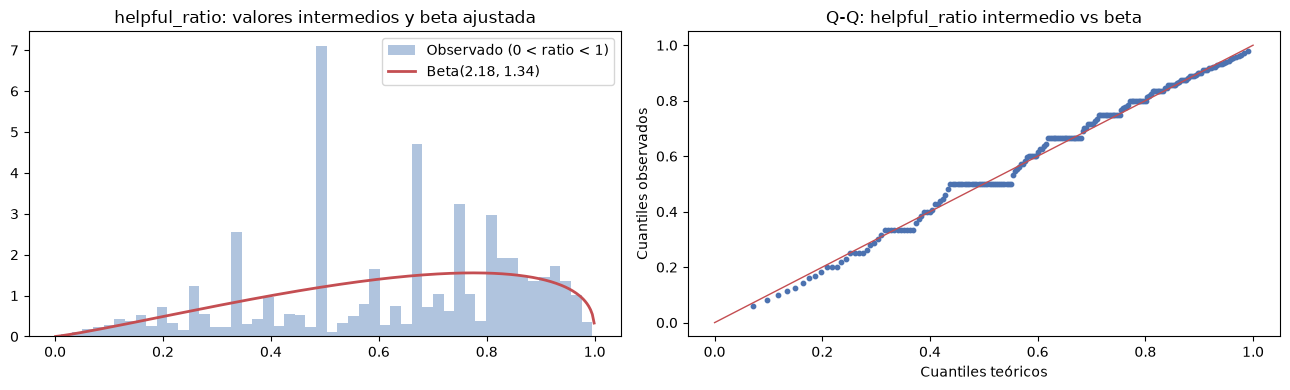

,distribucion,parametros,AIC,KS
0,beta (valores intermedios),"alfa = 2.176, beta = 1.342",-15091.655693,0.075482
1,uniforme (referencia),"0, 1",0.000000,0.268711


In [64]:
x_hr = muestra_ajuste("helpful_ratio")
p0, p1 = (x_hr == 0).mean(), (x_hr == 1).mean()
interior = x_hr[(x_hr > 0) & (x_hr < 1)]
print(f"Masa en 0: {p0:.1%} | masa en 1: {p1:.1%} | valores intermedios: {1 - p0 - p1:.1%}")

a, b, _, _ = stats.beta.fit(interior, floc=0, fscale=1)
ks_beta = stats.kstest(interior, stats.beta.cdf, args=(a, b)).statistic
ks_unif = stats.kstest(interior, stats.uniform.cdf).statistic
ll_beta = stats.beta.logpdf(interior, a, b).sum()
tabla_hr = pd.DataFrame({
    "distribucion": ["beta (valores intermedios)", "uniforme (referencia)"],
    "parametros": [f"alfa = {a:.3f}, beta = {b:.3f}", "0, 1"],
    "AIC": [2 * 2 - 2 * ll_beta, 0.0],          # la uniforme en (0,1) tiene log-verosimilitud 0
    "KS": [ks_beta, ks_unif],
}).sort_values("AIC").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(interior, bins=50, density=True, color="#B0C4DE", label="Observado (0 < ratio < 1)")
xs = np.linspace(0.001, 0.999, 300)
axes[0].plot(xs, stats.beta.pdf(xs, a, b), color="#C44E52", lw=2, label=f"Beta({a:.2f}, {b:.2f})")
axes[0].set_title("helpful_ratio: valores intermedios y beta ajustada"); axes[0].legend()
q = np.linspace(0.005, 0.995, 199)
axes[1].scatter(stats.beta.ppf(q, a, b), np.quantile(interior, q), s=10, color="#4C72B0")
axes[1].plot([0, 1], [0, 1], color="#C44E52", lw=1)
axes[1].set_title("Q-Q: helpful_ratio intermedio vs beta")
axes[1].set_xlabel("Cuantiles teóricos"); axes[1].set_ylabel("Cuantiles observados")
plt.tight_layout(); plt.show()
tabla_hr

**antiguedad_libro (años entre publicación y reseña)**

Se ajusta sobre los valores mayores que 0. El 15,5 % de las reseñas se escribe el mismo año de publicación (antigüedad 0), y esa masa se reporta aparte.

Reseñas del mismo año de publicación (antigüedad 0): 15.5%


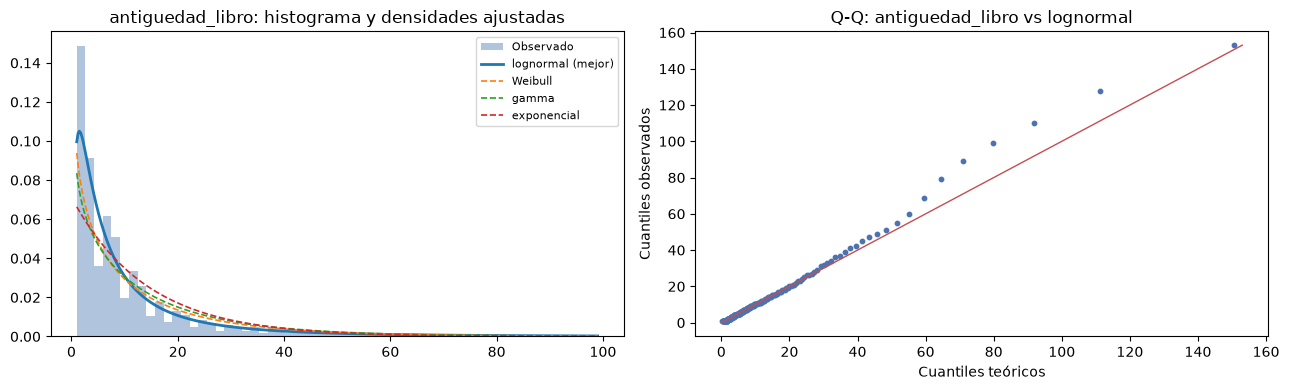

,distribucion,AIC,KS,parametros,delta_AIC
0,lognormal,590382.575105,0.080033,"1.217, 0, 6.544",0.000000
1,Weibull,606897.716464,0.123999,"0.8093, 0, 12.16",16515.141358
2,gamma,611555.645312,0.111510,"0.7802, 0, 17.99",21173.070207
3,exponencial,615317.510720,0.149478,"0, 14.04",24934.935615


In [65]:
x_ant_total = muestra_ajuste("antiguedad_libro")
print(f"Reseñas del mismo año de publicación (antigüedad 0): {(x_ant_total == 0).mean():.1%}")
x_ant = x_ant_total[x_ant_total > 0]
cand_ant = {"exponencial": stats.expon, "gamma": stats.gamma,
            "lognormal": stats.lognorm, "Weibull": stats.weibull_min}
tabla_ant, par_ant = ajustar_continuas(x_ant, cand_ant)
graficar_ajuste(x_ant, tabla_ant, par_ant, cand_ant, "antiguedad_libro", recorte=0.98)
tabla_ant

**score (calificación) y variables binarias**

Estas variables no tienen una distribución continua que ajustar, pero sí un modelo de probabilidad:

- `score` toma solo los valores 1 a 5, así que se describe con una **distribución multinomial (categórica)**: una probabilidad para cada número de estrellas, estimada con su proporción observada. Se compara con la uniforme (todas las calificaciones igual de probables) con una prueba chi-cuadrado de bondad de ajuste.
- `is_negative` y `es_anonimo` toman solo 0 o 1, así que siguen una **distribución de Bernoulli**, cuyo único parámetro *p* es la proporción de unos. Se reporta con su intervalo de confianza del 95 %.

Aquí se usan todas las reseñas, no una muestra, porque son solo conteos.

Chi-cuadrado frente a la uniforme = 2,164,123 (p = 0.0e+00)
Media = 4.193 | varianza = 1.494 | moda = 5 estrellas


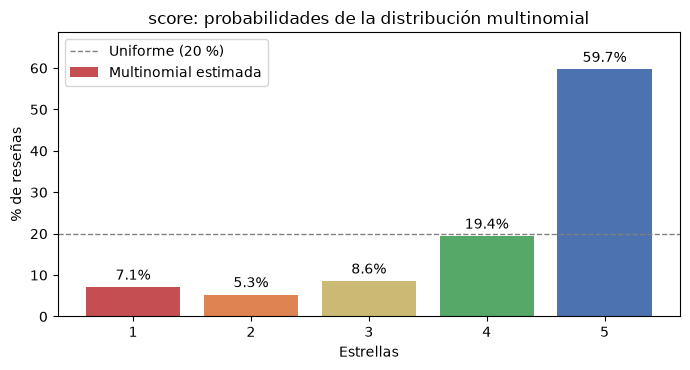

,score,n,p_estimada,p_uniforme
0,1,146864,0.0709,0.2
1,2,109202,0.0527,0.2
2,3,177381,0.0856,0.2
3,4,402141,0.1941,0.2
4,5,1236461,0.5967,0.2


In [66]:
score_dist = con.sql("""
    SELECT CAST(score AS INT) AS score, COUNT(*) AS n
    FROM reviews WHERE score IS NOT NULL
    GROUP BY score ORDER BY score
""").df()
n_total = score_dist["n"].sum()
score_dist["p_estimada"] = score_dist["n"] / n_total
score_dist["p_uniforme"] = 1 / len(score_dist)

chi2, p_valor = stats.chisquare(score_dist["n"], f_exp=score_dist["p_uniforme"] * n_total)
media_score = (score_dist["score"] * score_dist["p_estimada"]).sum()
var_score = ((score_dist["score"] - media_score) ** 2 * score_dist["p_estimada"]).sum()
print(f"Chi-cuadrado frente a la uniforme = {chi2:,.0f} (p = {p_valor:.1e})")
print(f"Media = {media_score:.3f} | varianza = {var_score:.3f} | moda = 5 estrellas")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(score_dist["score"], score_dist["p_estimada"] * 100,
       color=["#C44E52", "#DD8452", "#CCB974", "#55A868", "#4C72B0"], label="Multinomial estimada")
ax.axhline(20, color="gray", ls="--", lw=1, label="Uniforme (20 %)")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("score: probabilidades de la distribución multinomial")
ax.set_xlabel("Estrellas"); ax.set_ylabel("% de reseñas"); ax.set_xticks(score_dist["score"])
ax.set_ylim(0, score_dist["p_estimada"].max() * 115)
ax.legend()
plt.tight_layout(); plt.show()

score_dist.round(4)

In [67]:
def bernoulli(col):
    r = con.sql(f"SELECT COUNT(*) AS n, SUM({col}::INT) AS unos FROM reviews WHERE {col} IS NOT NULL").df().iloc[0]
    n, k = int(r["n"]), int(r["unos"])
    p = k / n
    # Intervalo de Wilson al 95 %
    z = 1.96
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return {"variable": col, "n": n, "unos": k, "p_estimada": p,
            "IC95_inferior": centro - margen, "IC95_superior": centro + margen,
            "varianza p(1-p)": p * (1 - p)}

tabla_bern = pd.DataFrame([bernoulli("is_negative"), bernoulli("es_anonimo")]).set_index("variable")
tabla_bern.round(5)

,n,unos,p_estimada,IC95_inferior,IC95_superior,varianza p(1-p)
variable,,,,,,
is_negative,2072049,256066,0.12358,0.12313,0.12403,0.10831
es_anonimo,2072049,378745,0.18279,0.18226,0.18331,0.14938


### Conclusiones del ajuste de distribuciones

| Variable | Mejor ajuste | Parámetros | Calidad |
|---|---|---|---|
| `text_len` | **Lognormal** | log(text_len) ~ Normal(6,26; 0,93) | Muy buena (KS = 0,015, frente a 0,073 de la gamma) |
| `votes_total` | **Binomial negativa** | r = 0,40; p = 0,052 | Buena en el cuerpo; la cola real es más pesada |
| `helpful_ratio` | **Beta inflada en 0 y 1** | 9,4 % en 0; 40,3 % en 1; Beta(2,18; 1,34) en el resto | Aceptable (KS = 0,074, frente a 0,269 de la uniforme) |
| `antiguedad_libro` | **Lognormal** (para valores > 0) | mediana teórica de 6,6 años; 15,6 % en 0 | Aceptable; la cola de libros muy antiguos es más pesada |
| `score` | **Multinomial (categórica)** | p = (0,071; 0,053; 0,086; 0,194; 0,597) para 1 a 5 estrellas | Exacta por construcción; muy lejos de la uniforme (chi-cuadrado, p ≈ 0) |
| `is_negative` | **Bernoulli** | p = 0,1236 (IC 95 %: 0,1231 a 0,1240) | Exacta por construcción |
| `es_anonimo` | **Bernoulli** | p = 0,1828 (IC 95 %: 0,1823 a 0,1833) | Exacta por construcción |

1. **La longitud del texto es lognormal.** Su logaritmo se comporta como una normal y la mediana teórica (522 caracteres) casi coincide con la observada (515). Por eso en los modelos se usa `log(text_len)`: así la variable queda simétrica y los textos muy largos no dominan.
2. **Los votos no siguen una Poisson.** La varianza es 75 veces la media (sobredispersión), así que la Poisson queda descartada (su AIC es tres veces mayor). La binomial negativa reproduce bien la masa en 0 votos (30 % teórico frente a 27 % observado) y el descenso hasta unos 40 votos. Más allá, la cola observada es más pesada: unas pocas reseñas concentran cientos o miles de votos. Por eso en los modelos se usa `log(1 + votes_total)`.
3. **La utilidad tiene tres partes.** Casi la mitad de las reseñas con votos está en un extremo (40 % todo útil, 9 % nada útil). El resto sigue una beta cargada hacia valores altos (media de 0,62). Los picos en 1/2, 2/3 o 3/4 aparecen porque la variable es un cociente de números pequeños. Un modelo que la use debería distinguir los extremos, por ejemplo con indicadores de "todo útil" y "nada útil".
4. **La antigüedad del libro es aproximadamente lognormal**, con una masa del 15,6 % en antigüedad 0 (reseñas del mismo año de publicación). Los libros de más de 50 años (clásicos) están por encima de lo que predice la lognormal. Además, esta variable tiene un 50,7 % de nulos, por lo que su ajuste es solo descriptivo.

5. **La calificación tiene forma de J.** El 59,7 % de las reseñas da 5 estrellas y la probabilidad cae hasta 5,3 % en 2 estrellas, para repuntar un poco en 1 estrella (7,1 %). Es el patrón típico de las reseñas en línea: quien escribe suele estar muy contento o muy molesto. Por eso la media (4,19) no describe bien la variable, y la variable objetivo se definió como binaria.
6. **Las variables binarias siguen una Bernoulli** con *p* = 12,36 % (reseñas negativas) y *p* = 18,28 % (anónimas). Con 2 millones de reseñas los intervalos de confianza son muy estrechos (±0,05 puntos). El *p* de `is_negative` confirma que la variable objetivo está desbalanceada, como se señaló en el univariado.

Ninguna de las variables es normal. Esto confirma que en el análisis bivariado había que usar pruebas no paramétricas (Mann-Whitney, Spearman) y transformaciones logarítmicas en la regresión.

### - Análisis Bivariado

En esta sección se cruza la variable objetivo **`is_negative`** (1 si `score` ≤ 2) con cada una de las características candidatas. Solo se usan las variables que quedaron después de la limpieza, porque las demás no aportan información confiable:

| Se usan | Se excluyen (y por qué) |
|---|---|
| `text_len`, `votes_total`, `helpful_ratio`, `review_year`, `published_year`, `category_group`, `publisher_clean`, `main_author`, `es_anonimo` | `price` (84 % nulos), `ratings_count` (77 % nulos), `description` (32 % nulos, texto libre), `profile_name` / `user_id` (identificadores, no explican la calificación), `text` / `summary` (texto libre; de ellos solo se usa la longitud) |

La métrica principal es la **tasa de reseñas negativas** (% de `is_negative` = 1) de cada grupo, comparada contra la tasa global. Las consultas se hacen con DuckDB sobre todas las reseñas; las pruebas estadísticas y los gráficos de dispersión usan una muestra aleatoria.

In [68]:
from scipy import stats
import numpy as np

tasa_global = con.execute("SELECT AVG(is_negative) * 100 FROM reviews").fetchone()[0]
print(f"Tasa global de reseñas negativas: {tasa_global:.2f} %")

Tasa global de reseñas negativas: 12.36 %


**Antigüedad del libro**

`published_year` tiene valores imposibles (desde el año 1016 hasta 2030), por lo que en lugar de usarla directamente se construye `antiguedad_libro` = años entre la publicación del libro y la reseña. Solo se calcula cuando el año de publicación está entre 1800 y 2013 y no es posterior a la reseña; en otro caso queda nula.

In [69]:
con.execute("""
    CREATE OR REPLACE VIEW reviews_biv AS
    SELECT *,
           CASE WHEN published_year BETWEEN 1800 AND 2013
                 AND review_year >= published_year
                THEN review_year - published_year END AS antiguedad_libro
    FROM reviews
""")

con.sql("""
    SELECT COUNT(antiguedad_libro) AS con_antiguedad,
           COUNT(*) - COUNT(antiguedad_libro) AS sin_antiguedad,
           (COUNT(*) - COUNT(antiguedad_libro)) * 100.0 / COUNT(*) AS pct_nulos
    FROM reviews_biv
""").df()

,con_antiguedad,sin_antiguedad,pct_nulos
0,1021074,1050975,50.721532


#### Variables numéricas vs `is_negative`

Primero se compara la media y la mediana de cada variable numérica entre reseñas negativas y positivas.

In [70]:
num_vars = ["text_len", "votes_total", "helpful_ratio", "review_year", "antiguedad_libro"]

filas = []
for col in num_vars:
    r = con.sql(f"""
        SELECT is_negative, AVG({col}) AS media, quantile_cont({col}, 0.5) AS mediana
        FROM reviews_biv WHERE {col} IS NOT NULL GROUP BY is_negative
    """).df().set_index("is_negative")
    filas.append({"variable": col,
                  "media_positivas": r.loc[0, "media"], "media_negativas": r.loc[1, "media"],
                  "mediana_positivas": r.loc[0, "mediana"], "mediana_negativas": r.loc[1, "mediana"]})

comp_num = pd.DataFrame(filas).set_index("variable").round(3)
comp_num["dif_media_%"] = ((comp_num["media_negativas"] / comp_num["media_positivas"] - 1) * 100).round(1)
comp_num

,media_positivas,media_negativas,mediana_positivas,mediana_negativas,dif_media_%
variable,,,,,
text_len,801.512,856.851,506.000,568.0,6.9
votes_total,6.030,16.215,2.000,8.0,168.9
helpful_ratio,0.751,0.520,0.909,0.5,-30.8
review_year,2005.277,2004.998,2005.000,2005.0,-0.0
antiguedad_libro,12.154,10.148,5.000,4.0,-16.5


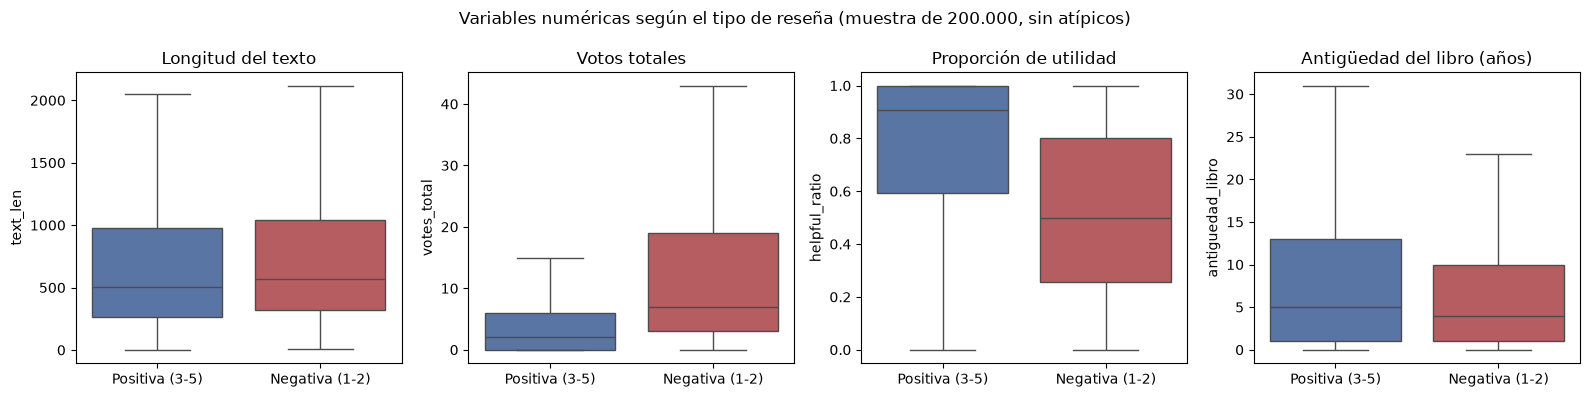

In [71]:
m = con.sql("""
    SELECT is_negative, text_len, votes_total, helpful_ratio, review_year, antiguedad_libro
    FROM reviews_biv
    USING SAMPLE reservoir(200000 ROWS) REPEATABLE (42)
""").df()
m["clase"] = m["is_negative"].map({0: "Positiva (3-5)", 1: "Negativa (1-2)"})
paleta = {"Positiva (3-5)": "#4C72B0", "Negativa (1-2)": "#C44E52"}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sns.boxplot(data=m, x="clase", y="text_len", hue="clase", palette=paleta, showfliers=False, ax=axes[0])
axes[0].set_title("Longitud del texto")
sns.boxplot(data=m, x="clase", y="votes_total", hue="clase", palette=paleta, showfliers=False, ax=axes[1])
axes[1].set_title("Votos totales")
sns.boxplot(data=m, x="clase", y="helpful_ratio", hue="clase", palette=paleta, showfliers=False, ax=axes[2])
axes[2].set_title("Proporción de utilidad")
sns.boxplot(data=m, x="clase", y="antiguedad_libro", hue="clase", palette=paleta, showfliers=False, ax=axes[3])
axes[3].set_title("Antigüedad del libro (años)")
for ax in axes:
    ax.set_xlabel("")
plt.suptitle("Variables numéricas según el tipo de reseña (muestra de 200.000, sin atípicos)")
plt.tight_layout()
plt.show()

Para saber si las diferencias son estadísticamente significativas se usa la prueba **U de Mann-Whitney** (no paramétrica, porque ninguna variable es normal) y, como tamaño del efecto, la **correlación biserial de rangos** (r): |r| < 0,1 es despreciable, 0,1-0,3 pequeño, 0,3-0,5 mediano y > 0,5 grande. Con muestras tan grandes casi todo sale significativo, por eso lo que importa es el tamaño del efecto.

In [72]:
pruebas = []
for col in num_vars:
    neg = m.loc[m["is_negative"] == 1, col].dropna()
    pos = m.loc[m["is_negative"] == 0, col].dropna()
    u, p = stats.mannwhitneyu(neg, pos, alternative="two-sided")
    r = 1 - 2 * u / (len(neg) * len(pos))   # biserial de rangos
    pruebas.append({"variable": col, "U": u, "p_valor": p, "r_biserial": -r,   # r > 0: mayor en las negativas
                    "efecto": pd.cut([abs(r)], [0, 0.1, 0.3, 0.5, 1],
                                     labels=["despreciable", "pequeño", "mediano", "grande"])[0]})

pruebas_num = pd.DataFrame(pruebas).set_index("variable").sort_values("r_biserial", key=abs, ascending=False)
pruebas_num

,U,p_valor,r_biserial,efecto
variable,,,,
helpful_ratio,7.991178e+08,0.000000e+00,-0.415444,mediano
votes_total,3.078438e+09,0.000000e+00,0.414666,mediano
antiguedad_libro,4.798543e+08,2.750815e-44,-0.078051,despreciable
text_len,2.331938e+09,8.437749e-75,0.071619,despreciable
review_year,2.118356e+09,1.099776e-11,-0.026530,despreciable


#### Tasa de negativas por tramos

Como las medias esconden relaciones que no son lineales, cada variable numérica se agrupa en tramos y se calcula la tasa de reseñas negativas de cada tramo. La línea roja es la tasa global.

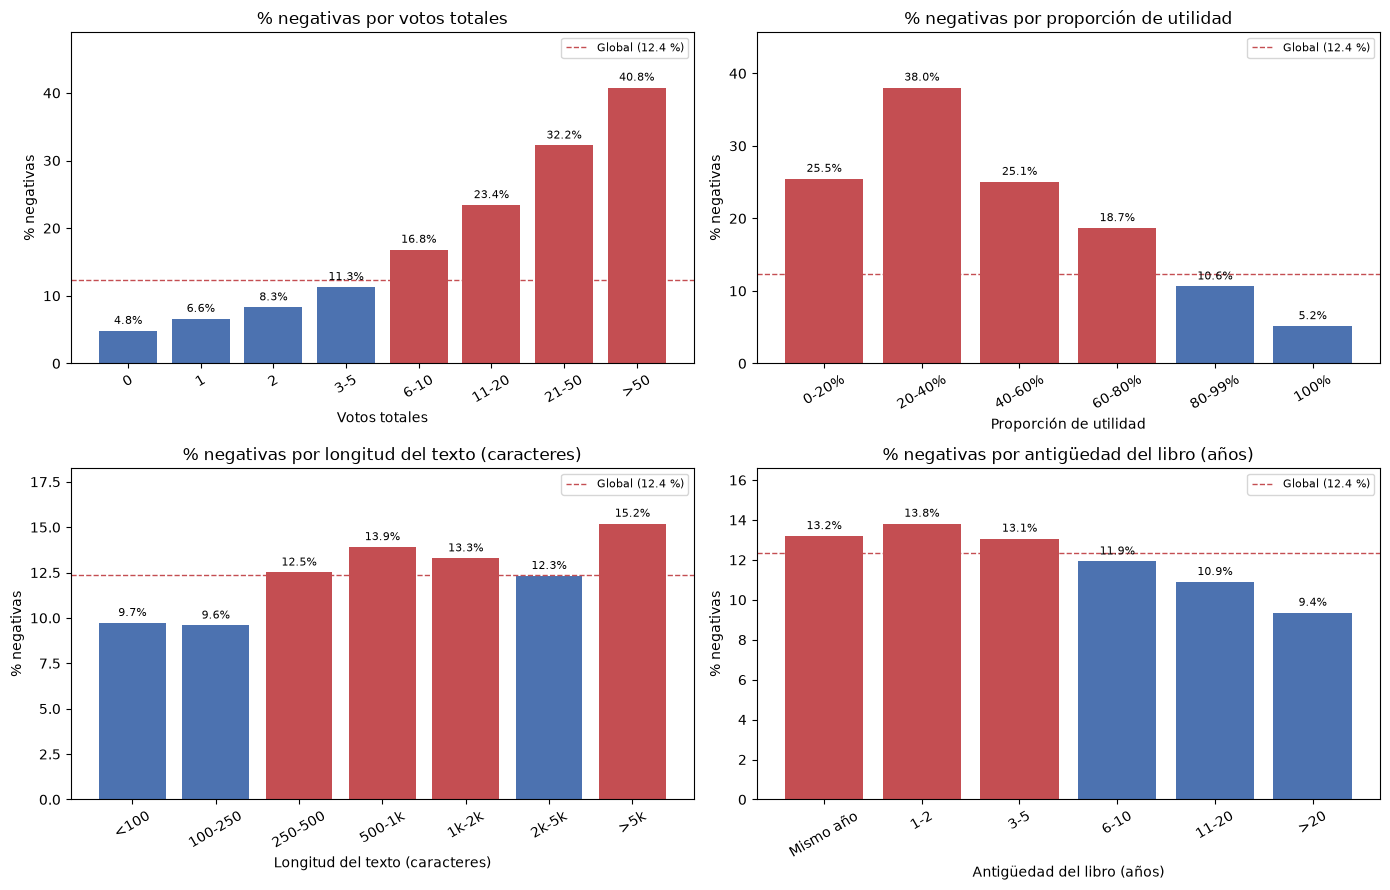

In [73]:
def tasa_por_tramo(col, cortes, etiquetas, vista="reviews_biv"):
    g = con.sql(f"""
        SELECT {col} AS v, COUNT(*) AS n, SUM(is_negative) AS neg
        FROM {vista} WHERE {col} IS NOT NULL GROUP BY v
    """).df()
    g["tramo"] = pd.cut(g["v"], bins=cortes, labels=etiquetas, include_lowest=True)
    t = g.groupby("tramo", observed=True)[["n", "neg"]].sum()
    t["pct_negativas"] = t["neg"] / t["n"] * 100
    t["pct_resenas"] = t["n"] / t["n"].sum() * 100
    return t.round(2)


def graficar_tramos(t, titulo, xlabel, ax):
    colores = ["#C44E52" if v > tasa_global else "#4C72B0" for v in t["pct_negativas"]]
    ax.bar(t.index.astype(str), t["pct_negativas"], color=colores)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
    ax.axhline(tasa_global, color="#C44E52", ls="--", lw=1, label=f"Global ({tasa_global:.1f} %)")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% negativas")
    ax.set_ylim(0, t["pct_negativas"].max() * 1.2)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)


tramos = {
    "votes_total": ([-1, 0, 1, 2, 5, 10, 20, 50, np.inf],
                    ["0", "1", "2", "3-5", "6-10", "11-20", "21-50", ">50"], "Votos totales"),
    "helpful_ratio": ([0, 0.2, 0.4, 0.6, 0.8, 0.99, 1],
                      ["0-20%", "20-40%", "40-60%", "60-80%", "80-99%", "100%"], "Proporción de utilidad"),
    "text_len": ([0, 100, 250, 500, 1000, 2000, 5000, np.inf],
                 ["<100", "100-250", "250-500", "500-1k", "1k-2k", "2k-5k", ">5k"], "Longitud del texto (caracteres)"),
    "antiguedad_libro": ([-1, 0, 2, 5, 10, 20, np.inf],
                         ["Mismo año", "1-2", "3-5", "6-10", "11-20", ">20"], "Antigüedad del libro (años)"),
}

res_tramos = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, (cortes, etiquetas, nombre)) in zip(axes.ravel(), tramos.items()):
    res_tramos[col] = tasa_por_tramo(col, cortes, etiquetas)
    graficar_tramos(res_tramos[col], f"% negativas por {nombre.lower()}", nombre, ax)
plt.tight_layout()
plt.show()

In [74]:
pd.concat(res_tramos, names=["variable", "tramo"])

n      neg  pct_negativas  pct_resenas
variable         tramo                                                 
votes_total      0          564808  27282.0           4.83        27.26
                 1          289002  19114.0           6.61        13.95
                 2          205740  17105.0           8.31         9.93
                 3-5        370366  41875.0          11.31        17.87
                 6-10       275472  46375.0          16.83        13.29
                 11-20      198693  46563.0          23.43         9.59
                 21-50      125948  40607.0          32.24         6.08
                 >50         42020  17145.0          40.80         2.03
helpful_ratio    0-20%      187379  47741.0          25.48        12.43
                 20-40%     105929  40308.0          38.05         7.03
                 40-60%     182085  45622.0          25.06        12.08
                 60-80%     229676  42908.0          18.68        15.24
                 80-99%     198089  21048.0          10.63        13.14
                 100%       604078  31156.0           5.16        40.08
text_len         <100        53870   5240.0           9.73         2.60
                 100-250    418762  40172.0           9.59        20.21
                 250-500    539426  67485.0          12.51        26.03
                 500-1k     552368  76855.0          13.91        26.66
                 1k-2k      342462  45519.0          13.29        16.53
                 2k-5k      149791  18459.0          12.32         7.23
                 >5k         15368   2336.0          15.20         0.74
antiguedad_libro Mismo año  158303  20891.0          13.20        15.50
                 1-2        205209  28362.0          13.82        20.10
                 3-5        174207  22771.0          13.07        17.06
                 6-10       182619  21778.0          11.93        17.88
                 11-20      149150  16252.0          10.90        14.61
                 >20        151586  14184.0           9.36        14.85

**Año de la reseña**

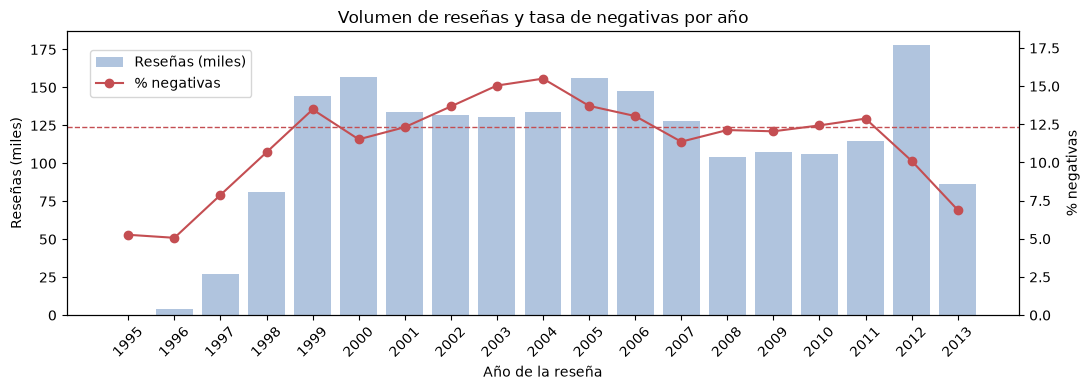

,review_year,n,pct_negativas
0,1995,190,5.26
1,1996,4008,5.06
2,1997,27131,7.88
3,1998,81102,10.67
4,1999,144180,13.47
5,2000,156867,11.52
6,2001,133994,12.31
7,2002,131873,13.67
8,2003,130437,15.04
9,2004,133631,15.50


In [75]:
anio = con.sql("""
    SELECT review_year, COUNT(*) AS n, AVG(is_negative) * 100 AS pct_negativas
    FROM reviews WHERE review_year IS NOT NULL
    GROUP BY review_year ORDER BY review_year
""").df()

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(anio["review_year"], anio["n"] / 1000, color="#B0C4DE", label="Reseñas (miles)")
ax1.set_ylabel("Reseñas (miles)")
ax1.set_xlabel("Año de la reseña")
ax2 = ax1.twinx()
ax2.plot(anio["review_year"], anio["pct_negativas"], color="#C44E52", marker="o", label="% negativas")
ax2.axhline(tasa_global, color="#C44E52", ls="--", lw=1)
ax2.set_ylabel("% negativas")
ax2.set_ylim(0, anio["pct_negativas"].max() * 1.2)
ax1.set_xticks(anio["review_year"])
ax1.tick_params(axis="x", rotation=45)
ax1.set_title("Volumen de reseñas y tasa de negativas por año")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
plt.tight_layout()
plt.show()

anio.round(2)

#### Variables categóricas vs `is_negative`

**Categoría del libro.** Complementa la gráfica anterior de % negativas por categoría: aquí se marcan en rojo las categorías por encima de la tasa global y se muestra el volumen de cada una.

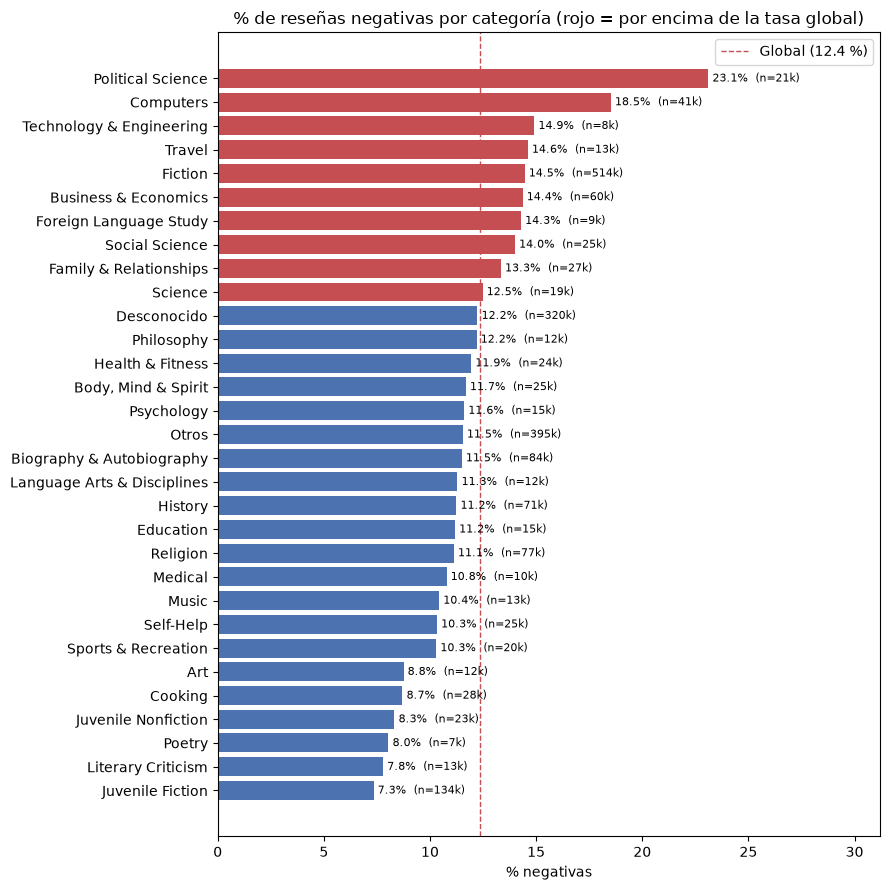

In [76]:
cat = con.sql("""
    SELECT category_group, COUNT(*) AS n, AVG(is_negative) * 100 AS pct_negativas
    FROM reviews GROUP BY category_group
    HAVING COUNT(*) >= 1000
    ORDER BY pct_negativas
""").df()

fig, ax = plt.subplots(figsize=(9, 9))
colores = ["#C44E52" if v > tasa_global else "#4C72B0" for v in cat["pct_negativas"]]
ax.barh(cat["category_group"], cat["pct_negativas"], color=colores)
ax.bar_label(ax.containers[0], labels=[f"{p:.1f}%  (n={n/1000:,.0f}k)" for p, n in zip(cat["pct_negativas"], cat["n"])],
             padding=3, fontsize=8)
ax.axvline(tasa_global, color="#C44E52", ls="--", lw=1, label=f"Global ({tasa_global:.1f} %)")
ax.set_xlim(0, cat["pct_negativas"].max() * 1.35)
ax.set_title("% de reseñas negativas por categoría (rojo = por encima de la tasa global)")
ax.set_xlabel("% negativas")
ax.legend()
plt.tight_layout()
plt.show()

**Distribución completa del puntaje por categoría.** Además de la variable binaria, se observa cómo se reparte el puntaje de 1 a 5 estrellas en las 12 categorías con más reseñas.

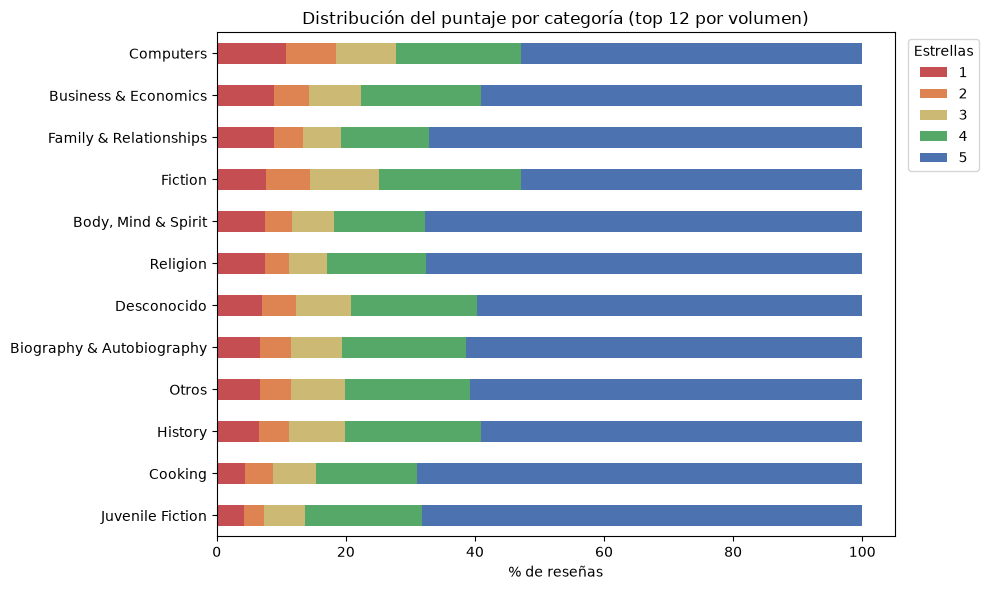

score,1,2,3,4,5
category_group,,,,,
Juvenile Fiction,4.2,3.1,6.3,18.1,68.2
Cooking,4.4,4.3,6.6,15.7,69.0
History,6.5,4.7,8.7,21.1,59.0
Otros,6.6,4.9,8.4,19.3,60.8
Biography & Autobiography,6.8,4.7,8.0,19.2,61.3
Desconocido,7.0,5.2,8.5,19.5,59.7
Religion,7.5,3.7,6.0,15.3,67.6
"Body, Mind & Spirit",7.5,4.2,6.5,14.1,67.7
Fiction,7.6,6.8,10.7,22.0,52.8


In [77]:
score_cat = con.sql("""
    WITH top AS (
        SELECT category_group FROM reviews GROUP BY category_group
        ORDER BY COUNT(*) DESC LIMIT 12
    )
    SELECT category_group, CAST(score AS INT) AS score, COUNT(*) AS n
    FROM reviews WHERE category_group IN (SELECT category_group FROM top)
    GROUP BY category_group, score
""").df()

tabla = score_cat.pivot(index="category_group", columns="score", values="n")
tabla = tabla.div(tabla.sum(axis=1), axis=0) * 100
tabla = tabla.sort_values([1, 2], ascending=True)

ax = tabla.plot.barh(stacked=True, figsize=(10, 6),
                     color=["#C44E52", "#DD8452", "#CCB974", "#55A868", "#4C72B0"])
ax.set_title("Distribución del puntaje por categoría (top 12 por volumen)")
ax.set_xlabel("% de reseñas")
ax.set_ylabel("")
ax.legend(title="Estrellas", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

tabla.round(1)

**Editorial y autor.** Se toman las 15 editoriales y los 15 autores con más reseñas (sin contar "desconocido").

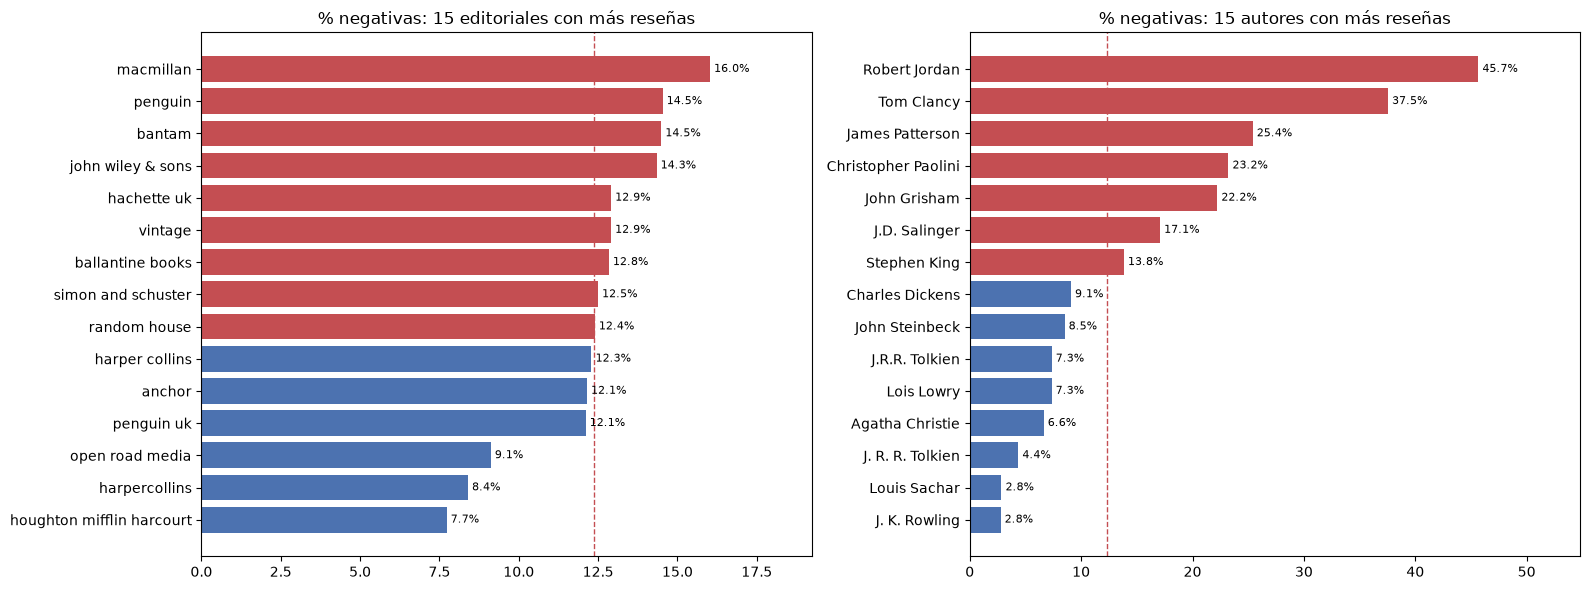

In [78]:
def tasa_top(col, top=15):
    return con.sql(f"""
        SELECT {col} AS grupo, COUNT(*) AS n, AVG(is_negative) * 100 AS pct_negativas
        FROM reviews
        WHERE {col} IS NOT NULL AND lower({col}) <> 'desconocido'
        GROUP BY grupo ORDER BY n DESC LIMIT {top}
    """).df().sort_values("pct_negativas")

edit = tasa_top("publisher_clean")
aut = tasa_top("main_author")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, d, titulo in [(axes[0], edit, "Editoriales"), (axes[1], aut, "Autores")]:
    colores = ["#C44E52" if v > tasa_global else "#4C72B0" for v in d["pct_negativas"]]
    ax.barh(d["grupo"], d["pct_negativas"], color=colores)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
    ax.axvline(tasa_global, color="#C44E52", ls="--", lw=1)
    ax.set_title(f"% negativas: 15 {titulo.lower()} con más reseñas")
    ax.set_xlim(0, d["pct_negativas"].max() * 1.2)
plt.tight_layout()
plt.show()

**Reseñas anónimas y libros sin metadatos.**

In [79]:
binarias = con.sql("""
    SELECT 'es_anonimo' AS variable, CAST(es_anonimo AS VARCHAR) AS valor,
           COUNT(*) AS n, AVG(is_negative) * 100 AS pct_negativas
    FROM reviews GROUP BY es_anonimo
    UNION ALL
    SELECT 'categoria_desconocida', CAST(category_group = 'Desconocido' AS VARCHAR),
           COUNT(*), AVG(is_negative) * 100
    FROM reviews GROUP BY category_group = 'Desconocido'
    UNION ALL
    SELECT 'sin_votos', CAST(votes_total = 0 AS VARCHAR),
           COUNT(*), AVG(is_negative) * 100
    FROM reviews GROUP BY votes_total = 0
    ORDER BY variable, valor
""").df()
binarias["pct_negativas"] = binarias["pct_negativas"].round(2)
binarias

,variable,valor,n,pct_negativas
0,categoria_desconocida,false,1752444,12.38
1,categoria_desconocida,true,319605,12.24
2,es_anonimo,false,1693304,11.67
3,es_anonimo,true,378745,15.42
4,sin_votos,false,1507241,15.18
5,sin_votos,true,564808,4.83


**Prueba chi-cuadrado y V de Cramér.** Para las variables categóricas se usa la prueba chi-cuadrado de independencia y la **V de Cramér** como medida de la fuerza de la asociación (0 = ninguna, 1 = total; en la práctica > 0,1 ya es relevante). Las tablas de contingencia se construyen con **todas** las reseñas. Para editorial y autor se toman los 50 grupos con más reseñas y el resto se agrupa en "Otros".

In [80]:
def cramer(col_sql, nombre):
    ct = con.sql(f"""
        SELECT {col_sql} AS g, is_negative, COUNT(*) AS n
        FROM reviews_biv GROUP BY g, is_negative
    """).df().pivot(index="g", columns="is_negative", values="n").fillna(0)
    chi2, p, gl, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    return {"variable": nombre, "categorias": len(ct), "chi2": round(chi2, 1), "gl": gl, "p_valor": p, "v_cramer": round(v, 4)}

def top_o_otros(col, top=50):
    return f"""CASE WHEN {col} IN (SELECT {col} FROM reviews GROUP BY {col} ORDER BY COUNT(*) DESC LIMIT {top})
                    THEN {col} ELSE 'Otros' END"""

tramo_votos = "CASE WHEN votes_total = 0 THEN '0' WHEN votes_total <= 2 THEN '1-2' WHEN votes_total <= 10 THEN '3-10' WHEN votes_total <= 50 THEN '11-50' ELSE '>50' END"
tramo_util = "CASE WHEN helpful_ratio IS NULL THEN 'sin votos' WHEN helpful_ratio < 0.5 THEN '<50%' WHEN helpful_ratio < 0.8 THEN '50-80%' ELSE '>=80%' END"
tramo_len = "CASE WHEN text_len < 250 THEN 'corta' WHEN text_len < 1000 THEN 'media' ELSE 'larga' END"
tramo_ant = "CASE WHEN antiguedad_libro IS NULL THEN 'sin dato' WHEN antiguedad_libro <= 2 THEN '0-2' WHEN antiguedad_libro <= 10 THEN '3-10' ELSE '>10' END"

asociacion = pd.DataFrame([
    cramer("category_group", "category_group"),
    cramer(top_o_otros("publisher_clean"), "publisher_clean (top 50)"),
    cramer(top_o_otros("main_author"), "main_author (top 50)"),
    cramer("es_anonimo", "es_anonimo"),
    cramer("review_year", "review_year"),
    cramer(tramo_votos, "votes_total (tramos)"),
    cramer(tramo_util, "helpful_ratio (tramos)"),
    cramer(tramo_len, "text_len (tramos)"),
    cramer(tramo_ant, "antiguedad_libro (tramos)"),
]).set_index("variable").sort_values("v_cramer", ascending=False)
asociacion

,categorias,chi2,gl,p_valor,v_cramer
variable,,,,,
helpful_ratio (tramos),4,182937.3,3,0.0,0.2971
votes_total (tramos),5,136507.5,4,0.0,0.2567
main_author (top 50),51,21355.6,50,0.0,0.1015
category_group,31,11303.3,30,0.0,0.0739
publisher_clean (top 50),51,7756.3,50,0.0,0.0612
review_year,20,7209.1,19,0.0,0.0590
text_len (tramos),3,4270.2,2,0.0,0.0454
es_anonimo,2,4011.0,1,0.0,0.0440
antiguedad_libro (tramos),4,1905.0,3,0.0,0.0303


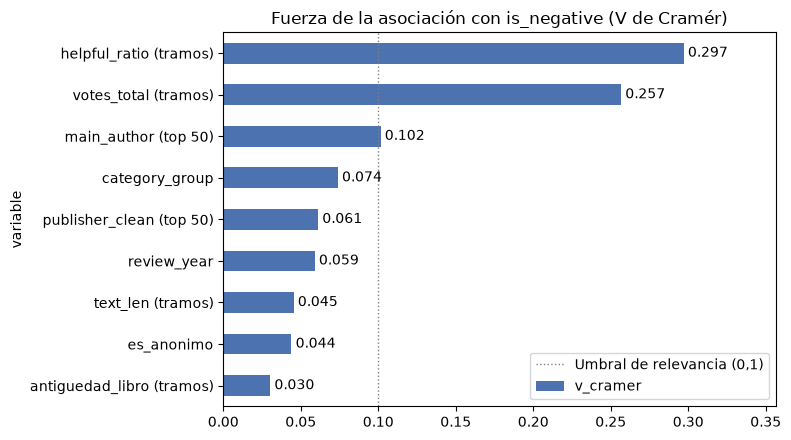

In [81]:
ax = asociacion["v_cramer"].sort_values().plot.barh(figsize=(8, 4.5), color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.axvline(0.1, color="gray", ls=":", lw=1, label="Umbral de relevancia (0,1)")
ax.set_title("Fuerza de la asociación con is_negative (V de Cramér)")
ax.set_xlim(0, asociacion["v_cramer"].max() * 1.2)
ax.legend()
plt.tight_layout()
plt.show()

### Conclusiones del análisis bivariado

1. **La reacción de la comunidad es la señal más fuerte.** La tasa de negativas sube sin interrupciones con los votos: 4,8 % en reseñas sin votos y 40,8 % en las que tienen más de 50. Con la utilidad pasa lo contrario: 5,2 % cuando el 100 % de los votos dice "útil" y entre 25 % y 38 % cuando la utilidad no pasa del 60 %. Son las únicas variables con un efecto de tamaño **mediano** (r = 0,42 y −0,42; V de Cramér = 0,26 y 0,30) y las únicas por encima del umbral de 0,1. Una reseña negativa genera más interacción y más desacuerdo. Sin embargo, los votos se acumulan **después** de publicar la reseña, así que explican el fenómeno pero no sirven para anticiparlo.
2. **La longitud del texto apenas discrimina.** Las negativas son un poco más largas (mediana de 568 caracteres frente a 506), pero la tasa por tramo varía entre 9,6 % y 15,2 % sin un patrón claro. El efecto es despreciable (r = 0,07; V = 0,045). Solo las reseñas muy cortas (< 250 caracteres) quedan algo por debajo de la tasa global.
3. **Los libros antiguos reciben menos críticas.** Los libros reseñados en sus primeros 5 años tienen entre 13 % y 14 % de negativas; los de más de 20 años, 9,4 %, posiblemente porque los clásicos ya pasaron un filtro de calidad. El efecto es débil (V = 0,03) y la variable tiene **50,7 % de nulos**: en muchos casos `published_year` corresponde a una edición posterior a la reseña. Por eso se usa con cautela.
4. **El año de la reseña muestra un ciclo.** La tasa pasa del 5 % en 1995-1996 a un máximo de 15,5 % en 2004, se estabiliza cerca del 12 % y cae a 6,9 % en 2013 (un año incompleto, cuyas reseñas aún no acumulan votos). Asociación débil (V = 0,059).
5. **La categoría marca diferencias, pero explica poco por sí sola.** *Political Science* (23,1 %) y *Computers* (18,5 %) triplican a *Juvenile Fiction* (7,3 %), *Literary Criticism* (7,8 %) y *Poetry* (8,0 %). *Fiction*, la categoría con más reseñas (514 mil), está por encima de la media (14,5 %). *Computers* tiene la mayor proporción de reseñas de 1 estrella (10,7 %). Aun así, la V de Cramér es apenas 0,074.
6. **El autor es la variable de catálogo más asociada (V = 0,10).** Sagas largas y autores de producción masiva concentran la insatisfacción (Robert Jordan 45,7 %, Tom Clancy 37,5 %, James Patterson 25,4 %), frente a J. K. Rowling o Louis Sachar (2,8 %). La editorial influye menos: va de 7,7 % a 16,0 % (V = 0,061). En ambas variables quedan nombres sin unificar ("J.R.R. Tolkien" / "J. R. R. Tolkien", "harper collins" / "harpercollins"), un ajuste pendiente de la limpieza.
7. **Las reseñas anónimas son más negativas** (15,4 % frente a 11,7 %), aunque la asociación es débil (V = 0,044). Los libros con categoría "Desconocido" tienen prácticamente la misma tasa que el resto (12,2 % frente a 12,4 %), así que **la falta de metadatos no sesga la variable objetivo**.

**Orden de importancia (V de Cramér):** utilidad > votos >> autor > categoría > editorial ≈ año de la reseña > longitud ≈ anonimato > antigüedad.

### - Análisis Multivariado

El análisis bivariado mira cada variable por separado. Aquí se revisa cómo se relacionan las variables entre sí y si su efecto sobre la insatisfacción se mantiene cuando se consideran juntas:

1. Matriz de correlación entre todas las variables numéricas y la variable objetivo.
2. Interacción entre votos totales y proporción de utilidad.
3. Interacción entre categoría y periodo.
4. Interacción entre anonimato y reacción de la comunidad.
5. Regresión logística con todas las variables a la vez, para ver el efecto de cada una controlando por las demás.

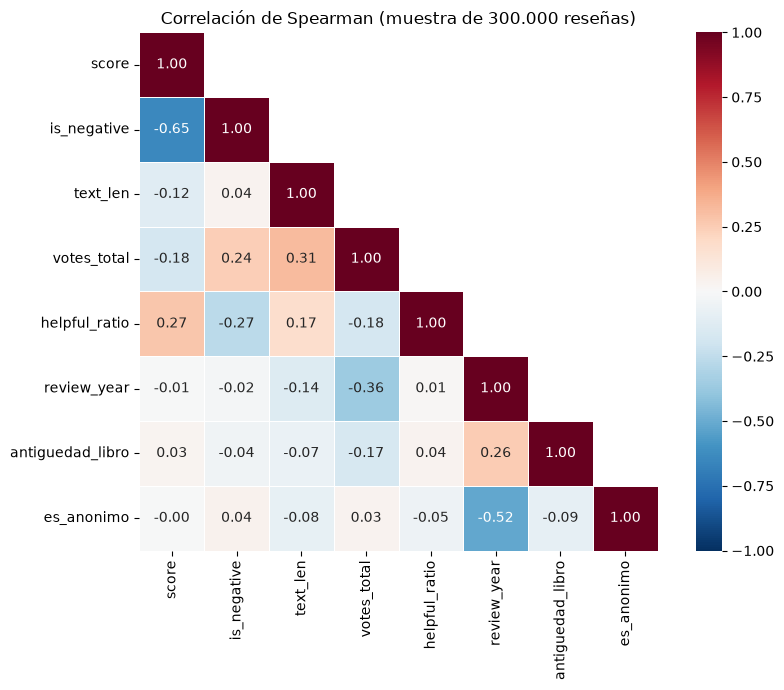

In [82]:
mm = con.sql("""
    SELECT score, is_negative, text_len, votes_total, helpful_ratio,
           review_year, antiguedad_libro, CAST(es_anonimo AS INT) AS es_anonimo
    FROM reviews_biv
    USING SAMPLE reservoir(300000 ROWS) REPEATABLE (42)
""").df()

corr = mm.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlación de Spearman (muestra de 300.000 reseñas)")
plt.tight_layout()
plt.show()

Se usa Spearman en lugar de Pearson porque las variables son muy asimétricas (votos, longitud) y la relación puede ser monótona sin ser lineal.

**Interacción votos totales × proporción de utilidad**

Solo para reseñas que recibieron al menos un voto. Cada celda muestra el % de reseñas negativas; se ocultan las celdas con menos de 500 reseñas.

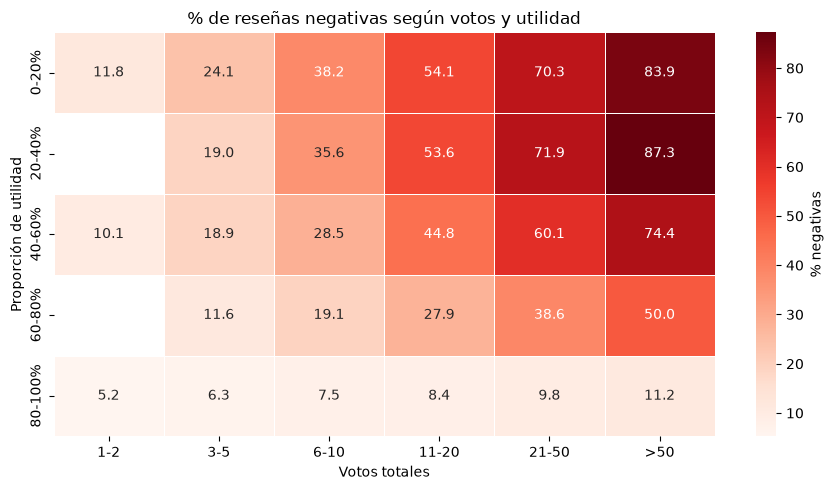

In [83]:
inter = con.sql("""
    SELECT CASE WHEN votes_total <= 2 THEN '1-2' WHEN votes_total <= 5 THEN '3-5'
                WHEN votes_total <= 10 THEN '6-10' WHEN votes_total <= 20 THEN '11-20'
                WHEN votes_total <= 50 THEN '21-50' ELSE '>50' END AS votos,
           CASE WHEN helpful_ratio < 0.2 THEN '0-20%' WHEN helpful_ratio < 0.4 THEN '20-40%'
                WHEN helpful_ratio < 0.6 THEN '40-60%' WHEN helpful_ratio < 0.8 THEN '60-80%'
                ELSE '80-100%' END AS utilidad,
           COUNT(*) AS n, AVG(is_negative) * 100 AS pct_negativas
    FROM reviews WHERE votes_total > 0
    GROUP BY votos, utilidad
""").df()

orden_v = ["1-2", "3-5", "6-10", "11-20", "21-50", ">50"]
orden_u = ["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"]
pct = inter.pivot(index="utilidad", columns="votos", values="pct_negativas").loc[orden_u, orden_v]
n = inter.pivot(index="utilidad", columns="votos", values="n").loc[orden_u, orden_v]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pct.where(n >= 500), annot=True, fmt=".1f", cmap="Reds", linewidths=0.5,
            cbar_kws={"label": "% negativas"}, ax=ax)
ax.set_title("% de reseñas negativas según votos y utilidad")
ax.set_xlabel("Votos totales")
ax.set_ylabel("Proporción de utilidad")
plt.tight_layout()
plt.show()

**Interacción categoría × periodo**

Las 12 categorías con más reseñas, en cuatro periodos de tiempo.

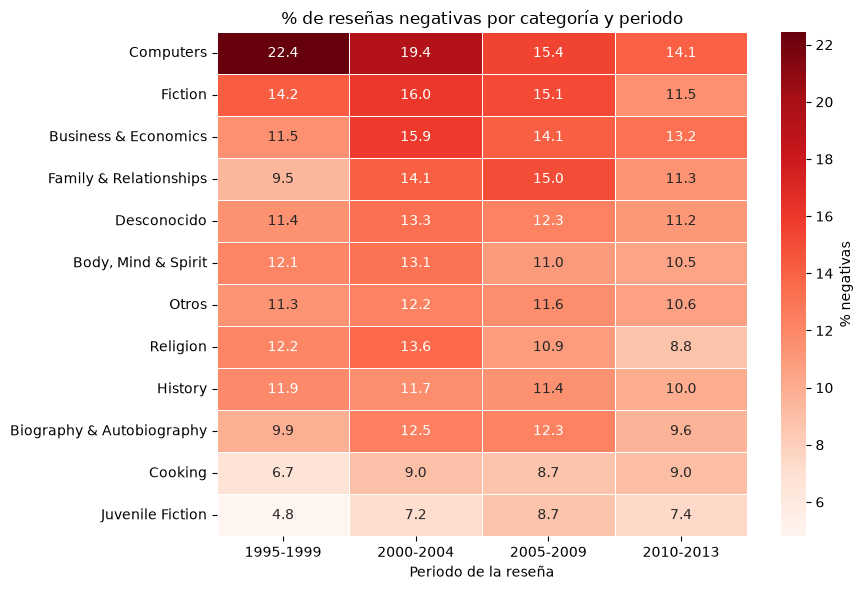

In [84]:
cat_per = con.sql("""
    WITH top AS (
        SELECT category_group FROM reviews GROUP BY category_group
        ORDER BY COUNT(*) DESC LIMIT 12
    )
    SELECT category_group,
           CASE WHEN review_year <= 1999 THEN '1995-1999' WHEN review_year <= 2004 THEN '2000-2004'
                WHEN review_year <= 2009 THEN '2005-2009' ELSE '2010-2013' END AS periodo,
           COUNT(*) AS n, AVG(is_negative) * 100 AS pct_negativas
    FROM reviews
    WHERE category_group IN (SELECT category_group FROM top) AND review_year IS NOT NULL
    GROUP BY category_group, periodo
""").df()

pct_cp = cat_per.pivot(index="category_group", columns="periodo", values="pct_negativas")
n_cp = cat_per.pivot(index="category_group", columns="periodo", values="n")
pct_cp = pct_cp.loc[pct_cp.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pct_cp.where(n_cp.loc[pct_cp.index] >= 300), annot=True, fmt=".1f", cmap="Reds",
            linewidths=0.5, cbar_kws={"label": "% negativas"}, ax=ax)
ax.set_title("% de reseñas negativas por categoría y periodo")
ax.set_xlabel("Periodo de la reseña")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Interacción anonimato × votos totales**

Se revisa si la diferencia entre reseñas anónimas e identificadas se mantiene en cada nivel de votos, o si solo se debe a que unas reciben más votos que otras.

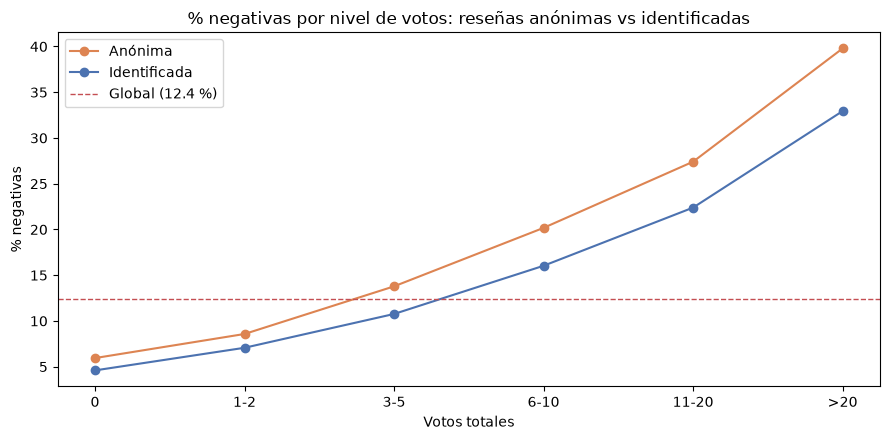

votos,0,1-2,3-5,6-10,11-20,>20
usuario,,,,,,
Anónima,98623,83193,66700,53416,41388,35425
Identificada,466185,411549,303666,222056,157305,132543


In [85]:
anon = con.sql("""
    SELECT CASE WHEN votes_total = 0 THEN '0' WHEN votes_total <= 2 THEN '1-2'
                WHEN votes_total <= 5 THEN '3-5' WHEN votes_total <= 10 THEN '6-10'
                WHEN votes_total <= 20 THEN '11-20' ELSE '>20' END AS votos,
           CASE WHEN es_anonimo THEN 'Anónima' ELSE 'Identificada' END AS usuario,
           COUNT(*) AS n, AVG(is_negative) * 100 AS pct_negativas
    FROM reviews GROUP BY votos, usuario
""").df()

orden = ["0", "1-2", "3-5", "6-10", "11-20", ">20"]
tabla_anon = anon.pivot(index="votos", columns="usuario", values="pct_negativas").loc[orden]

ax = tabla_anon.plot(marker="o", figsize=(9, 4.5), color={"Anónima": "#DD8452", "Identificada": "#4C72B0"})
ax.axhline(tasa_global, color="#C44E52", ls="--", lw=1, label=f"Global ({tasa_global:.1f} %)")
ax.set_title("% negativas por nivel de votos: reseñas anónimas vs identificadas")
ax.set_xlabel("Votos totales")
ax.set_ylabel("% negativas")
ax.legend()
plt.tight_layout()
plt.show()

anon.pivot(index="votos", columns="usuario", values="n").loc[orden].T

In [86]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

d = con.sql("""
    SELECT is_negative, text_len, votes_total, helpful_ratio, review_year,
           antiguedad_libro, CAST(es_anonimo AS INT) AS es_anonimo, category_group
    FROM reviews_biv WHERE text_len IS NOT NULL AND review_year IS NOT NULL
    USING SAMPLE reservoir(300000 ROWS) REPEATABLE (7)
""").df()

X = pd.DataFrame({
    "log_votes_total": np.log1p(d["votes_total"]),
    "helpful_ratio": d["helpful_ratio"].fillna(d["helpful_ratio"].median()),
    "sin_votos": d["helpful_ratio"].isna().astype(int),
    "log_text_len": np.log1p(d["text_len"]),
    "review_year": d["review_year"],
    "antiguedad_libro": d["antiguedad_libro"].fillna(d["antiguedad_libro"].median()),
    "sin_antiguedad": d["antiguedad_libro"].isna().astype(int),
    "es_anonimo": d["es_anonimo"],
})
continuas = ["log_votes_total", "helpful_ratio", "log_text_len", "review_year", "antiguedad_libro"]
X[continuas] = StandardScaler().fit_transform(X[continuas])
dummies = pd.get_dummies(d["category_group"], prefix="cat", dtype=int).drop(columns="cat_Fiction")
X = pd.concat([X, dummies], axis=1)
y = d["is_negative"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
logit = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)
print(f"ROC-AUC en prueba: {roc_auc_score(y_te, logit.predict_proba(X_te)[:, 1]):.3f}")

coef = pd.DataFrame({"coef": logit.coef_[0], "odds_ratio": np.exp(logit.coef_[0])}, index=X.columns)
coef_base = coef.loc[[c for c in X.columns if not c.startswith("cat_")]].sort_values("odds_ratio")
coef_base.round(3)

ROC-AUC en prueba: 0.775


,coef,odds_ratio
helpful_ratio,-0.632,0.531
sin_antiguedad,-0.104,0.901
antiguedad_libro,-0.052,0.949
log_text_len,0.072,1.074
review_year,0.432,1.540
sin_votos,0.648,1.913
es_anonimo,0.723,2.060
log_votes_total,0.988,2.686


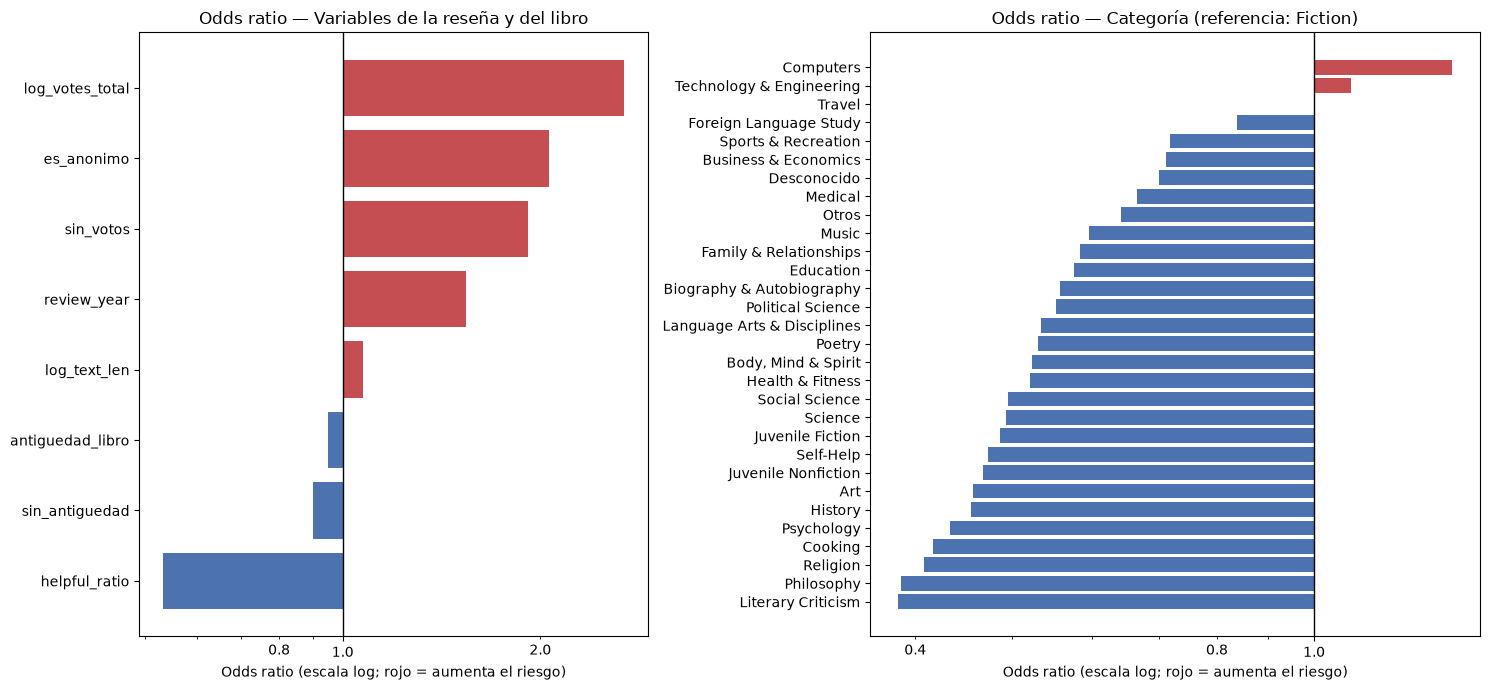

In [87]:
coef_cat = coef.loc[[c for c in X.columns if c.startswith("cat_")]].sort_values("odds_ratio")
coef_cat.index = coef_cat.index.str.replace("cat_", "")

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1.2]})
for ax, c, titulo in [(axes[0], coef_base, "Variables de la reseña y del libro"),
                      (axes[1], coef_cat, "Categoría (referencia: Fiction)")]:
    colores = ["#C44E52" if v > 1 else "#4C72B0" for v in c["odds_ratio"]]
    ax.barh(c.index, c["odds_ratio"] - 1, left=1, color=colores)
    ax.axvline(1, color="black", lw=1)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}"))
    ax.xaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}" if v in (0.4, 0.6, 0.8, 1.5, 2, 3) else ""))
    ax.set_title(f"Odds ratio — {titulo}")
    ax.set_xlabel("Odds ratio (escala log; rojo = aumenta el riesgo)")
plt.tight_layout()
plt.show()

### Conclusiones del análisis multivariado

1. **No hay multicolinealidad problemática.** La correlación más alta entre predictores es la de anonimato y año de la reseña (−0,52): las reseñas anónimas se concentran en los primeros años (promedio de 2000 frente a 2006 en las identificadas). Los votos se correlacionan con la longitud (0,32) y con el año (−0,36): las reseñas largas y las antiguas acumulan más votos.
2. **Lo que importa es el desacuerdo, no la cantidad de votos.** Cuando una reseña tiene más de 50 votos y una utilidad de 40 % o menos, entre el 84 % y el 87 % son negativas. Si la utilidad es de 80 % o más, la tasa se queda por debajo del 11,2 % aunque tenga muchos votos. Las reseñas negativas reciben muchos votos de "no útil", probablemente de lectores que sí disfrutaron el libro. Las celdas vacías corresponden a combinaciones imposibles (por ejemplo, 1 o 2 votos con 20-40 % de utilidad) o con menos de 500 reseñas.
3. **El efecto de la categoría es estable en el tiempo.** *Computers* es la categoría más crítica en los cuatro periodos, aunque baja de 22,4 % a 14,1 %. *Juvenile Fiction* y *Cooking* son siempre las más bajas. En casi todas las categorías el pico está en 2000-2004, igual que en la serie anual.
4. **El efecto del anonimato no se debe a los votos.** Las reseñas anónimas son más negativas en todos los niveles de votos: 5,9 % frente a 4,6 % sin votos, y 39,8 % frente a 32,9 % con más de 20 votos.
5. **La regresión logística confirma unos efectos y corrige otros** (ROC-AUC = 0,777):
   - Votos (OR = 2,65 por desviación estándar del logaritmo) y utilidad (OR = 0,54) siguen siendo los efectos más fuertes.
   - El **anonimato duplica las probabilidades** de una reseña negativa (OR = 2,0), un efecto mayor que en el análisis bivariado. Las reseñas anónimas son antiguas, y una vez se controlan los votos, las reseñas antiguas resultan menos negativas.
   - El **año de la reseña** (OR = 1,52) parecía irrelevante en el análisis bivariado, pero al controlar los votos se ve que las reseñas más recientes son más negativas. Las reseñas antiguas acumulaban más votos y eso escondía el efecto.
   - Al controlar las demás variables, *Political Science* queda **por debajo** de *Fiction*: su tasa alta se explica porque sus reseñas son muy votadas (mediana de 12 votos frente a 2 en *Fiction*), es decir, polémicas. *Computers* es la única categoría que sigue por encima de *Fiction* (OR ≈ 1,2), así que su insatisfacción sí es propia de la categoría.
   - La longitud del texto (OR = 1,06) y la antigüedad del libro (OR = 0,95) prácticamente no aportan cuando se consideran las demás variables.

**Implicaciones para el modelado:** las variables con más poder son los votos, la utilidad, el anonimato, el año de la reseña, el autor y la categoría. Como los votos y la utilidad solo existen después de publicar la reseña, conviene entrenar dos modelos: uno **explicativo** con todas las variables y uno **predictivo** solo con información disponible al momento de la reseña (categoría, autor, editorial, anonimato, año y longitud), para medir cuánto se puede anticipar la insatisfacción.

### **c. Análisis preliminar del conjunto de datos y necesidad de información adicional de contexto**

Con la exploración anterior se revisa si los datos alcanzan para cumplir el objetivo (identificar qué características del libro y de la reseña se asocian con la insatisfacción del lector) o si se necesita información de contexto que no está en el conjunto de datos. Se evalúan tres aspectos:

1. **Calidad y completitud** de las variables que se usan en el análisis.
2. **Cobertura y representatividad**: qué reseñas, libros, usuarios y periodo cubre el conjunto.
3. **Vacíos de información** que limitan las conclusiones y qué fuentes externas podrían cubrirlos.

#### Calidad y completitud de las variables

Se retoma el análisis de atípicos realizado previamente

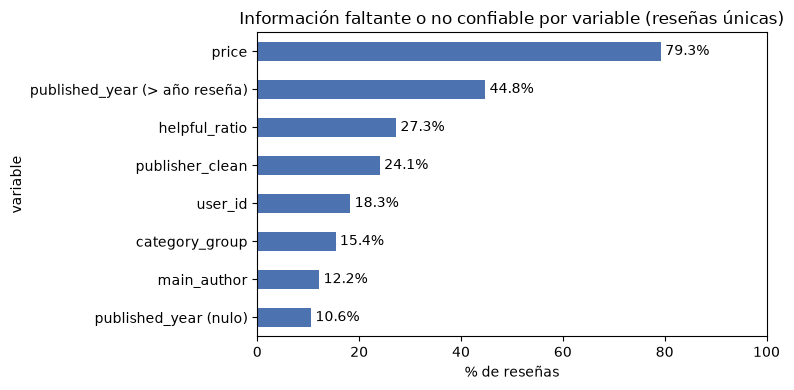

,variable,pct_faltante,descripcion
0,price,79.3,Precio del libro
1,published_year (> año reseña),44.8,Año de publicación posterior a la reseña (reed...
2,helpful_ratio,27.3,Utilidad sin calcular (reseña sin votos)
3,publisher_clean,24.1,Editorial
4,user_id,18.3,Usuario anónimo
5,category_group,15.4,Categoría del libro
6,main_author,12.2,Autor
7,published_year (nulo),10.6,Año de publicación sin dato


In [88]:
calidad = con.sql("""
    SELECT 'price' AS variable, AVG((price IS NULL)::INT) * 100 AS pct_faltante,
           'Precio del libro' AS descripcion FROM reviews
    UNION ALL SELECT 'category_group', AVG((category_group = 'Desconocido')::INT) * 100,
           'Categoría del libro' FROM reviews
    UNION ALL SELECT 'publisher_clean', AVG((publisher_clean = 'Desconocido')::INT) * 100,
           'Editorial' FROM reviews
    UNION ALL SELECT 'main_author', AVG((main_author = 'Desconocido')::INT) * 100,
           'Autor' FROM reviews
    UNION ALL SELECT 'published_year (nulo)', AVG((published_year IS NULL)::INT) * 100,
           'Año de publicación sin dato' FROM reviews
    UNION ALL SELECT 'published_year (> año reseña)', AVG((published_year > review_year)::INT) * 100,
           'Año de publicación posterior a la reseña (reedición)' FROM reviews
    UNION ALL SELECT 'user_id', AVG(es_anonimo::INT) * 100,
           'Usuario anónimo' FROM reviews
    UNION ALL SELECT 'helpful_ratio', AVG((helpful_ratio IS NULL)::INT) * 100,
           'Utilidad sin calcular (reseña sin votos)' FROM reviews
""").df()
calidad["pct_faltante"] = calidad["pct_faltante"].round(1)
calidad = calidad.sort_values("pct_faltante", ascending=False).reset_index(drop=True)

ax = calidad.set_index("variable")["pct_faltante"].sort_values().plot.barh(figsize=(8, 4), color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("Información faltante o no confiable por variable (reseñas únicas)")
ax.set_xlabel("% de reseñas")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

calidad

#### Cobertura y representatividad

Se revisa cómo se reparten las reseñas entre libros y usuarios. Si pocos libros o usuarios concentran la mayoría de las reseñas, los resultados agregados reflejan sobre todo a esos libros y usuarios.

In [89]:
cobertura = con.sql("""
    WITH libros AS (SELECT title_norm, COUNT(*) AS n FROM reviews GROUP BY title_norm),
         orden AS (SELECT n, ROW_NUMBER() OVER (ORDER BY n DESC) AS posicion,
                          COUNT(*) OVER () AS total_libros, SUM(n) OVER () AS total_resenas
                   FROM libros),
         usuarios AS (SELECT user_id, COUNT(*) AS n FROM reviews
                      WHERE user_id IS NOT NULL GROUP BY user_id)
    SELECT
        (SELECT MIN(review_year) FROM reviews) AS anio_inicial,
        (SELECT MAX(review_year) FROM reviews) AS anio_final,
        (SELECT MAX(total_libros) FROM orden) AS libros,
        (SELECT SUM(n) FILTER (WHERE posicion <= total_libros * 0.01) * 100.0 / MAX(total_resenas) FROM orden)
            AS pct_resenas_top_1pct_libros,
        (SELECT SUM(n) FILTER (WHERE posicion <= total_libros * 0.10) * 100.0 / MAX(total_resenas) FROM orden)
            AS pct_resenas_top_10pct_libros,
        (SELECT MEDIAN(n) FROM libros) AS mediana_resenas_por_libro,
        (SELECT COUNT(*) FROM usuarios) AS usuarios_identificados,
        (SELECT AVG((n = 1)::INT) * 100 FROM usuarios) AS pct_usuarios_una_resena,
        (SELECT MAX(n) FROM usuarios) AS max_resenas_un_usuario
""").df().T.rename(columns={0: "valor"})
cobertura["valor"] = cobertura["valor"].astype(float).round(1)
cobertura

,valor
anio_inicial,1995.0
anio_final,2013.0
libros,199058.0
pct_resenas_top_1pct_libros,32.4
pct_resenas_top_10pct_libros,66.6
mediana_resenas_por_libro,3.0
usuarios_identificados,1008972.0
pct_usuarios_una_resena,81.3
max_resenas_un_usuario,5201.0


#### Hallazgos del análisis preliminar

**Los datos permiten responder**

- **Volumen suficiente:** 2.072.049 reseñas únicas de 199.058 libros, en un periodo de 19 años (1995-2013). Es suficiente para comparar grupos (categorías, autores, tramos de votos) con estimaciones estables.
- **La variable objetivo es confiable:** score no tiene nulos, y la variable objetivo is_negative(12,36 % de reseñas negativas) se construye directamente a partir de ella.
- **Las variables de la reseña están completas:** longitud del texto, votos y fecha prácticamente no tienen faltantes. Son justamente las más asociadas con la insatisfacción según el bivariado y el multivariado.

**Lo que limita el análisis**

1. **Duplicados:** el 30,9 % de las filas originales eran la misma reseña repetida para distintas ediciones de un libro. Ya se eliminaron, pero muestra que el conjunto de Kaggle no es una muestra limpia de reseñas.
2. **Precio:** falta en cerca del 80 % de las reseñas únicas. No se puede analizar si los libros más caros generan más insatisfacción, razón por la cual se eliminó del análisis.
3. **Metadatos del libro incompletos:** el 15 % de las reseñas no tiene categoría, el 24 % no tiene editorial y el 12 % no tiene autor. 
4. **Concentración:** el 1 % de los libros reúne cerca de un tercio de las reseñas y el 10 % reúne dos tercios, mientras que la mediana es de 3 reseñas por libro. Los resultados por categoría o editorial están dominados por los títulos más populares.
5. **Usuarios:** el 18 % de las reseñas es anónimo y el 81 % de los usuarios identificados escribió una sola reseña. No se puede estudiar el comportamiento de un mismo lector a lo largo del tiempo.
6. **Periodo:** los datos terminan en 2013. Los patrones pueden no reflejar el comportamiento actual de los lectores ni de la plataforma.

#### Se requiere información adicional de contexto?

 Para el objetivo planteado, los datos actuales son suficientes. Para pasar de asociación a explicación, o para usar los resultados en decisiones hace falta información de contexto que el conjunto de datos no trae o no es suficiente:

| Vacío identificado | Información de contexto necesaria | De donde sacarlo | Para qué serviría |
|---|---|---|---|
| Precio faltante (Al tener tanto % de nulos, se excluye del análisis) | Precio del libro al momento de la reseña | Historial de precios del catálogo de Amazon o del distribuidor | Evaluar si el precio (relación calidad-precio) influye en la insatisfacción
| Edición y año de publicación no confiables | Identificador de la edición (ISBN) y fecha de publicación original | APIs de Google Books u Open Library | Medir bien la antigüedad del libro y separar reediciones |
| Categoría, editorial y autor faltantes  | Metadatos completos del libro | Google Books u Open Library, buscando por ISBN o título | Recuperar las reseñas que hoy quedan como "Desconocido" |
| Contenido de la reseña | Sentimiento o temas del texto (no se usó, solo su longitud) | Análisis de texto sobre `review/text` (procesamiento de lenguaje natural) | Saber por qué está insatisfecho el lector: precio, edición, contenido, envío |
| Periodo 1995-2013 | Reseñas posteriores a 2013 | Versiones actualizadas del mismo corpus | Verificar si los patrones se mantienen en el tiempo |

Así pues, el análisis preliminar indica que el conjunto de datos es adecuado para el objetivo exploratorio del proyecto.El contexto más útil y fácil de conseguir son los metadatos de Google Books u Open Library, que completarían la categoría, el autor y la fecha de publicación. Sin embargo, no se incorporó esta información porque el objetivo es exploratorio y los registros sin metadatos tienen una tasa de reseñas negativas prácticamente igual a la del resto (12,2 % frente a 12,4 %), por lo que su ausencia no sesga los resultados. Además, resulta más dificil conseguir estos datos, teniendo en cuenta que la base de datos no presenta un identificador de los libros (ISBN), haciendo que el cruce de información se de unicamente por el título y la base usada ya contine información disponible de Google Books.

Es claro que el análisis de sentimiento del texto aportaría el porqué de la insatisfacción sin necesidad de fuentes externas.

### **d. Flujo con Prefect**

Se construyó un flujo de trabajo ETL con Prefect (**flujo_analitica/etl_analitica.py**), siguiendo la estructura vista en clase: cada paso del proceso es una tarea (@task) y el flujo completo se define con @flow. 

El flujo extrae las reseñas y los libros desde los archivos CSV originales, aplica la misma limpieza del análisis exploratorio (construcción de la variable objetivo is_negative, normalización de títulos y eliminación de reseñas duplicadas entre ediciones de un mismo libro), une ambas tablas y genera dos analíticas. 

- Libros en alerta, identifica los 20 libros con mayor porcentaje de reseñas negativas entre los que tienen al menos 50 reseñas, e indica su autor, categoría y cuántas veces superan la tasa global de insatisfacción. Esto permite señalar títulos concretos para revisar en el catálogo. 

- La segunda, reseñas negativas por año de publicación, calcula el porcentaje de reseñas negativas según el año en que se publicó el libro. Solo se usan años plausibles y no posteriores a la reseña, para excluir reediciones, y años con al menos 1.000 reseñas. Así se observa si los libros de ciertos periodos generan más insatisfacción. 

Ambos resultados se guardan como archivos CSV en flujo_analitica/archivos_csv/. El flujo es recurrente, porque cada ejecución queda en Prefect con un nombre que incluye la fecha y la hora. Es escalable, porque no lee un archivo fijo sino todos los archivos Books_rating*.csv de la carpeta de datos, procesados por bloques con Dask. Si llega un conjunto de datos nuevo con la misma estructura, solo se debe dejar en esa carpeta y volver a ejecutar el flujo para que transforme los datos y recalcule ambas analíticas. 

A continuación se muestra las ejecuciones del flujo en la interfaz de Prefect, con cada una de sus tareas completadas.

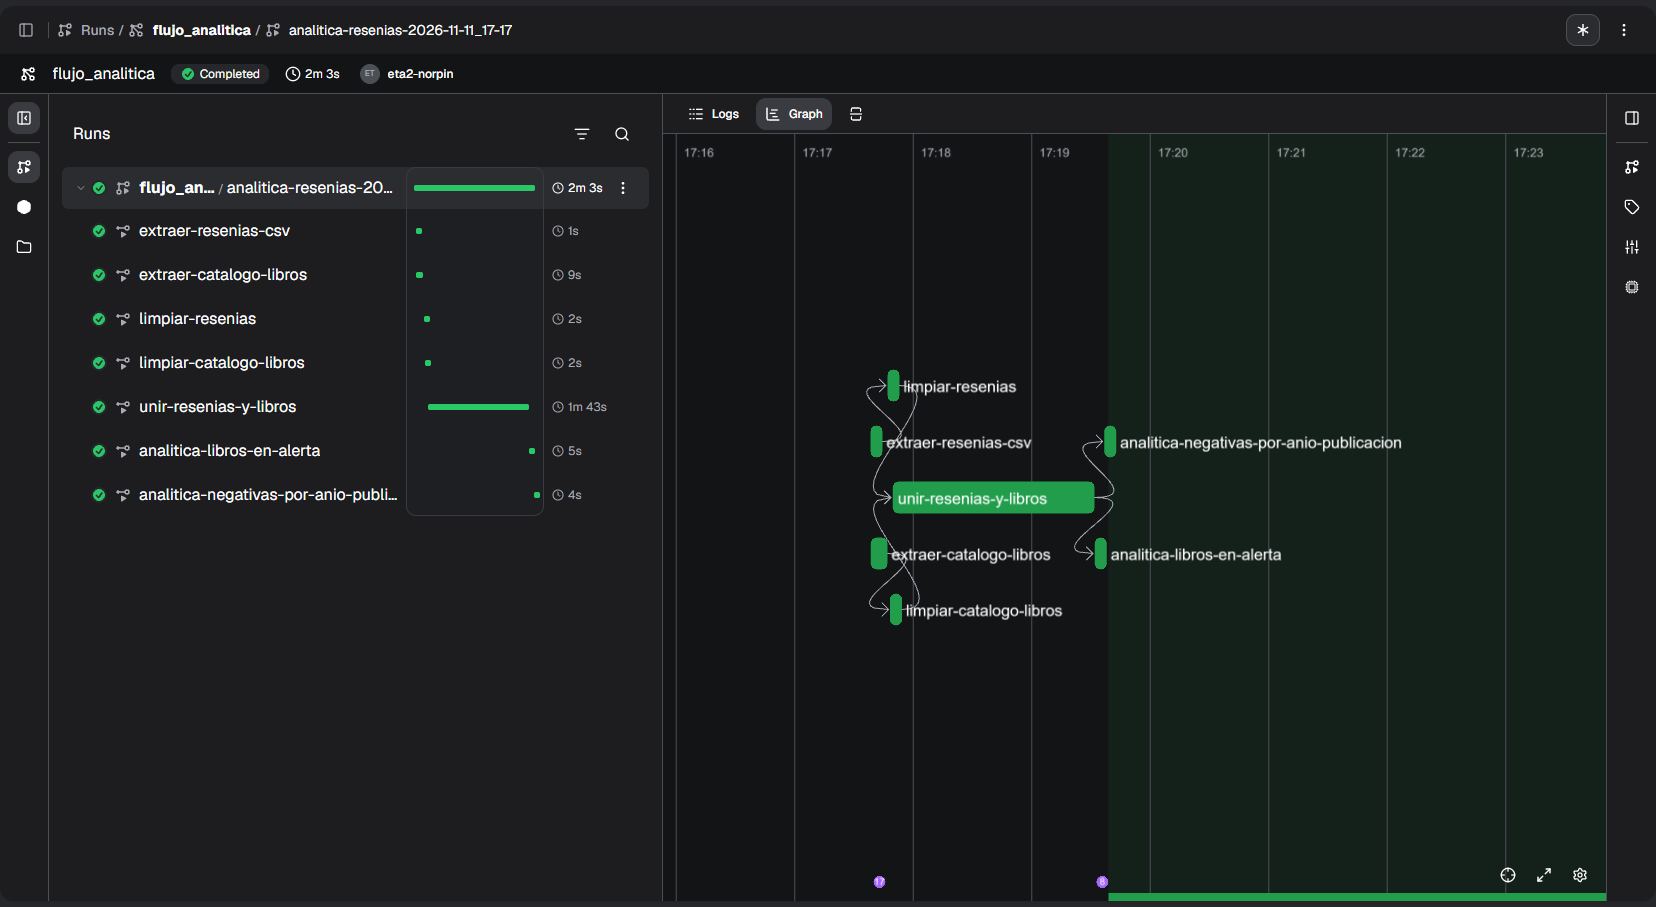

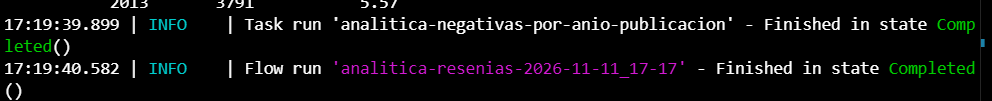

### **e. Uso de Dask: configurando workers y memoria**

Si bien dentro del EDA se hizo uso de dask, configurando fstintos workers y memorias para correr un proceso de estaidsticas simples, se decidió realizar otra ejecución aqui:

Así pues, se lanzó un scheduler y sus workers manualmente desde la terminal, en lugar de crearlos desde Python. Así los recursos de cada worker se definen al lanzarlos y el notebook solo se conecta como cliente al scheduler.

Se compararon dos configuraciones con la **misma memoria total (4 GB)** repartida de forma distinta, ejecutando la misma operación sobre las 2.072.049 reseñas limpias: estadísticas descriptivas de las variables numéricas y % de reseñas negativas por categoría.

| | Workers | Hilos por worker | Memoria por worker | Total |
|---|---|---|---|---|
| Configuración 1 | 2 | 1 | 2 GB | 4 GB |
| Configuración 2 | 4 | 1 | 1 GB | 4 GB |


Esto fue lo que se realizó en las distintas termianles:

**Terminal 1: scheduler**

dask scheduler

**Terminal 2: workers de la configuración 1**

dask worker tcp://127.0.0.1:8786 --nworkers 2 --nthreads 1 --memory-limit 2GB --name config1

**Terminal 2: workers de la configuración 2**

dask worker tcp://127.0.0.1:8786 --nworkers 4 --nthreads 1 --memory-limit 1GB --name config2


In [108]:
from dask.distributed import Client
import dask.dataframe as dd
import time

client = Client("tcp://127.0.0.1:8786")      # se conecta al scheduler que lanzaste en la terminal

for direccion, w in client.scheduler_info()["workers"].items():
    print(w["name"], "| hilos:", w["nthreads"], "| memoria:", round(w["memory_limit"] / 1e9, 2), "GB")

config1-1 | hilos: 1 | memoria: 2.0 GB
config1-0 | hilos: 1 | memoria: 2.0 GB


2026-11-11 18:05:13,481 - distributed.client - ERROR - 
Traceback (most recent call last):
  File "c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\utils.py", line 821, in wrapper
    return await func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\client.py", line 1533, in _reconnect
    await self._ensure_connected(timeout=timeout)
  File "c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\client.py", line 1562, in _ensure_connected
    comm = await connect(
           ^^^^^^^^^^^^^^
        self.scheduler.address, timeout=timeout, **self.connection_args
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "c:\Users\sahus\miniconda3\envs\proyecto-bigdata\Lib\site-packages\distributed\comm\core.py", line 342, in connect
    comm = await wait_for(
           ^^^^^^^^^^^^^^^
    ...<2 lines>...
    )


In [109]:
client

<Client: 'tcp://192.168.80.93:8786' processes=2 threads=2, memory=3.73 GiB>

- Configuración 1:

In [120]:
def medir(nombre_config):
    datos = dd.read_parquet((DATOS_SILVER / "reviews_libros").as_posix(),
                            columns=["score", "text_len", "votes_total", "helpful_ratio",
                                     "review_year", "category_group", "is_negative"])
    numericas = ["score", "text_len", "votes_total", "helpful_ratio", "review_year"]

    inicio = time.perf_counter()
    descriptivos = datos[numericas].astype("float64").describe().compute()
    por_categoria = datos.groupby("category_group")["is_negative"].mean().compute()
    tiempo = time.perf_counter() - inicio

    workers = list(client.scheduler_info()["workers"].values())
    print(f"{nombre_config}: {tiempo:.2f} s")
    return {"Configuración": nombre_config,
            "Workers": len(workers),
            "Hilos por worker": workers[0]["nthreads"],
            "Memoria por worker (GB)": round(workers[0]["memory_limit"] / 1e9, 2),
            "Tiempo (s)": round(tiempo, 2)}

resultado1 = medir("Configuración 1")

Configuración 1: 18.94 s


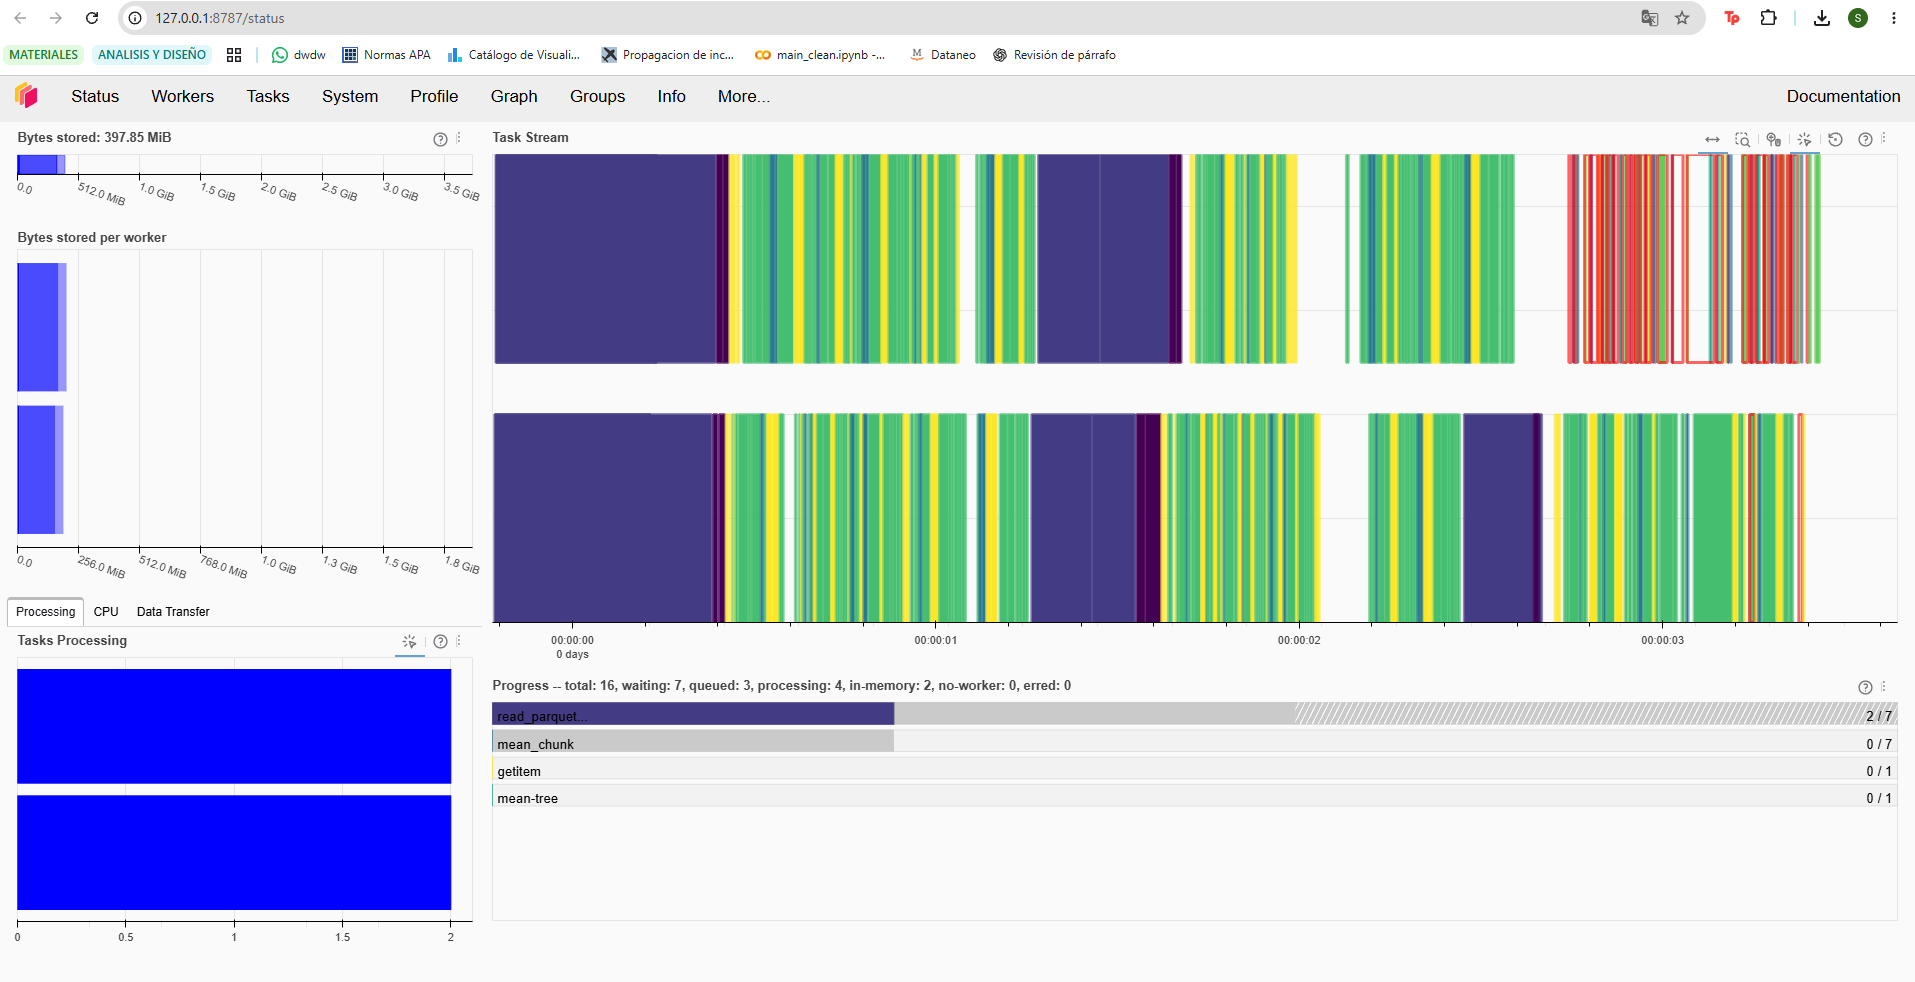

Esta es la imagen del localhost en donde se ve a los 2 workers trabjando

- Configuración 2:

In [121]:
resultado2 = medir("Configuración 2")

Configuración 2: 10.59 s


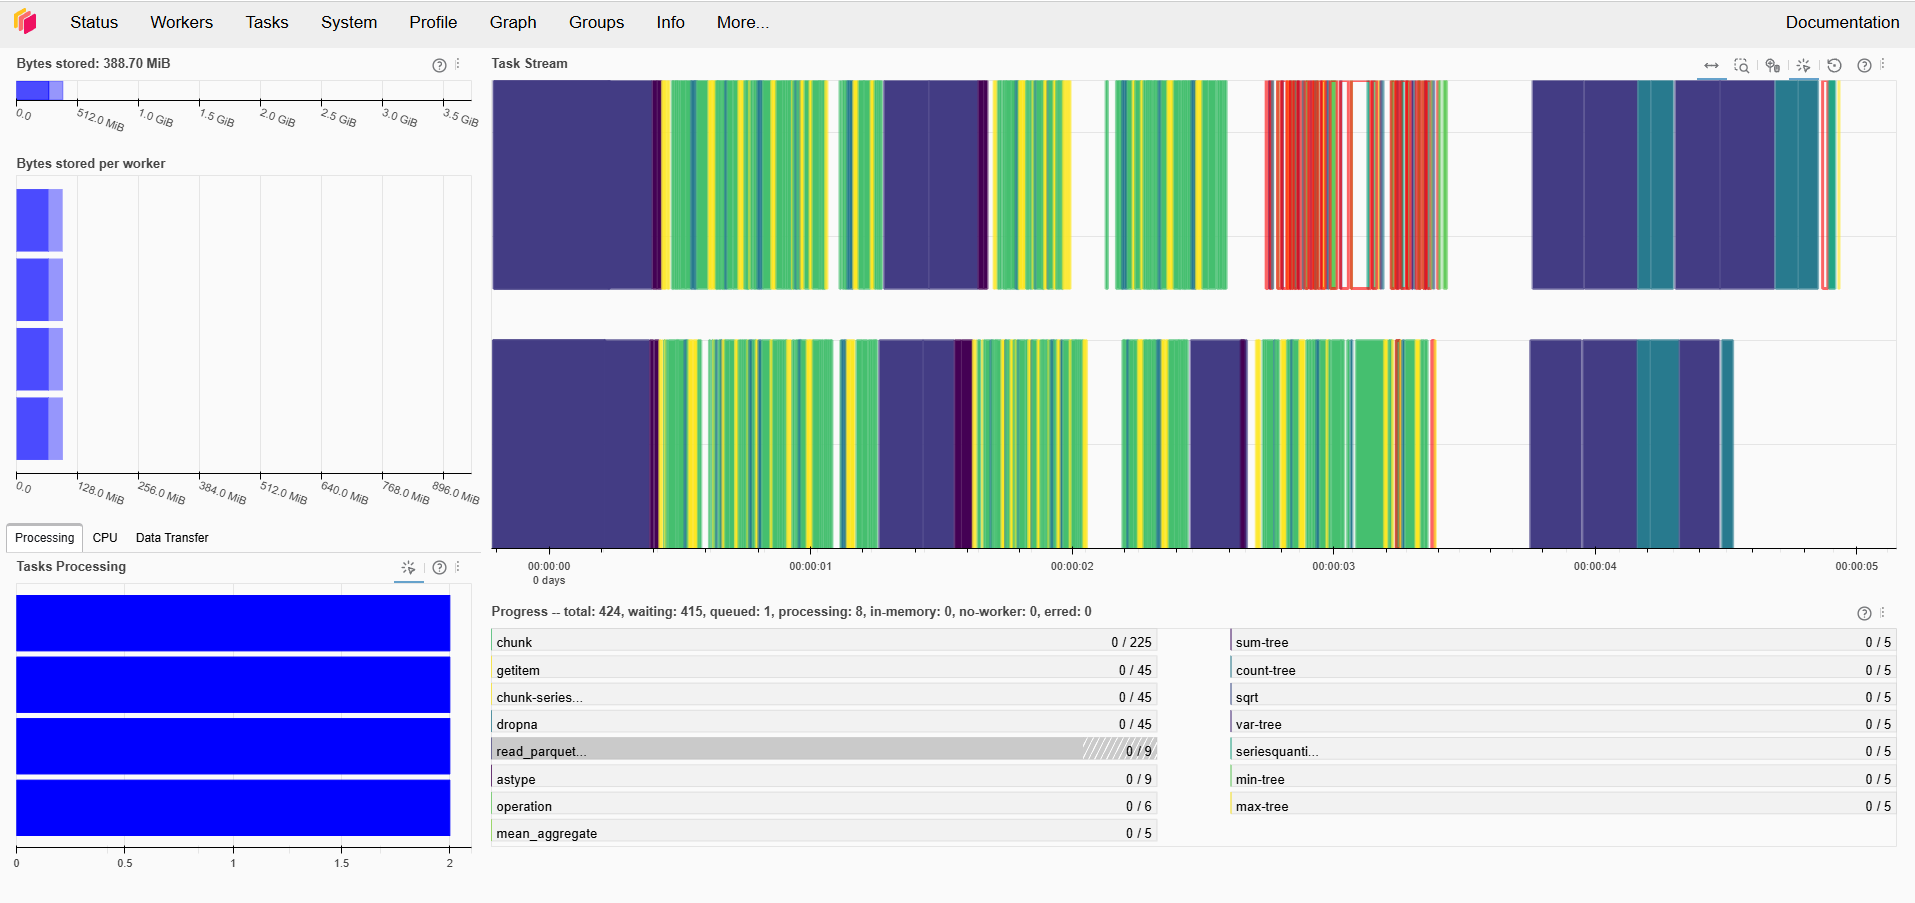

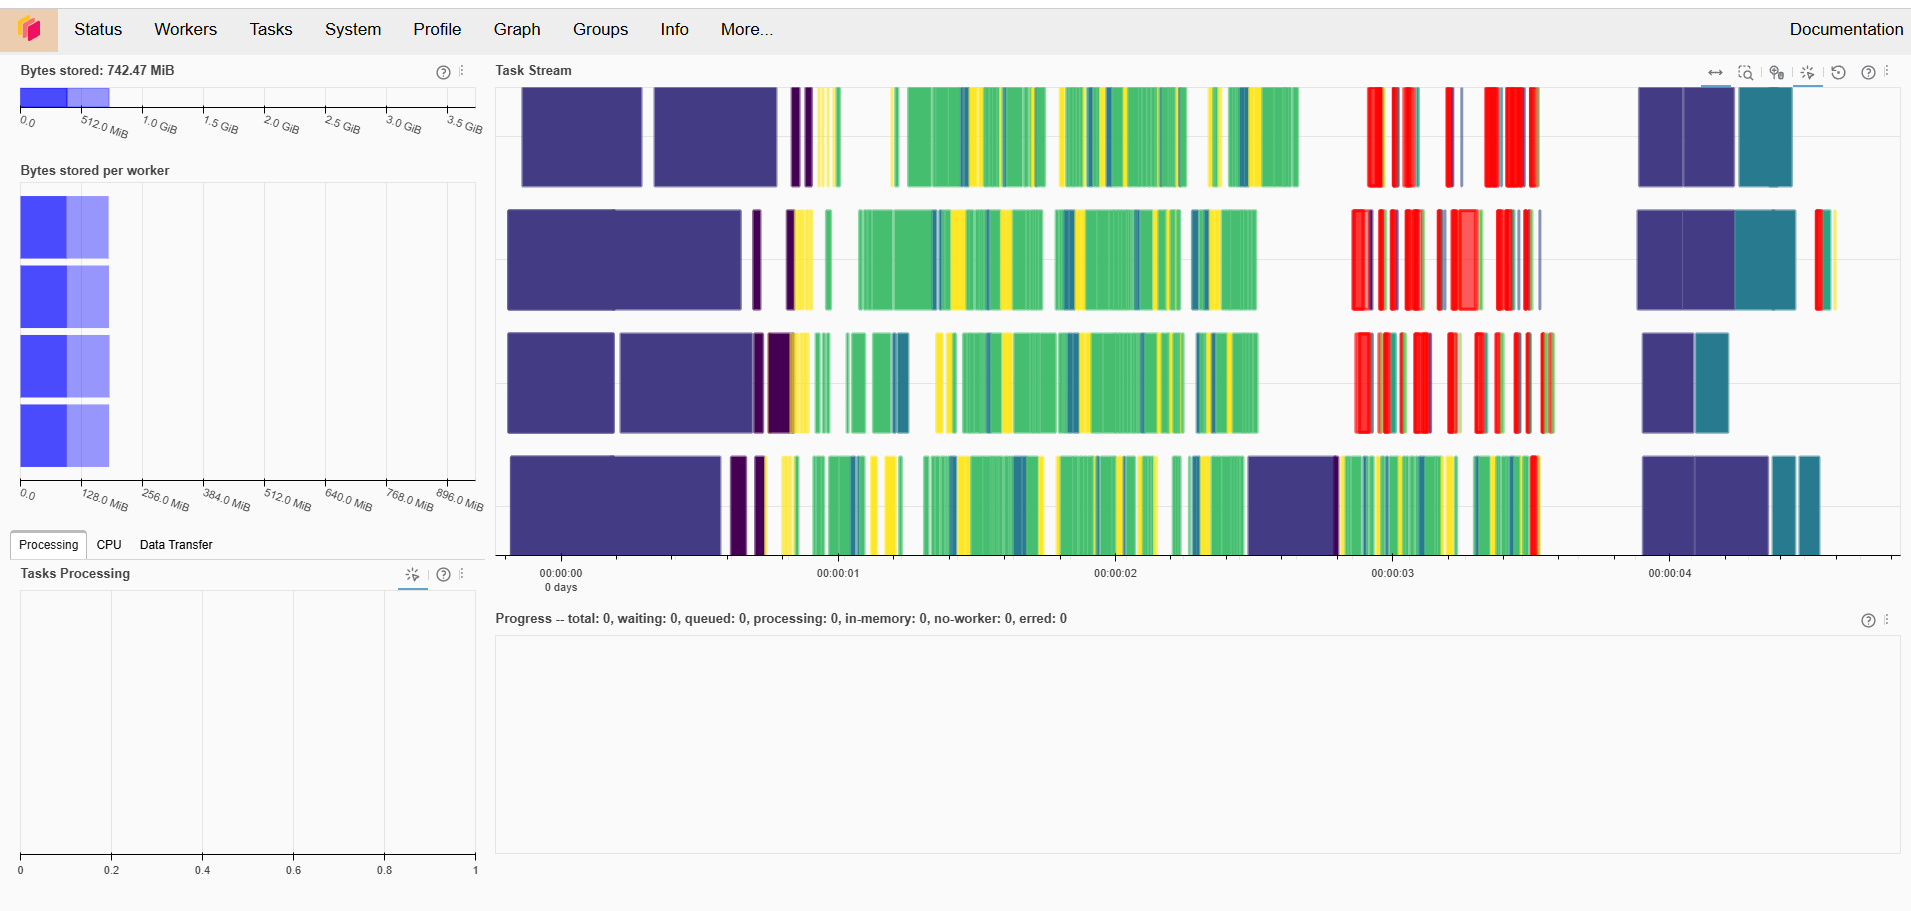

In [122]:
comparacion = pd.DataFrame([resultado1, resultado2])
comparacion

,Configuración,Workers,Hilos por worker,Memoria por worker (GB),Tiempo (s)
0,Configuración 1,2,1,2.0,18.94
1,Configuración 2,4,1,1.0,10.59


In [118]:
import os
print("Núcleos del equipo:", os.cpu_count())

Núcleos del equipo: 16


In [123]:
client.close()

Ambas configuraciones usan la misma memoria total (4 GB) y ejecutan la misma operación sobre las 2.072.049 reseñas limpias: estadísticas descriptivas de las variables numéricas y porcentaje de reseñas negativas por categoría. La configuración 2 fue un 44 % más rápida (10,59 s frente a 18,94 s), es decir, casi el doble de veloz.

La diferencia se explica por el paralelismo. Dask divide los datos en particiones y cada worker procesa una a la vez. Con 2 workers solo se procesan dos particiones en simultáneo; con 4 workers se procesan cuatro. Como el equipo tiene 16 núcleos, ninguna de las dos configuraciones agota la CPU, por lo que duplicar los workers permitió aprovechar más núcleos sin que compitieran entre sí. Además, 1 GB por worker fue suficiente para esta operación: cada partición y sus resultados intermedios son livianos, así que reducir la memoria por worker no afectó el rendimiento.

### **f. Base de datos en Amazon AWS con los resultados de la analítica**

En AWS se guardan únicamente los resultados del proceso analítico: tablas agregadas con los indicadores, el % de reseñas negativas por categoría, autor, editorial y periodo, y los patrones encontrados en el bivariado y el multivariado.


### Parámetros de conexión

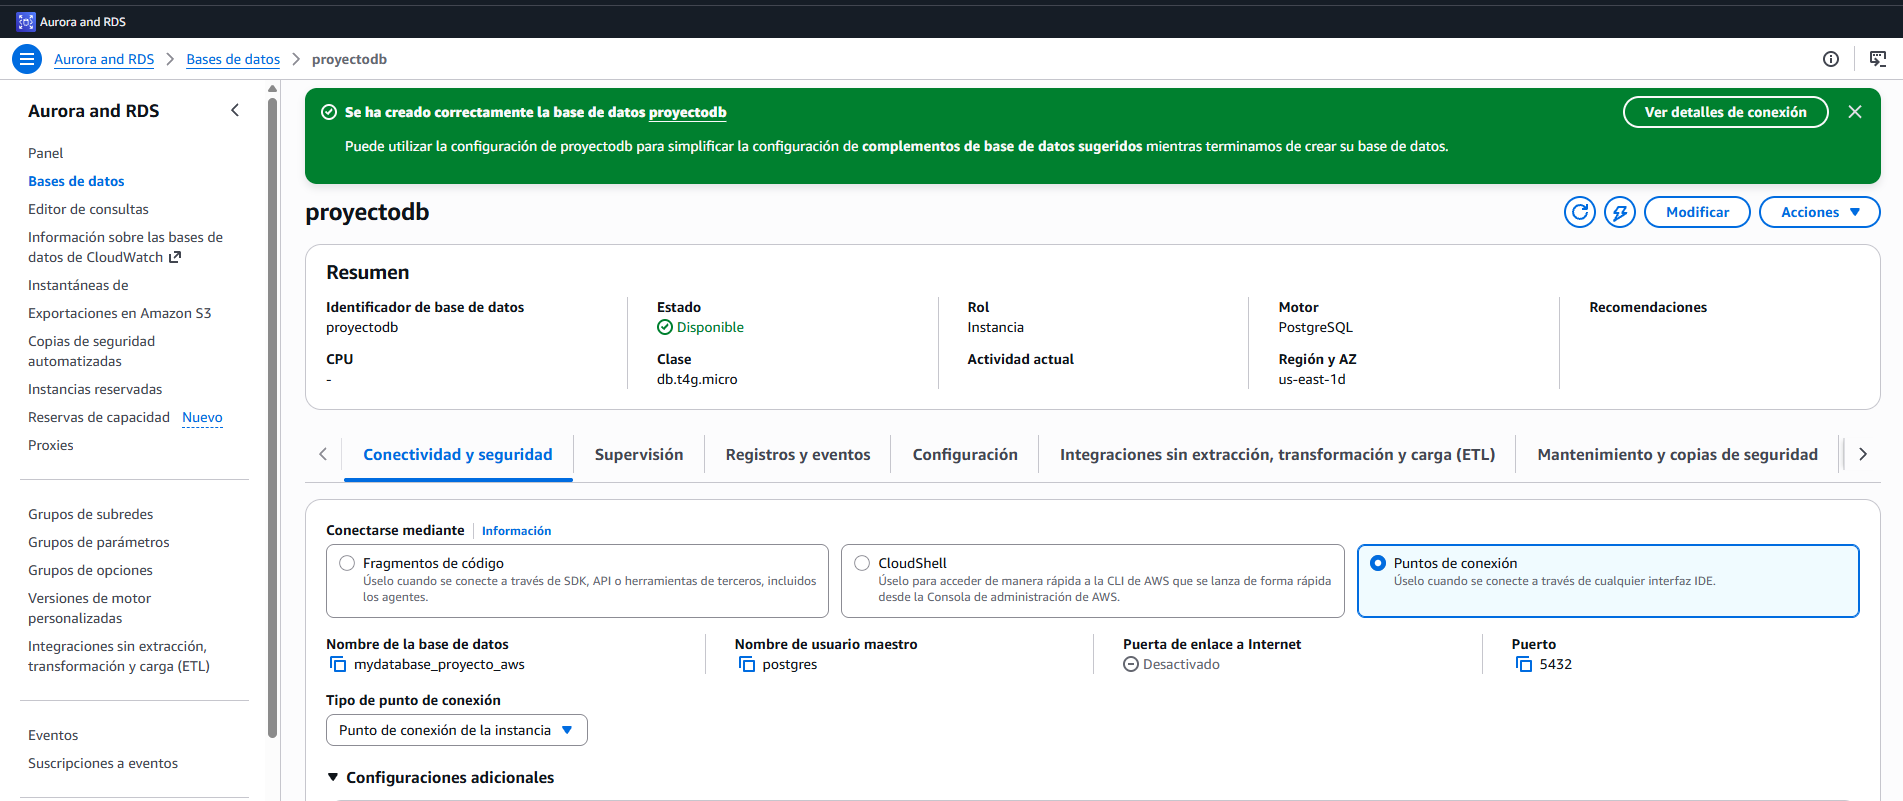


In [104]:
from sqlalchemy import create_engine, text

hostAWS = "proyectodb.cz4wgayocx8l.us-east-1.rds.amazonaws.com"
portAWS = '5432'
userAWS = 'postgres'
passwordAWS = 'unisabana'
databaseAWS = 'mydatabase_proyecto_aws'

- Crear la conexión (`create_engine`) y probarla

In [105]:
connDataWarehouse = create_engine(
    f"postgresql+psycopg2://{userAWS}:{passwordAWS}@{hostAWS}:{portAWS}/{databaseAWS}", echo=False)

with connDataWarehouse.connect() as conn:
    print("Connected")

Connected


#### Construir las tablas de resultados

Se calculan con DuckDB sobre las reseñas limpias. Cada tabla resume millones de reseñas en unas pocas filas. Solo se incluyen grupos con suficientes reseñas para que el porcentaje sea confiable (100 por categoría, autor o editorial; 50 por libro).

In [96]:
con.execute("""
    CREATE OR REPLACE VIEW reviews_clean AS
    SELECT *,
           strftime(review_date, '%Y-%m') AS anio_mes,
           CASE WHEN published_year BETWEEN 1800 AND 2013 AND review_year >= published_year
                THEN review_year - published_year END AS antiguedad_libro
    FROM reviews
""")

METRICAS = """COUNT(*) AS n_resenas,
       SUM(is_negative) AS n_negativas,
       ROUND(AVG(is_negative) * 100, 2) AS pct_negativas,
       ROUND(AVG(score), 3) AS score_medio,
       ROUND(AVG(text_len), 1) AS text_len_medio,
       ROUND(AVG(votes_total), 2) AS votes_total_medio,
       ROUND(AVG(helpful_ratio), 3) AS helpful_ratio_medio"""

TRAMO_VOTOS = """CASE WHEN votes_total = 0 THEN '01. 0' WHEN votes_total = 1 THEN '02. 1'
    WHEN votes_total = 2 THEN '03. 2' WHEN votes_total <= 5 THEN '04. 3-5'
    WHEN votes_total <= 10 THEN '05. 6-10' WHEN votes_total <= 20 THEN '06. 11-20'
    WHEN votes_total <= 50 THEN '07. 21-50' ELSE '08. >50' END"""
TRAMO_UTILIDAD = """CASE WHEN helpful_ratio IS NULL THEN NULL
    WHEN helpful_ratio <= 0.2 THEN '01. 0-20%' WHEN helpful_ratio <= 0.4 THEN '02. 20-40%'
    WHEN helpful_ratio <= 0.6 THEN '03. 40-60%' WHEN helpful_ratio <= 0.8 THEN '04. 60-80%'
    WHEN helpful_ratio <= 0.99 THEN '05. 80-99%' ELSE '06. 100%' END"""
TRAMO_LONGITUD = """CASE WHEN text_len IS NULL THEN NULL
    WHEN text_len <= 100 THEN '01. <100' WHEN text_len <= 250 THEN '02. 100-250'
    WHEN text_len <= 500 THEN '03. 250-500' WHEN text_len <= 1000 THEN '04. 500-1k'
    WHEN text_len <= 2000 THEN '05. 1k-2k' WHEN text_len <= 5000 THEN '06. 2k-5k' ELSE '07. >5k' END"""
TRAMO_ANTIGUEDAD = """CASE WHEN antiguedad_libro IS NULL THEN NULL
    WHEN antiguedad_libro = 0 THEN '01. Mismo año' WHEN antiguedad_libro <= 2 THEN '02. 1-2'
    WHEN antiguedad_libro <= 5 THEN '03. 3-5' WHEN antiguedad_libro <= 10 THEN '04. 6-10'
    WHEN antiguedad_libro <= 20 THEN '05. 11-20' ELSE '06. >20' END"""

def patron(expresion):
    return f"""SELECT {expresion} AS tramo, {METRICAS}
               FROM reviews_clean WHERE {expresion} IS NOT NULL
               GROUP BY tramo ORDER BY tramo"""

consultas = {
    "kpis": f"""SELECT {METRICAS}, COUNT(DISTINCT title_norm) AS n_libros,
                       COUNT(DISTINCT category_group) AS n_categorias,
                       ROUND(AVG(es_anonimo::INT) * 100, 2) AS pct_anonimas,
                       MIN(review_year) AS anio_min, MAX(review_year) AS anio_max
                FROM reviews_clean""",
    "distribucion_score": """SELECT CAST(score AS INT) AS score, COUNT(*) AS n_resenas,
                                    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct
                             FROM reviews_clean GROUP BY score ORDER BY score""",
    "negativas_por_categoria": f"""SELECT category_group, {METRICAS}, COUNT(DISTINCT title_norm) AS n_libros
                                   FROM reviews_clean GROUP BY category_group
                                   HAVING COUNT(*) >= 100 ORDER BY n_resenas DESC""",
    "negativas_por_categoria_anio": f"""SELECT category_group, review_year, {METRICAS}
                                        FROM reviews_clean WHERE review_year IS NOT NULL
                                        GROUP BY category_group, review_year
                                        HAVING COUNT(*) >= 100 ORDER BY category_group, review_year""",
    "negativas_por_editorial": f"""SELECT publisher_clean, {METRICAS}, COUNT(DISTINCT title_norm) AS n_libros
                                   FROM reviews_clean WHERE publisher_clean <> 'Desconocido'
                                   GROUP BY publisher_clean HAVING COUNT(*) >= 100 ORDER BY n_resenas DESC""",
    "negativas_por_autor": f"""SELECT main_author, {METRICAS}, COUNT(DISTINCT title_norm) AS n_libros
                               FROM reviews_clean WHERE main_author <> 'Desconocido'
                               GROUP BY main_author HAVING COUNT(*) >= 100 ORDER BY n_resenas DESC""",
    "serie_mensual": f"""SELECT anio_mes, {METRICAS}
                         FROM reviews_clean WHERE anio_mes IS NOT NULL
                         GROUP BY anio_mes ORDER BY anio_mes""",
    "top_libros_riesgo": f"""SELECT title_norm, ANY_VALUE(category_group) AS category_group,
                                    ANY_VALUE(main_author) AS main_author, {METRICAS}
                             FROM reviews_clean GROUP BY title_norm HAVING COUNT(*) >= 50
                             ORDER BY pct_negativas DESC, n_resenas DESC LIMIT 25""",
    "patron_votos": patron(TRAMO_VOTOS),
    "patron_utilidad": patron(TRAMO_UTILIDAD),
    "patron_longitud": patron(TRAMO_LONGITUD),
    "patron_antiguedad": patron(TRAMO_ANTIGUEDAD),
    "patron_anonimo": patron("CASE WHEN es_anonimo THEN 'Anónima' ELSE 'Identificada' END"),
    "patron_anio": patron("review_year"),
    "interaccion_votos_utilidad": f"""SELECT {TRAMO_VOTOS} AS tramo_votos, {TRAMO_UTILIDAD} AS tramo_utilidad, {METRICAS}
                                      FROM reviews_clean WHERE votes_total > 0 AND helpful_ratio IS NOT NULL
                                      GROUP BY tramo_votos, tramo_utilidad ORDER BY tramo_votos, tramo_utilidad""",
}

resultados = {nombre: con.sql(sql).df() for nombre, sql in consultas.items()}

resumen_tablas = pd.DataFrame({
    "tabla": list(resultados),
    "filas": [len(t) for t in resultados.values()],
    "columnas": [t.shape[1] for t in resultados.values()],
    "kb_en_memoria": [round(t.memory_usage(deep=True).sum() / 1024, 1) for t in resultados.values()],
})
print(f"{len(resultados)} tablas | {resumen_tablas['filas'].sum():,} filas en total | "
      f"{resumen_tablas['kb_en_memoria'].sum() / 1024:.2f} MB (frente a 2,9 GB del conjunto original)")
resumen_tablas

15 tablas | 4,965 filas en total | 0.41 MB (frente a 2,9 GB del conjunto original)


,tabla,filas,columnas,kb_en_memoria
0,kpis,1,12,0.2
1,distribucion_score,5,3,0.2
2,negativas_por_categoria,31,9,2.7
3,negativas_por_categoria_anio,528,9,41.9
4,negativas_por_editorial,1506,9,131.9
5,negativas_por_autor,2575,9,217.1
6,serie_mensual,212,8,14.8
7,top_libros_riesgo,25,10,3.6
8,patron_votos,8,8,0.7
9,patron_utilidad,6,8,0.6


#### Cargar los resultados en AWS

- Cada tabla se escribe con `to_sql`. Con `if_exists="replace"`, al volver a ejecutar la celda se reemplazan las tablas en vez de duplicar los registros.

In [98]:
for nombre, tabla in resultados.items():
    tabla.to_sql(nombre, connDataWarehouse, if_exists="replace",
                 index=False, chunksize=5000, method="multi")
    print(f"{nombre:30s} {len(tabla):>6,} filas")

kpis                                1 filas
distribucion_score                  5 filas
negativas_por_categoria            31 filas
negativas_por_categoria_anio      528 filas
negativas_por_editorial         1,506 filas
negativas_por_autor             2,575 filas
serie_mensual                     212 filas
top_libros_riesgo                  25 filas
patron_votos                        8 filas
patron_utilidad                     6 filas
patron_longitud                     7 filas
patron_antiguedad                   6 filas
patron_anonimo                      2 filas
patron_anio                        19 filas
interaccion_votos_utilidad         34 filas


- Sin embargo, también lo hicimos con la estructura vista en clase (Session y clases), para subir solo la tabla de reseñas negativas por categoría.

In [ ]:
from sqlalchemy import Column, Integer, String, Float
from sqlalchemy.orm import declarative_base, Session

Base = declarative_base()

class NegativasCategoria(Base):
    __tablename__ = "negativas_por_categoria_orm"

    id = Column(Integer, primary_key=True)
    category_group = Column(String(100))
    n_resenas = Column(Integer)
    n_negativas = Column(Integer)
    pct_negativas = Column(Float)
    score_medio = Column(Float)

Base.metadata.create_all(connDataWarehouse)

categorias = resultados["negativas_por_categoria"]

with Session(connDataWarehouse) as session:
    session.query(NegativasCategoria).delete()      # evita duplicar si se ejecuta de nuevo
    for index, row in categorias.iterrows():
        session.add(NegativasCategoria(
            category_group=row["category_group"],
            n_resenas=int(row["n_resenas"]),
            n_negativas=int(row["n_negativas"]),
            pct_negativas=float(row["pct_negativas"]),
            score_medio=float(row["score_medio"]),
        ))
    session.commit()

#### Verificar ambas cargas

Se consulta la base de datos en AWS para confirmar qué tablas quedaron y cuántas filas tiene cada una.

In [100]:
with connDataWarehouse.connect() as conn:
    tablas_aws = pd.read_sql(text("""
        SELECT table_name AS tabla
        FROM information_schema.tables
        WHERE table_schema = 'public'
        ORDER BY table_name
    """), conn)
    tablas_aws["filas_en_aws"] = [
        conn.execute(text(f'SELECT COUNT(*) FROM "{t}"')).scalar() for t in tablas_aws["tabla"]]

tablas_aws

,tabla,filas_en_aws
0,distribucion_score,5
1,interaccion_votos_utilidad,34
2,kpis,1
3,negativas_por_autor,2575
4,negativas_por_categoria,31
5,negativas_por_categoria_anio,528
6,negativas_por_editorial,1506
7,patron_anio,19
8,patron_anonimo,2
9,patron_antiguedad,6


In [ ]:
# categorías con más reseñas negativas
pd.read_sql(text("""
    SELECT id, category_group, n_resenas, pct_negativas
    FROM negativas_por_categoria_orm
    ORDER BY pct_negativas DESC
    LIMIT 10
"""), connDataWarehouse)

,id,category_group,n_resenas,pct_negativas
0,17,Political Science,20536,23.11
1,9,Computers,41407,18.52
2,30,Technology & Engineering,7898,14.92
3,23,Travel,12787,14.61
4,1,Fiction,514338,14.46
5,8,Business & Economics,59864,14.36
6,29,Foreign Language Study,8678,14.29
7,13,Social Science,25058,14.00
8,11,Family & Relationships,27009,13.34
9,19,Science,18803,12.48


En AWS quedaron solo las tablas de resultados del proceso analítico (alrededor de 1 MB), no las 3.000.000 de reseñas originales. Esta base de datos es la fuente del tablero gerencial en Grafana (punto g).


### **g. Dashboard interactivo con Dash**

Se construyó un tablero interactivo en Dash para consultar los resultados del análisis sin necesidad de ejecutar el notebook. Siguiendo la estructura del que se realizó en clase, organizada en archivos en la carpeta `dashboard/` (`app.py`, `configuracion.py`, `servicios/`, `components/` y `pages/`).

**Datos que usa.** El tablero lee los archivos Parquet de data/silver/reviews_libros con DuckDB y los carga una sola vez en memoria. Se usan 2.072.026 reseñas (las que tienen año y texto), de 31 grupos de categorías, entre 1995 y 2013. Para que los gráficos respondan rápido, además de las reseñas se arma un cubo agregado por categoría, año y número de estrellas, y una tabla de libros por año.

**Filtros.** En la parte superior hay dos filtros que comparten todas las páginas: el rango de años de la reseña y una o varias categorías. Cada vez que cambian, los callbacks recalculan los indicadores y los gráficos.

**Páginas y visualizaciones**

1. **Inicio**
   - Cinco indicadores: reseñas analizadas, % de reseñas negativas, calificación media, libros reseñados y % de reseñas anónimas.
   - Evolución anual: barras con el número de reseñas y una línea con el % de negativas por año.
   - Distribución de estrellas de 1 a 5.
   - % de reseñas negativas por categoría (solo categorías con al menos 2.000 reseñas), con una línea que marca el promedio del filtro.
   - Tabla de libros en alerta: los libros con mayor % de reseñas negativas, entre los que tienen al menos 50 reseñas.
   - Autores con mayor % de reseñas negativas

2. **Mapa de reseñas**
   - Como los datos no tienen ubicación geográfica, el "mapa" es un plano donde cada reseña es un punto según la longitud de su texto (eje horizontal) y los votos que recibió (eje vertical), ambos en escala logarítmica.
   - Con Datashader, los más de 2 millones de puntos se agregan en el servidor en una cuadrícula de 320 × 220 celdas, y al navegador solo llega esa cuadrícula (70.400 celdas) como mapa de calor.
   - El mapa se puede colorear por cantidad de reseñas, por % de reseñas negativas o por utilidad promedio. Las celdas con menos de 20 reseñas no se colorean en los modos de porcentaje, para no mostrar porcentajes poco confiables.

3. **Votos y Utilidad**
   - % de reseñas negativas segun los votos recibidos
   - % de reseñas negativas de acuerdo a la proporción de utilidad
   - Votos x utilidad (como se comporta la cantidad de votos Vs. la percepción de utilidad)

4. **Comparación**
   - Permite escoger dos categorías y verlas frente a frente: % de negativas, número de reseñas y calificación media, la evolución anual del % de negativas y la distribución de estrellas de cada una.



- La mayoría de las reseñas tiene textos de entre 100 y 2.000 caracteres y pocos votos. En el mapa, la zona más densa está abajo, en las reseñas con 0 a 5 votos.
- Al colorear el mapa por % de negativas, la parte superior (reseñas con muchos votos) se ve mucho más roja que la inferior. Es el mismo hallazgo del análisis bivariado: las reseñas negativas reciben más votos y generan más desacuerdo.
- En la comparación, *Computers* tiene 18,5 % de reseñas negativas frente a 7,3 % de *Juvenile Fiction*, y la diferencia se mantiene en todos los años.
- La serie anual muestra el pico de insatisfacción entre 2003 y 2004 (alrededor de 15 %) y la caída en 2013, que es un año incompleto.


Se debe ejecutar la siguiente celda para obtener el link del dashboard:

In [98]:
import subprocess, sys, time, urllib.request
from IPython.display import display, Markdown

CARPETA_DASHBOARD = RAIZ / "dashboard"
URL = "http://127.0.0.1:8050"

proceso_dash = subprocess.Popen([sys.executable, "app.py"], cwd=CARPETA_DASHBOARD)


for segundo in range(180):
    if proceso_dash.poll() is not None:
        print("El tablero se detuvo. Revisa que el puerto 8050 esté libre y ejecuta app.py desde la terminal para ver el error.")
        break
    try:
        urllib.request.urlopen(URL, timeout=1)
        display(Markdown(f"### Tablero listo: [{URL}]({URL})"))
        break
    except Exception:
        time.sleep(1)

### Tablero listo: [http://127.0.0.1:8050](http://127.0.0.1:8050)

Y la siguiente, para finalizar el dashboard:

In [95]:
proceso_dash.terminate()
proceso_dash.wait()
print("Tablero detenido")

Tablero detenido


### **h. Conclusiones**

**¿Qué se asocia con la insatisfacción del lector?**

1. **La mayoría de la gente está contenta, y eso hay que tenerlo en cuenta.** Casi el 60 % de las reseñas tiene 5 estrellas y solo el 12,4 % es negativa (1 o 2 estrellas). Las calificaciones tienen forma de J: la gente suele escribir cuando algo le encantó o cuando la decepcionó mucho, casi nunca para decir "estuvo normal". Por eso el promedio de 4,19 dice poco, y tenía más sentido trabajar con una variable que separa negativas de positivas.

2. **Lo que más delata una reseña negativa es la reacción de los demás lectores.** Sin votos, solo el 4,8 % de las reseñas es negativo. Con más de 50 votos, el 40,8 % lo es. Pero no se trata de que tengan muchos votos, sino de que esos votos dicen "no fue útil": cuando una reseña tiene más de 50 votos y menos del 40 % la considera útil, entre el 84 % y el 87 % son negativas. Es decir, las críticas generan polémica, y los lectores a los que sí les gustó el libro salen a votarlas en contra. Eso sí, los votos llegan después de publicar la reseña, así que sirven para explicar la insatisfacción, no para anticiparla.

3. **Algunas categorías y autores sí molestan más que otros.** *Computers* (18,5 %) y *Political Science* (23,1 %) tienen muchas más reseñas negativas que *Juvenile Fiction* (7,3 %) o *Poetry* (8,0 %). Pero al controlar las demás variables, el caso de *Political Science* se explica más por lo polémicas que son sus reseñas que por la categoría en sí. *Computers* es la única que sigue siendo más negativa por sí misma, probablemente porque los libros técnicos se desactualizan rápido o no cumplen lo que prometen. En autores pasa algo parecido: sagas largas y autores de producción masiva (Robert Jordan, Tom Clancy, James Patterson) o autores políticos (Sean Hannity, Ann Coulter) concentran mucha insatisfacción, mientras que J. K. Rowling o Louis Sachar casi no tienen reseñas negativas.

4. **Las reseñas anónimas son más duras.** Tienen 15,4 % de negativas frente a 11,7 % de las identificadas. Tiene lógica, ya que sin un nombre, la gente se siente más libre de criticar.

5. **Hay cosas que pensábamos que influían y casi no influyen.** La longitud del texto apenas cambia la tasa de negativas, y la antigüedad del libro tiene un efecto muy débil (los clásicos reciben un poco menos de críticas, pero esa variable tiene la mitad de los datos vacíos). También vimos que los libros sin categoría tienen la misma tasa de negativas que el resto (12,2 % frente a 12,4 %), así que los datos faltantes no sesgan los resultados.

**¿Qué aprendimos de los datos?**

6. **Los datos venían más sucios de lo que parecía.** El 30,9 % de las filas eran la misma reseña repetida para distintas ediciones del libro, después de quitarlas quedaron 2.072.049 reseñas únicas. También aparecieron errores puntuales, como un libro publicado "en el año 1016" (en realidad, 1996) o votos útiles mayores que los votos totales.

7. **Faltan datos importantes para ir más allá.** El precio falta en el 80 % de las reseñas, una parte de los libros no tiene categoría, autor o editorial, y los datos llegan solo hasta 2013. Para explicar el porqué de la insatisfacción, el siguiente paso sería analizar el texto de las reseñas.

**¿Qué aprendimos de las herramientas?**

8. **Trabajar con 3 GB exige otras herramientas.** Con Dask pudimos leer y limpiar los archivos por bloques sin que el computador colapsara, y vimos que la forma de repartir los recursos importa: con la misma memoria total (4 GB), 4 workers de 1 GB fueron un 44 % más rápidos que 2 de 2 GB. DuckDB sobre Parquet hizo que las consultas sobre 2 millones de reseñas tardaran poco.

9.  El flujo de Prefect repite la limpieza y calcula los libros en alerta y las negativas por año de publicación cada vez que se ejecuta. Si llegan más datos con la misma estructura, solo se debe dejarlos en la carpeta y correrlo de nuevo.

10. En AWS quedaron 16 tablas de resultados en vez de los 3 GB originales. Es más barato, más rápido de consultar y es lo que realmente necesita alguien que vaya a tomar decisiones.

11. **El tablero junta todo en un solo lugar.** Con Dash y Datashader, cualquier persona puede explorar los hallazgos por año y categoría, ver los libros y autores en alerta, comparar categorías y ver en el mapa los 2 millones de reseñas sin que el navegador se bloquee.

**Asi pues, la insatisfacción del lector depende menos del libro en sí y más de cómo reacciona la comunidad frente a la reseña. Aun así, hay categorías, como los libros de computación, y autores puntuales que concentran las críticas y valdría la pena revisar en el catálogo.**